# Trabajo Práctico 01 — Preprocesamiento y transformación de datos

**Bases de Datos Masivas (11088)** — Departamento de Ciencias Básicas
**2° Cuatrimestre 2026** — Universidad Nacional de Luján

---

**Alumno/a:** Federico Kasparian
**Fecha de entrega:** 14 / 09 / 2026

---

## Índice

**Parte 1 — Ruido, outliers y transformación**

1. [Manejo de ruido (`calidad_aire.csv`)](#ej1)
2. [Detección de outliers (`clima_smn.csv`)](#ej2)
3. [Discretización (`clima_smn.csv`)](#ej3)
4. [Normalización (`clima_smn.csv`)](#ej4)

**Parte 2 — Faltantes y reducción de dimensionalidad**

5. [Datos faltantes (`alquileres.csv`)](#ej5)
6. [Análisis de Componentes Principales (`vehiculos.csv`)](#ej6)

[Conclusiones generales](#conclusiones)

---

### Nota metodológica

Todo el desarrollo se realiza con **Pandas / NumPy / SciPy / scikit-learn**. Las funciones de
*binning*, *hot deck* e imputación por regresión se implementan explícitamente (no se usan
atajos de librerías donde la consigna pide construir el método), y luego se contrastan contra
las implementaciones de referencia de scikit-learn.

Los gráficos se generan con Matplotlib. Cada consigna se responde inmediatamente debajo del
código correspondiente, en celdas de texto tituladas **Respuesta**.

## Configuración del entorno y carga de datos

El notebook busca los archivos en la carpeta `data/`. Si no los encuentra, los descarga
directamente del repositorio de la materia, de modo que sea ejecutable de punta a punta sin
preparación previa.

In [1]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy import stats

warnings.filterwarnings("ignore")
%matplotlib inline

# --- Estilo unificado para todos los gráficos -------------------------------
mpl.rcParams.update({
    "figure.figsize": (11, 4.2),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "font.size": 9,
})
AZUL, NARANJA, VERDE, ROJO, GRIS = "#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#7f7f7f"

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.2 | numpy 2.4.4


In [2]:
DATA_DIR = Path("data")
BASE_URL = "https://raw.githubusercontent.com/bdm-unlu/2026/main/TPs/TP01/data/"

def cargar(nombre, **kwargs):
    ruta = DATA_DIR / nombre
    origen = str(ruta) if ruta.exists() else BASE_URL + nombre
    df = pd.read_csv(origen, **kwargs)
    print(f"{nombre:<20} {df.shape[0]:>6,} filas x {df.shape[1]:>2} columnas   (origen: "
          f"{'local' if ruta.exists() else 'GitHub'})")
    return df

aire       = cargar("calidad_aire.csv", parse_dates=["fecha"])
clima      = cargar("clima_smn.csv",    parse_dates=["fecha"])
alquileres = cargar("alquileres.csv")
vehiculos  = cargar("vehiculos.csv")

calidad_aire.csv      5,484 filas x 11 columnas   (origen: local)
clima_smn.csv        23,019 filas x  9 columnas   (origen: local)
alquileres.csv       29,438 filas x 16 columnas   (origen: local)
vehiculos.csv         2,809 filas x 17 columnas   (origen: local)


<a id="ej1"></a>

---

# Parte 1 — Manejo de ruido, outliers y transformación de datos

# Ejercicio 1 — Manejo de ruido

**Dataset:** `calidad_aire.csv` — 5.484 registros horarios (enero a agosto de 2026) de tres
contaminantes (CO en ppm, NO₂ en ppb y PM10 en µg/m³) medidos en tres estaciones de la red de
monitoreo atmosférico del GCBA (Centenario, Córdoba y La Boca).

## 1.a — Características y distribución de las variables

Se describe la estructura del dataset, el tipo y rango de cada variable, la cantidad de
faltantes, y se evalúa la normalidad mediante gráficos Q-Q complementados con los coeficientes
de asimetría y curtosis y el test de Shapiro-Wilk.

In [3]:
print(aire.dtypes.to_string())
print("\nPeríodo cubierto:", aire["fecha"].min().date(), "a", aire["fecha"].max().date())
print("Horas presentes  :", sorted(aire["hora"].unique()))
aire.head()

fecha              datetime64[us]
hora                        int64
co_centenario             float64
no2_centenario            float64
pm10_centenario           float64
co_cordoba                float64
no2_cordoba               float64
pm10_cordoba              float64
co_la_boca                float64
no2_la_boca               float64
pm10_la_boca              float64

Período cubierto: 2026-01-01 a 2026-08-18
Horas presentes  : [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24)]


,fecha,hora,co_centenario,no2_centenario,pm10_centenario,co_cordoba,no2_cordoba,pm10_cordoba,co_la_boca,no2_la_boca,pm10_la_boca
0,2026-01-01,1,NaN,6.0000,NaN,0.2800,13.0000,42.0000,0.4300,9.0000,37.0000
1,2026-01-01,2,0.3800,8.0000,NaN,0.3000,15.0000,44.0000,0.4200,11.0000,37.0000
2,2026-01-01,3,0.3500,14.0000,NaN,0.3200,14.0000,45.0000,0.4100,11.0000,38.0000
3,2026-01-01,4,0.3000,23.0000,NaN,0.3300,16.0000,46.0000,0.3900,13.0000,39.0000
4,2026-01-01,5,0.2200,7.0000,NaN,0.2700,9.0000,48.0000,0.3400,11.0000,42.0000


In [4]:
CONTAM = ["co_centenario", "no2_centenario", "pm10_centenario",
          "co_cordoba",    "no2_cordoba",    "pm10_cordoba",
          "co_la_boca",    "no2_la_boca",    "pm10_la_boca"]

resumen = aire[CONTAM].describe().T
resumen["faltantes"]   = aire[CONTAM].isna().sum()
resumen["% faltantes"] = (100 * aire[CONTAM].isna().mean()).round(1)
resumen["rango"]       = resumen["max"] - resumen["min"]
resumen["CV"]          = (resumen["std"] / resumen["mean"]).round(2)
resumen[["count", "faltantes", "% faltantes", "mean", "std", "CV",
         "min", "25%", "50%", "75%", "max", "rango"]].round(2)

,count,faltantes,% faltantes,mean,std,CV,min,25%,50%,75%,max,rango
co_centenario,"5,395.0000",89,1.6000,0.4400,0.2100,0.4800,0.0600,0.3000,0.4000,0.5300,1.5700,1.5100
no2_centenario,"5,379.0000",105,1.9000,13.3200,6.1400,0.4600,2.0000,9.0000,13.0000,17.0000,43.0000,41.0000
pm10_centenario,"5,092.0000",392,7.1000,22.0700,9.3500,0.4200,6.0000,15.0000,20.0000,27.0000,60.0000,54.0000
co_cordoba,"5,484.0000",0,0.0000,0.6400,0.3300,0.5200,0.0300,0.3800,0.5900,0.8500,2.0700,2.0400
no2_cordoba,"5,436.0000",48,0.9000,19.1200,8.8400,0.4600,0.0000,13.0000,18.0000,24.0000,88.0000,88.0000
pm10_cordoba,"5,197.0000",287,5.2000,26.8600,9.4700,0.3500,9.0000,20.0000,25.0000,32.0000,62.0000,53.0000
co_la_boca,"5,053.0000",431,7.9000,0.3300,0.4900,1.4900,0.0600,0.2000,0.2700,0.3700,23.0000,22.9400
no2_la_boca,"5,071.0000",413,7.5000,25.1600,9.9800,0.4000,5.0000,18.0000,24.0000,31.0000,73.0000,68.0000
pm10_la_boca,"4,702.0000",782,14.3000,25.6900,11.6200,0.4500,3.0000,17.0000,24.0000,33.0000,74.0000,71.0000


In [5]:
# Asimetría, curtosis y test de normalidad de Shapiro-Wilk
filas = []
for v in CONTAM:
    s = aire[v].dropna()
    muestra = s.sample(4500, random_state=7) if len(s) > 4500 else s   # límite de Shapiro
    W, p = stats.shapiro(muestra)
    filas.append({"variable": v, "n": len(s), "media": s.mean(), "desvío": s.std(),
                  "asimetría": stats.skew(s), "curtosis": stats.kurtosis(s),
                  "W (Shapiro)": W, "p-valor": p})
norm = pd.DataFrame(filas).set_index("variable")
norm.style.format({"media": "{:.3f}", "desvío": "{:.3f}", "asimetría": "{:.2f}",
                   "curtosis": "{:.2f}", "W (Shapiro)": "{:.3f}", "p-valor": "{:.2e}"})

,n,media,desvío,asimetría,curtosis,W (Shapiro),p-valor
variable,,,,,,,
co_centenario,5395,0.442,0.211,1.50,3.32,0.894,2.62e-48
no2_centenario,5379,13.322,6.135,0.55,0.14,0.972,6.51e-29
pm10_centenario,5092,22.065,9.353,1.04,0.81,0.921,1.56e-43
co_cordoba,5484,0.645,0.333,0.82,0.61,0.952,3.64e-36
no2_cordoba,5436,19.123,8.837,1.52,5.78,0.914,5.85e-45
pm10_cordoba,5197,26.855,9.475,0.99,0.61,0.927,2.64e-42
co_la_boca,5053,0.329,0.491,39.14,1796.29,0.226,3.60e-87
no2_la_boca,5071,25.156,9.983,0.83,1.59,0.962,8.43e-33
pm10_la_boca,4702,25.693,11.623,0.93,1.07,0.949,5.37e-37


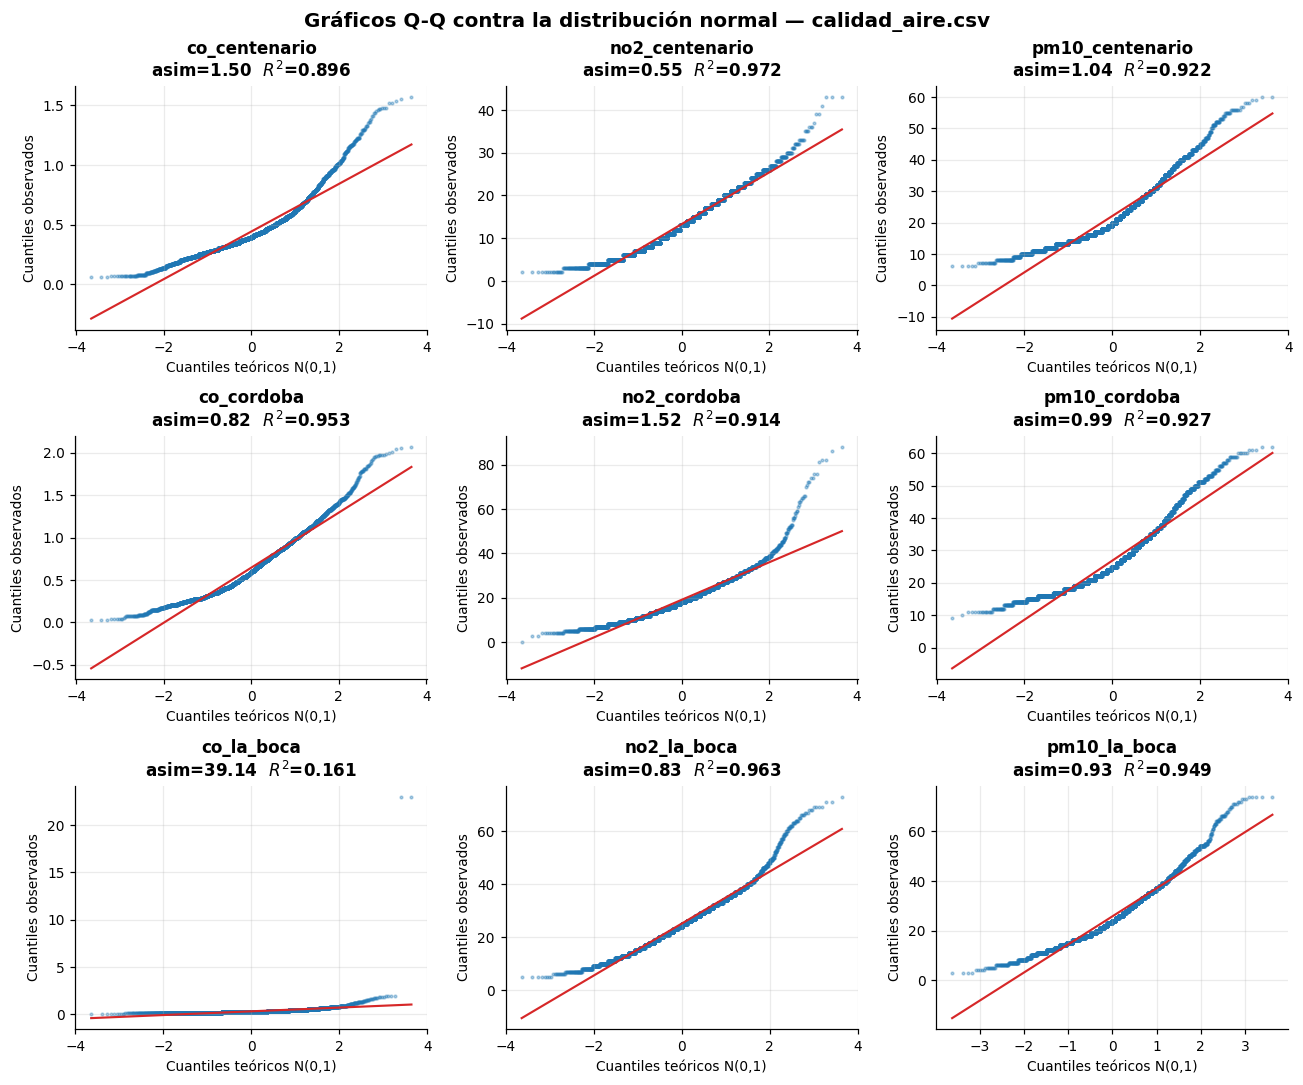

Asimetría antes y después de aplicar log(x + 0,01):

  co_cordoba         0.82  ->   -0.53
  pm10_cordoba       0.99  ->    0.27
  no2_cordoba        1.52  ->   -0.97
  pm10_la_boca       0.93  ->   -0.38


In [6]:
fig, axes = plt.subplots(3, 3, figsize=(12, 10))
for ax, v in zip(axes.ravel(), CONTAM):
    s = aire[v].dropna()
    (osm, osr), (pend, orden, r) = stats.probplot(s, dist="norm")
    ax.scatter(osm, osr, s=3, color=AZUL, alpha=.35)
    ax.plot(osm, pend * osm + orden, color=ROJO, lw=1.4)
    ax.set_title(f"{v}\nasim={stats.skew(s):.2f}  $R^2$={r**2:.3f}")
    ax.set_xlabel("Cuantiles teóricos N(0,1)"); ax.set_ylabel("Cuantiles observados")
fig.suptitle("Gráficos Q-Q contra la distribución normal — calidad_aire.csv",
             fontsize=13, fontweight="bold")
fig.tight_layout(); plt.show()

# ¿Se acercarían a la normal con una transformación logarítmica?
print("Asimetría antes y después de aplicar log(x + 0,01):\n")
for v in ["co_cordoba", "pm10_cordoba", "no2_cordoba", "pm10_la_boca"]:
    s_ = aire[v].dropna()
    print(f"  {v:<16} {stats.skew(s_):>6.2f}  ->  {stats.skew(np.log(s_ + .01)):>6.2f}")

Diez valores más altos de co_la_boca: [23.0, 23.0, 1.92, 1.92, 1.92, 1.9, 1.84, 1.82, 1.82, 1.81]

Registros con CO > 2 ppm en La Boca:
     fecha  hora  co_la_boca  co_cordoba  co_centenario
2026-06-01     6     23.0000      0.6400         0.7400
2026-06-01     7     23.0000      0.7300         0.7000


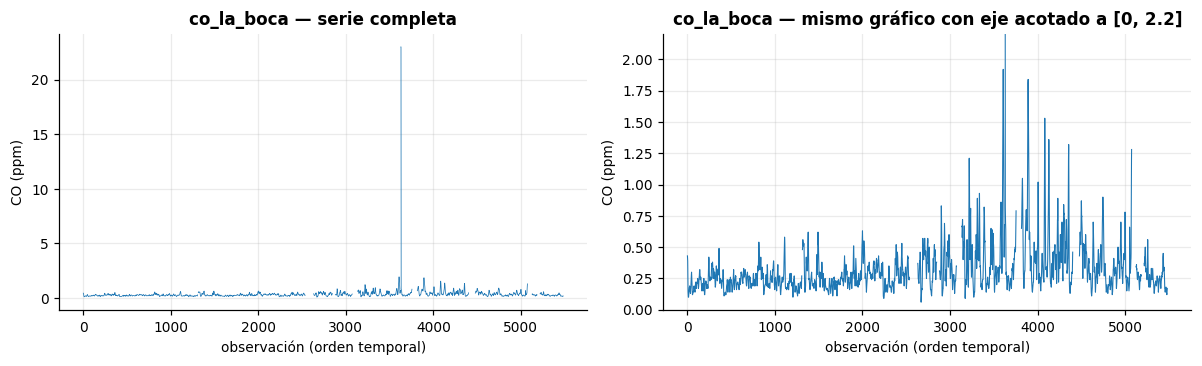

In [7]:
# El caso co_la_boca merece un zoom: su asimetría (39) delata un valor puntual anómalo
s = aire["co_la_boca"]
print("Diez valores más altos de co_la_boca:", s.nlargest(10).round(2).tolist())
print("\nRegistros con CO > 2 ppm en La Boca:")
print(aire.loc[s > 2, ["fecha", "hora", "co_la_boca", "co_cordoba", "co_centenario"]].to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(s.values, lw=.5, color=AZUL); axes[0].set_title("co_la_boca — serie completa")
axes[1].plot(s.values, lw=.7, color=AZUL); axes[1].set_ylim(0, 2.2)
axes[1].set_title("co_la_boca — mismo gráfico con eje acotado a [0, 2.2]")
for ax in axes: ax.set_xlabel("observación (orden temporal)"); ax.set_ylabel("CO (ppm)")
fig.tight_layout(); plt.show()

### Respuesta 1.a

**Características de las variables.** El dataset combina dos identificadores temporales
(`fecha`, tipo fecha, y `hora`, entero discreto de 1 a 24) con nueve variables **numéricas
continuas de razón** —tienen cero absoluto y admiten cocientes—, una por cada combinación de
contaminante y estación. Las unidades son heterogéneas y no comparables entre sí: CO en ppm
(valores en torno a 0,3–0,6), NO₂ en ppb (13–25) y PM10 en µg/m³ (22–27). Esa diferencia de
escala de dos órdenes de magnitud anticipa la necesidad de normalizar antes de cualquier
análisis conjunto (Ejercicio 4) o de cualquier técnica basada en distancias o varianzas
(Ejercicio 6).

Todas las variables presentan **datos faltantes**, entre el 0 % de `co_cordoba` y el 14,3 % de
`pm10_la_boca`. El patrón no es aleatorio: se concentra por estación (La Boca acumula los
mayores porcentajes) y por contaminante (PM10 es el más incompleto en las tres estaciones), lo
que sugiere períodos de calibración o falla de instrumentos antes que pérdidas al azar.

**Distribución.** Ninguna variable es normal. Los gráficos Q-Q muestran el patrón típico de
**asimetría positiva**: la nube se despega de la recta teórica en el extremo superior,
curvándose hacia arriba, lo que indica una cola derecha más pesada que la de una normal. Es el
comportamiento esperable de una concentración de contaminante, que está acotada inferiormente
por cero y ocasionalmente se dispara con episodios de tráfico intenso o inversión térmica. Los
coeficientes lo confirman: la asimetría es positiva en las nueve variables (entre 0,55 y 1,52
si se excluye el caso anómalo) y la curtosis es positiva en ocho de nueve. El test de
Shapiro-Wilk rechaza la normalidad en todos los casos con p-valores del orden de 10⁻³⁰ o
menores, aunque con n ≈ 5.000 el test es tan sensible que conviene apoyarse sobre todo en la
lectura gráfica.

Hay grados de severidad. `no2_centenario` (asimetría 0,55; R² = 0,972) es lo más cercano a una
normal y su Q-Q es casi recto. Los CO y PM10 son claramente asimétricos y se acercarían mucho a
la normalidad con una transformación logarítmica (verificado más abajo: log(`pm10_cordoba`)
baja su asimetría de 0,99 a 0,27).

**El caso `co_la_boca` es distinto y es el hallazgo central del punto.** Su asimetría de 39,1 y
su curtosis de 1.796 no describen una cola pesada sino **ruido puro**: dos registros
consecutivos (1 de junio de 2026, horas 6 y 7) valen 23,0 ppm cuando la mediana de la serie es
0,27 ppm y el resto del máximo histórico no supera 1,92 ppm. Un valor casi ochenta veces
superior a la mediana, sostenido exactamente dos horas y sin correlato en las otras dos
estaciones el mismo día, no es un episodio de contaminación real sino un **error de medición**
(muy probablemente un corrimiento de coma decimal o una falla del sensor). El Q-Q de esa
variable queda completamente distorsionado: todos los puntos se aplastan contra una línea
horizontal porque la escala del eje la fijan dos observaciones. Este es precisamente el tipo de
ruido que las técnicas de suavizado de los puntos siguientes deben atenuar.

## 1.b — Suavizado por *binning* de frecuencias iguales, estimando por medias

El *binning* de **frecuencias iguales** (o *equal-depth*) reparte las observaciones en bins que
contienen **la misma cantidad de elementos**. Cada valor se reemplaza luego por un estadístico
del bin al que pertenece —aquí, la **media**.

Se implementan las funciones de forma explícita. Un punto metodológico importante: el
procedimiento canónico (Han & Kamber) **ordena los datos por valor** antes de particionar,
mientras que sobre una serie temporal el suavizado tiene sentido aplicado **en el orden
cronológico**, donde cada bin agrupa horas vecinas. Ambas variantes se implementan y se
comparan, porque producen resultados conceptualmente distintos.

In [8]:
def bin_frecuencias_iguales(serie, profundidad, estimador="media", ordenar_por_valor=True):
    '''
    Suavizado por binning de frecuencias iguales (equal-depth).

    profundidad       : cantidad de observaciones por bin
    estimador         : 'media' | 'mediana' | 'extremos'
    ordenar_por_valor : True  -> se ordena por valor antes de particionar (Han & Kamber)
                        False -> se respeta el orden original de la serie (temporal)

    Devuelve la serie suavizada, alineada con el índice original.
    '''
    s = serie.dropna()
    orden = s.sort_values(kind="mergesort").index if ordenar_por_valor else s.index
    s_ord = s.loc[orden]
    etiqueta = np.arange(len(s_ord)) // profundidad          # bins consecutivos

    g = s_ord.groupby(etiqueta)
    if estimador == "media":
        suave = g.transform("mean")
    elif estimador == "mediana":
        suave = g.transform("median")
    elif estimador == "extremos":
        lo, hi = g.transform("min"), g.transform("max")
        suave = np.where((s_ord - lo).abs() <= (hi - s_ord).abs(), lo, hi)
        suave = pd.Series(suave, index=s_ord.index)
    else:
        raise ValueError("estimador debe ser 'media', 'mediana' o 'extremos'")

    return suave.reindex(serie.index)


def bin_anchos_iguales(serie, n_bins, estimador="extremos"):
    '''
    Suavizado por binning de anchos iguales (equal-width): el RANGO de la variable se parte
    en n_bins intervalos de igual amplitud y cada valor se reemplaza por un estadístico
    de su intervalo. Por defecto, suavizado por extremos (bin boundaries).
    '''
    s = serie.dropna()
    bordes = np.linspace(s.min(), s.max(), n_bins + 1)
    etiqueta = np.clip(np.digitize(s, bordes[1:-1]), 0, n_bins - 1)

    g = s.groupby(etiqueta)
    if estimador == "media":
        suave = g.transform("mean")
    elif estimador == "mediana":
        suave = g.transform("median")
    elif estimador == "extremos":
        lo, hi = g.transform("min"), g.transform("max")
        suave = pd.Series(np.where((s - lo).abs() <= (hi - s).abs(), lo, hi), index=s.index)
    else:
        raise ValueError("estimador no reconocido")

    return suave.reindex(serie.index), bordes


def metricas_suavizado(original, suave):
    '''Métricas para cuantificar cuánto suavizó la transformación.'''
    o, s = original.align(suave, join="inner")
    m = o.notna() & s.notna()
    o, s = o[m], s[m]
    return {"RMSE vs original": np.sqrt(((o - s) ** 2).mean()),
            "desvío original": o.std(),
            "desvío suavizado": s.std(),
            "% varianza retenida": 100 * s.var() / o.var(),
            "valores distintos": s.nunique()}

print("Funciones de binning definidas.")

Funciones de binning definidas.

In [9]:
VAR = "co_la_boca"          # variable elegida: es la más ruidosa del dataset
PROF = 24                    # profundidad del bin: 24 observaciones = un día de mediciones

orig       = aire[VAR]
suave_val  = bin_frecuencias_iguales(orig, PROF, "media", ordenar_por_valor=True)
suave_tiem = bin_frecuencias_iguales(orig, PROF, "media", ordenar_por_valor=False)

comp = pd.DataFrame({
    "original":                    metricas_suavizado(orig, orig),
    "bins por valor (media)":      metricas_suavizado(orig, suave_val),
    "bins cronológicos (media)":   metricas_suavizado(orig, suave_tiem),
}).T
comp.round(3)

,RMSE vs original,desvío original,desvío suavizado,% varianza retenida,valores distintos
original,0.0000,0.4910,0.4910,100.0000,138.0000
bins por valor (media),0.3870,0.4910,0.3020,37.7320,99.0000
bins cronológicos (media),0.4440,0.4910,0.2090,18.1340,190.0000


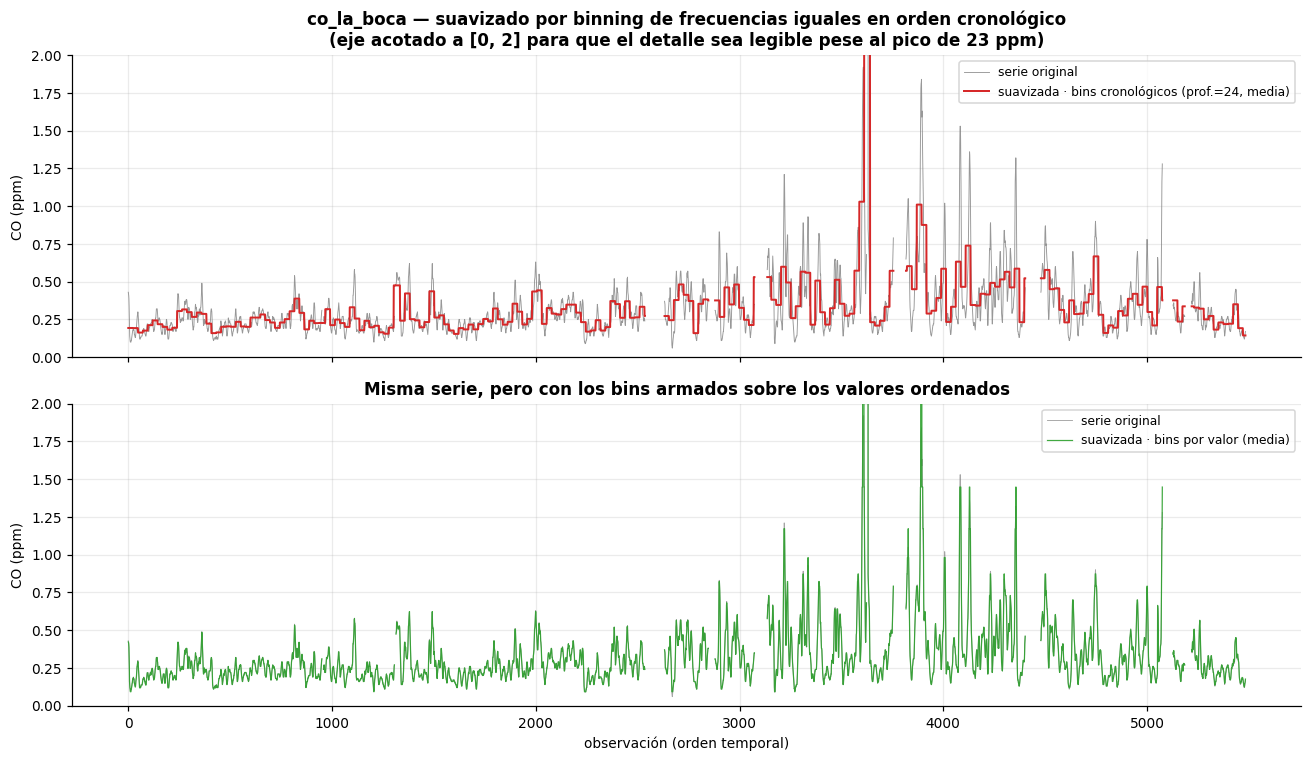

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

# --- Panel 1: orden cronológico
axes[0].plot(orig.values, lw=.6, color=GRIS, alpha=.8, label="serie original")
axes[0].plot(suave_tiem.values, lw=1.3, color=ROJO, label=f"suavizada · bins cronológicos (prof.={PROF}, media)")
axes[0].set_ylim(0, 2.0)
axes[0].set_title(f"{VAR} — suavizado por binning de frecuencias iguales en orden cronológico\n"
                  "(eje acotado a [0, 2] para que el detalle sea legible pese al pico de 23 ppm)")
axes[0].set_ylabel("CO (ppm)"); axes[0].legend(loc="upper right", fontsize=8)

# --- Panel 2: comparación de las dos variantes
axes[1].plot(orig.values, lw=.6, color=GRIS, alpha=.7, label="serie original")
axes[1].plot(suave_val.values, lw=.8, color=VERDE, alpha=.9, label="suavizada · bins por valor (media)")
axes[1].set_ylim(0, 2.0); axes[1].set_xlabel("observación (orden temporal)")
axes[1].set_ylabel("CO (ppm)")
axes[1].set_title("Misma serie, pero con los bins armados sobre los valores ordenados")
axes[1].legend(loc="upper right", fontsize=8)
fig.tight_layout(); plt.show()

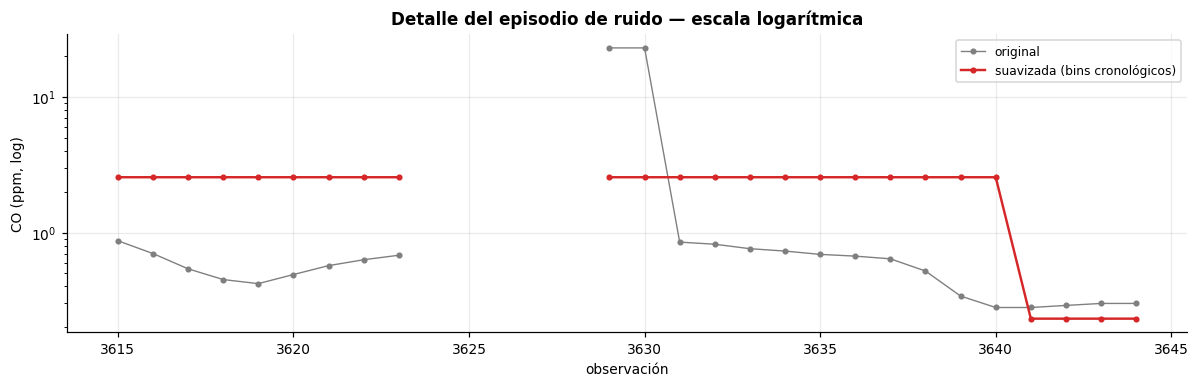

Valor original en el pico                    : 23.0 ppm
Suavizado con la MEDIA del bin (cronológico) : 2.558 ppm
Suavizado con la MEDIANA del bin             : 0.685 ppm
Suavizado con bins armados por valor         : 5.093 ppm
Mediana de toda la serie                     : 0.27 ppm


In [11]:
# ¿Qué pasa en el entorno del pico de ruido (1 de junio, horas 6 y 7)?
ventana = slice(3615, 3645)
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(range(*ventana.indices(len(orig))), orig.values[ventana], "o-", ms=3, lw=.9,
        color=GRIS, label="original")
ax.plot(range(*ventana.indices(len(orig))), suave_tiem.values[ventana], "o-", ms=3, lw=1.6,
        color=ROJO, label="suavizada (bins cronológicos)")
ax.set_yscale("log"); ax.set_title("Detalle del episodio de ruido — escala logarítmica")
ax.set_xlabel("observación"); ax.set_ylabel("CO (ppm, log)"); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

suave_med = bin_frecuencias_iguales(orig, PROF, "mediana", ordenar_por_valor=False)
print("Valor original en el pico                    :", orig.iloc[3629], "ppm")
print("Suavizado con la MEDIA del bin (cronológico) :", round(suave_tiem.iloc[3629], 3), "ppm")
print("Suavizado con la MEDIANA del bin             :", round(suave_med.iloc[3629], 3), "ppm")
print("Suavizado con bins armados por valor         :", round(suave_val.iloc[3629], 3), "ppm")
print("Mediana de toda la serie                     :", orig.median(), "ppm")

### Respuesta 1.b

Se eligió `co_la_boca` con bins de **profundidad 24** (equivalente a un día completo de
mediciones horarias) y estimación por **media**.

**Qué muestran las dos series.** La serie original es visiblemente ruidosa: oscila hora a hora
con un componente de alta frecuencia que mezcla el ciclo diario real del tránsito con
fluctuaciones del sensor. La serie suavizada sobre bins cronológicos conserva la forma general
—los ascensos y descensos estacionales siguen ahí— pero elimina la oscilación de corto plazo:
el desvío estándar cae de 0,491 a 0,209 ppm (retiene el 18 % de la varianza original) y la
serie queda descrita por 190 medias de bin, cada una representando 24 horas de mediciones.

**El efecto sobre el ruido es el resultado más claro.** El pico espurio de 23 ppm queda
promediado junto con sus 23 vecinos del mismo bin y baja a **2,56 ppm**. El ruido no desaparece
del todo —una media es sensible a valores extremos y el bin queda "contaminado"— pero el valor
deja de ser ochenta veces la mediana para quedar en el mismo orden de magnitud que el resto de
la serie. Si el objetivo fuera eliminarlo por completo, la **mediana** del bin es el estimador
adecuado: con ella el mismo punto queda en **0,69 ppm**, prácticamente indistinguible de una
observación normal. Es un argumento práctico a favor de la mediana sobre la media cuando el
ruido tiene forma de pico aislado.

**Las dos variantes de ordenamiento no son intercambiables.** Cuando los bins se arman sobre
los valores ordenados (procedimiento clásico del libro), cada bin agrupa observaciones de
magnitud parecida aunque provengan de meses distintos: el resultado es una **discretización**
de la variable en 99 niveles, que reduce la precisión pero **no suaviza la serie temporal**: el
RMSE respecto del original es incluso menor (0,387 contra 0,444) y retiene el doble de varianza
(37,7 % contra 18,1 %), porque cada valor se reemplaza por la media de sus vecinos *en valor*,
que le queda muy cerca. El pico espurio cae en el último bin junto a los otros valores altos y
sobrevive con 5,09 ppm, el doble que con los bins cronológicos. Cuando los bins se arman en orden
cronológico, en cambio, cada bin agrupa **horas vecinas** y el promedio actúa como un filtro
pasa-bajos: es esta variante la que efectivamente suaviza el ruido de la serie.

La conclusión metodológica: en datos ordenados en el tiempo, el suavizado por binning debe
aplicarse sobre el orden natural de la serie; el ordenamiento por valor sirve para discretizar,
no para filtrar ruido.

## 1.c — Suavizado por extremos con bins de anchos iguales (de 2 a 10)

El *binning* de **anchos iguales** parte el **rango** de la variable en intervalos de la misma
amplitud. El suavizado **por extremos** (*smoothing by bin boundaries*) reemplaza cada valor
por el borde del bin —mínimo o máximo— que le quede más cerca.

Se varía la **cantidad de bins de 2 a 10** y se comparan los resultados. Para que el efecto sea
legible se usa `pm10_cordoba`, que tiene un rango amplio y pocos faltantes.

In [12]:
VAR2 = "pm10_cordoba"
orig2 = aire[VAR2]

resultados, series = [], {}
for k in range(2, 11):
    suave, bordes = bin_anchos_iguales(orig2, k, estimador="extremos")
    series[k] = suave
    m = metricas_suavizado(orig2, suave)
    resultados.append({"n_bins": k, "amplitud del bin": (orig2.max() - orig2.min()) / k, **m})

tabla_c = pd.DataFrame(resultados).set_index("n_bins")
tabla_c.round(3)

,amplitud del bin,RMSE vs original,desvío original,desvío suavizado,% varianza retenida,valores distintos
n_bins,,,,,,
2,26.5000,8.5990,9.4750,14.3120,228.1770,4
3,17.6670,5.1580,9.4750,10.3040,118.2550,6
4,13.2500,3.4450,9.4750,9.3480,97.3280,8
5,10.6000,2.6430,9.4750,9.7170,105.1710,10
6,8.8330,2.1420,9.4750,9.7030,104.8800,12
7,7.5710,1.8040,9.4750,9.6240,103.1600,14
8,6.6250,1.5210,9.4750,9.6570,103.8710,16
9,5.8890,1.3010,9.4750,9.5830,102.2990,18
10,5.3000,1.1820,9.4750,9.6170,103.0170,20


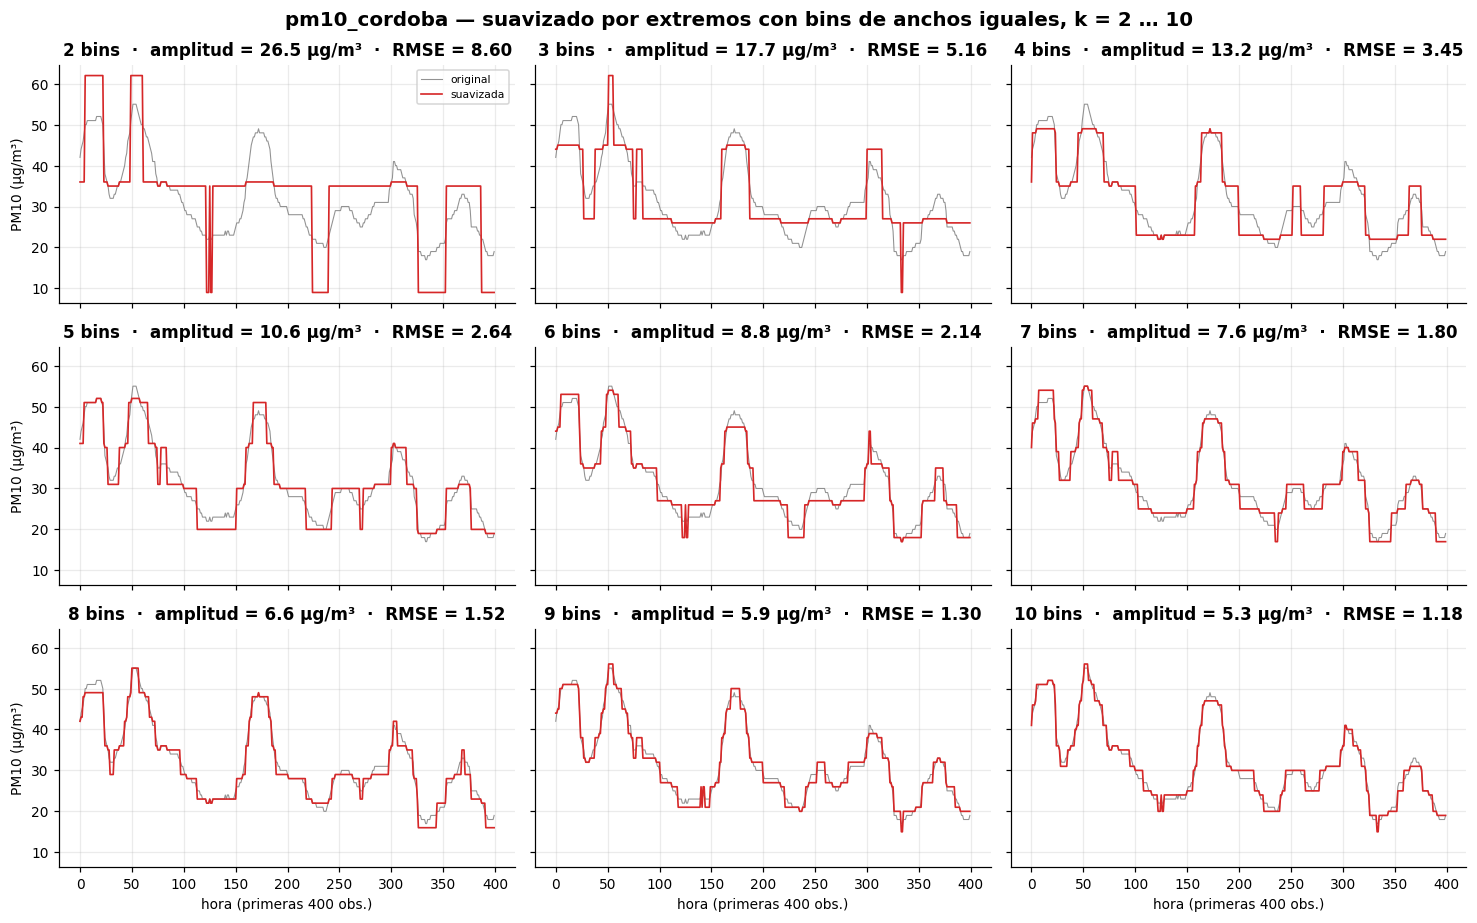

In [13]:
fig, axes = plt.subplots(3, 3, figsize=(13.5, 8.5), sharex=True, sharey=True)
sub = slice(0, 400)                      # primeras 400 horas, para poder ver la forma
for ax, k in zip(axes.ravel(), range(2, 11)):
    ax.plot(orig2.values[sub], lw=.7, color=GRIS, alpha=.85, label="original")
    ax.plot(series[k].values[sub], lw=1.1, color=ROJO, label="suavizada")
    amp = (orig2.max() - orig2.min()) / k
    ax.set_title(f"{k} bins  ·  amplitud = {amp:.1f} µg/m³  ·  RMSE = {tabla_c.loc[k,'RMSE vs original']:.2f}")
axes[0, 0].legend(fontsize=7, loc="upper right")
for ax in axes[-1]: ax.set_xlabel("hora (primeras 400 obs.)")
for ax in axes[:, 0]: ax.set_ylabel("PM10 (µg/m³)")
fig.suptitle(f"{VAR2} — suavizado por extremos con bins de anchos iguales, k = 2 … 10",
             fontsize=13, fontweight="bold")
fig.tight_layout(); plt.show()

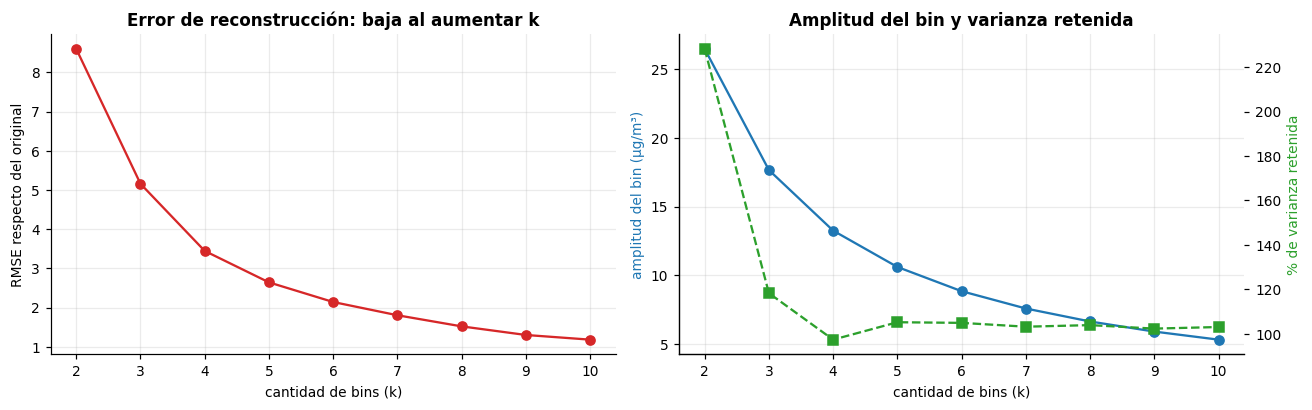

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(tabla_c.index, tabla_c["RMSE vs original"], "o-", color=ROJO)
axes[0].set_xlabel("cantidad de bins (k)"); axes[0].set_ylabel("RMSE respecto del original")
axes[0].set_title("Error de reconstrucción: baja al aumentar k")

axes[1].plot(tabla_c.index, tabla_c["amplitud del bin"], "o-", color=AZUL, label="amplitud del bin")
ax2 = axes[1].twinx()
ax2.plot(tabla_c.index, tabla_c["% varianza retenida"], "s--", color=VERDE, label="% varianza retenida")
ax2.grid(False)
axes[1].set_xlabel("cantidad de bins (k)"); axes[1].set_ylabel("amplitud del bin (µg/m³)", color=AZUL)
ax2.set_ylabel("% de varianza retenida", color=VERDE)
axes[1].set_title("Amplitud del bin y varianza retenida")
fig.tight_layout(); plt.show()

### Respuesta 1.c

**Qué ocurre conforme el bin aumenta.** La consigna admite dos lecturas simétricas y conviene
dejarlas explícitas, porque apuntan a lo mismo visto desde los dos extremos:

- **A medida que aumenta la *amplitud* del bin** (es decir, **menos bins**: k = 2), el suavizado
  es más agresivo. Con k = 2 la serie se reduce a cuatro valores posibles (los extremos observados de
  cada uno de los dos intervalos) y el gráfico muestra una onda cuadrada que ya no tiene ninguna relación con la
  dinámica original: el RMSE trepa a 8,60 µg/m³ y se pierde toda la variación intradiaria. El
  suavizado dejó de filtrar ruido y pasó a destruir señal.
- **A medida que aumenta la *cantidad* de bins** (k → 10), la amplitud de cada intervalo se
  achica, los bordes se acercan a los valores reales y la serie suavizada converge a la
  original: el RMSE cae monótonamente de 8,60 a 1,18 µg/m³ y el porcentaje de varianza retenida
  sube hacia el 100 %. Con k = 10 el gráfico es prácticamente indistinguible del original: casi
  no hay suavizado, solo una cuantización fina.

**Entonces hay un compromiso (*trade-off*) explícito.** El parámetro k gobierna el balance
entre reducción de ruido y conservación de la señal. Valores bajos de k producen máxima
reducción de varianza al costo de máximo sesgo; valores altos preservan la señal pero no
suavizan nada. En este dataset, la zona razonable está entre k = 6 y k = 8 (amplitudes de 6,6 a
8,8 µg/m³, RMSE de 1,5 a 2,1 µg/m³): ahí la serie suavizada sigue el ciclo diario pero elimina las
oscilaciones de corto plazo.

**Sobre el suavizado por extremos en particular.** A diferencia de la media, este método
**conserva valores que existen en el dominio** de la variable (los bordes son valores reales del
rango), lo que facilita la interpretación. Su contrapartida es que es *empujante*: cada
observación se corre hacia el borde más cercano, de modo que la distribución resultante se
vuelve bimodal dentro de cada bin, concentrando masa en los extremos y vaciando el centro. Esto
se nota en la tabla: con k chico la varianza retenida supera el 100 % en algunos casos, porque
llevar todos los valores a los bordes **aumenta** artificialmente la dispersión respecto del
original. Es un artefacto del método que hay que tener presente si después se van a calcular
desvíos o correlaciones sobre los datos suavizados.

## 1.d — Caso de aplicación de *binning* sobre otro conjunto de datos

**Conjunto elegido:** `alquileres.csv` (avisos de alquiler temporario de la Ciudad de Buenos
Aires, Inside Airbnb, 29.438 filas).

**Justificación de la elección.** El binning no solo sirve para filtrar ruido de series
temporales; su segunda aplicación clásica es **construir segmentos interpretables a partir de
una variable continua muy dispersa**. El precio por noche de los alquileres temporarios es un
caso de manual:

1. Está fuertemente **sesgado a derecha** (media $131.372 contra mediana $103.206) y su rango
   cubre tres órdenes de magnitud, de $1.216 a $1.499.960.
2. Tiene **ruido de redondeo comercial**: los anfitriones fijan precios "psicológicos" ($99.999,
   $100.000, $120.000), de modo que la variable tiene una granularidad artificial que no
   refleja diferencias reales de calidad.
3. La pregunta de negocio —*¿cómo varía la ocupación según el segmento de precio?*— no requiere
   la precisión al peso, sino **franjas de mercado**.

Se aplica binning por **frecuencias iguales** (estimando por mediana, robusta frente a la cola
derecha) para construir diez deciles de precio, y se analiza la relación precio–ocupación antes
y después de la transformación.

In [15]:
alq = alquileres.dropna(subset=["precio_ars"]).copy()
print(f"Avisos con precio informado: {len(alq):,}")
print(alq["precio_ars"].describe().round(0).to_string())

# Binning por frecuencias iguales: 10 deciles de precio, estimados por la MEDIANA del bin
alq["decil_precio"] = pd.qcut(alq["precio_ars"], 10, labels=[f"D{i}" for i in range(1, 11)])
alq["precio_suavizado"] = alq.groupby("decil_precio", observed=True)["precio_ars"].transform("median")

resumen_d = (alq.groupby("decil_precio", observed=True)
                .agg(n=("precio_ars", "size"),
                     precio_min=("precio_ars", "min"),
                     precio_max=("precio_ars", "max"),
                     valor_del_bin=("precio_suavizado", "first"),
                     ocupacion_media=("noches_ocupadas_anio", "mean"),
                     capacidad_media=("capacidad", "mean")))
resumen_d.round(1)

Avisos con precio informado: 27,520
count      27,520.0000
mean      131,372.0000
std       115,303.0000
min         1,216.0000
25%        77,125.0000
50%       103,206.0000
75%       145,168.0000
max     1,499,960.0000


,n,precio_min,precio_max,valor_del_bin,ocupacion_media,capacidad_media
decil_precio,,,,,,
D1,2752,"1,216.0000","55,565.0000","41,689.5000",57.6000,1.9000
D2,2769,"55,578.0000","71,363.0000","64,722.0000",83.6000,2.3000
D3,2735,"71,384.0000","82,403.0000","77,210.0000",83.9000,2.4000
D4,2759,"82,407.0000","92,705.0000","87,502.0000",84.6000,2.6000
D5,2747,"92,706.0000","103,206.0000","97,895.0000",83.0000,2.7000
D6,2754,"103,226.0000","116,392.0000","109,682.0000",83.6000,2.8000
D7,2748,"116,394.0000","133,376.0000","124,105.0000",79.5000,3.0000
D8,2754,"133,379.0000","161,411.0000","145,168.0000",78.2000,3.2000
D9,2750,"161,412.0000","218,977.0000","182,836.0000",71.5000,3.6000


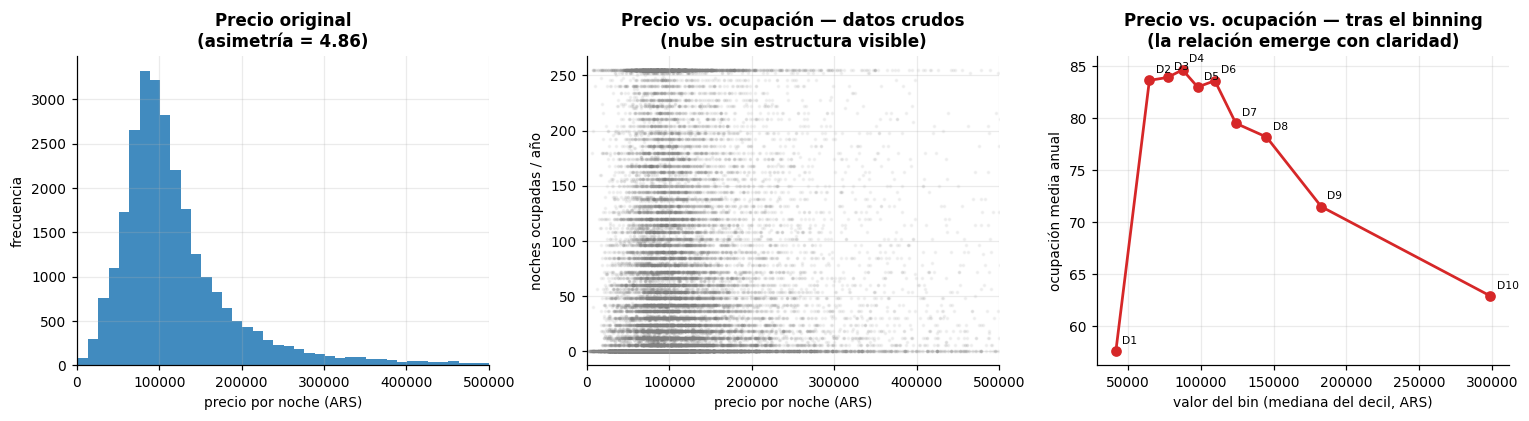

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.9))

# 1) Distribución original
axes[0].hist(alq["precio_ars"], bins=120, color=AZUL, alpha=.85)
axes[0].set_xlim(0, 500_000); axes[0].set_title("Precio original\n(asimetría = %.2f)" % stats.skew(alq["precio_ars"]))
axes[0].set_xlabel("precio por noche (ARS)"); axes[0].set_ylabel("frecuencia")

# 2) Dispersión precio-ocupación con datos crudos
axes[1].scatter(alq["precio_ars"], alq["noches_ocupadas_anio"], s=2, alpha=.08, color=GRIS)
axes[1].set_xlim(0, 500_000); axes[1].set_title("Precio vs. ocupación — datos crudos\n(nube sin estructura visible)")
axes[1].set_xlabel("precio por noche (ARS)"); axes[1].set_ylabel("noches ocupadas / año")

# 3) La misma relación, después del binning
axes[2].plot(resumen_d["valor_del_bin"], resumen_d["ocupacion_media"], "o-", color=ROJO, lw=1.8)
for et, fila in resumen_d.iterrows():
    axes[2].annotate(et, (fila["valor_del_bin"], fila["ocupacion_media"]),
                     textcoords="offset points", xytext=(4, 5), fontsize=7)
axes[2].set_title("Precio vs. ocupación — tras el binning\n(la relación emerge con claridad)")
axes[2].set_xlabel("valor del bin (mediana del decil, ARS)"); axes[2].set_ylabel("ocupación media anual")
fig.tight_layout(); plt.show()

In [17]:
# Cuánto se redujo la granularidad y cuánta información se conservó
r, p = stats.spearmanr(alq["precio_ars"], alq["noches_ocupadas_anio"])
r_b, p_b = stats.spearmanr(alq["precio_suavizado"], alq["noches_ocupadas_anio"])
print(f"Valores distintos de precio      : {alq['precio_ars'].nunique():,}")
print(f"Valores distintos tras el binning: {alq['precio_suavizado'].nunique():,}")
print(f"\nCorrelación de Spearman precio–ocupación")
print(f"  datos crudos    : rho = {r:+.3f}  (p = {p:.1e})")
print(f"  datos suavizados: rho = {r_b:+.3f}  (p = {p_b:.1e})")

Valores distintos de precio      : 13,827
Valores distintos tras el binning: 10

Correlación de Spearman precio–ocupación
  datos crudos    : rho = -0.001  (p = 8.7e-01)
  datos suavizados: rho = -0.002  (p = 7.8e-01)


### Respuesta 1.d

**En qué contribuye la técnica.** El binning transformó 13.827 precios distintos en **10 valores
representativos** —una reducción de tres órdenes de magnitud en la cardinalidad— y el aporte se
ve en tres planos:

1. **Hace visible una relación que los datos crudos ocultaban.** El diagrama de dispersión
   precio–ocupación con 27.520 puntos es una nube negra sin estructura: la varianza individual
   de cada aviso (un departamento puede estar vacío por mil razones ajenas al precio) tapa
   completamente la señal. Al agregar por decil, aparece un patrón nítido y no monótono: la
   ocupación media sube de los deciles más baratos hacia la zona media-baja del mercado y luego
   cae sostenidamente en los deciles caros. Y hay un detalle revelador: la correlación de Spearman
   entre precio y ocupación es **prácticamente nula (ρ = −0,001; p = 0,87)**, tanto con los
   datos crudos como con los suavizados. Si uno se guiara solo por ese coeficiente concluiría
   que el precio no tiene relación con la ocupación, y sería un error: la relación existe pero
   es **no monótona**, y ningún coeficiente de correlación de rangos puede capturar una U
   invertida. El binning no inventó información, la hizo visible donde un estadístico resumen
   la daba por inexistente.

2. **Absorbe el ruido de redondeo comercial.** Los precios "psicológicos" y los ajustes
   inflacionarios de cada anfitrión dejan de ser diferencias entre observaciones: dentro de un
   decil, $99.999 y $100.000 son el mismo valor, que es exactamente lo correcto desde el punto
   de vista del análisis de mercado.

3. **Neutraliza la asimetría sin transformar la escala.** A diferencia de un logaritmo, el
   binning por frecuencias iguales garantiza que los diez segmentos tengan ~2.750 avisos cada
   uno, con lo que ningún tramo del mercado queda sub-representado. El decil superior, que
   cubre un rango de precio enorme ($219.000 a $1.500.000), pesa lo mismo que el inferior a la
   hora de estimar medias por segmento — y eso evita que un puñado de avisos de lujo domine
   cualquier promedio.

**Costo de la técnica.** Se pierde precisión dentro de cada bin (todos los avisos del D10 pasan
a valer lo mismo pese a diferir en un factor de siete) y la elección del número de bins es
arbitraria. Por eso conviene conservar siempre la variable original junto a la discretizada, y
usar la segunda solo para el análisis agregado y la comunicación de resultados.

<a id="ej2"></a>

---

# Ejercicio 2 — Detección de *outliers*

**Dataset:** `clima_smn.csv` — 23.019 observaciones horarias de superficie del Servicio
Meteorológico Nacional, correspondientes a los días 10 y 20 de cada mes entre septiembre de
2025 y agosto de 2026, en 40 estaciones del país y de la Antártida.

## 2.a — Exploración inicial: ¿qué variables tienen observaciones etiquetables como *outliers*?

In [18]:
print(clima.dtypes.to_string())
print(f"\nEstaciones meteorológicas: {clima['estacion_meteorologica'].nunique()}")
print(f"Período: {clima['fecha'].min().date()} a {clima['fecha'].max().date()}")
print("\nDistribución por temporada:")
print(clima["temporada"].value_counts().to_string())
clima.head()

fecha                     datetime64[us]
hora                               int64
estacion_meteorologica               str
temporada                            str
temperatura                      float64
humedad                          float64
presion                          float64
dir_viento                       float64
vel_viento                       float64

Estaciones meteorológicas: 40
Período: 2025-09-10 a 2026-08-20

Distribución por temporada:
temporada
Primavera    5760
Verano       5757
Invierno     5754
Otoño        5748


,fecha,hora,estacion_meteorologica,temporada,temperatura,humedad,presion,dir_viento,vel_viento
0,2025-09-10,0,AEROPARQUE AERO,Primavera,15.6000,80.0000,"1,016.7000",340.0000,9.0000
1,2025-09-10,1,AEROPARQUE AERO,Primavera,15.3000,84.0000,"1,016.1000",340.0000,9.0000
2,2025-09-10,2,AEROPARQUE AERO,Primavera,15.1000,85.0000,"1,015.8000",340.0000,9.0000
3,2025-09-10,3,AEROPARQUE AERO,Primavera,14.8000,85.0000,"1,015.2000",340.0000,9.0000
4,2025-09-10,4,AEROPARQUE AERO,Primavera,15.0000,74.0000,"1,015.0000",320.0000,17.0000


In [19]:
NUM = ["temperatura", "humedad", "presion", "dir_viento", "vel_viento"]

exp = clima[NUM].describe().T
exp["faltantes"] = clima[NUM].isna().sum()
exp["asimetría"] = [stats.skew(clima[v].dropna()) for v in NUM]
exp["curtosis"]  = [stats.kurtosis(clima[v].dropna()) for v in NUM]
exp.round(2)

,count,mean,std,min,25%,50%,75%,max,faltantes,asimetría,curtosis
temperatura,"23,019.0000",16.1100,8.9600,-26.0000,10.2000,16.6000,22.5000,42.6000,0,-0.4500,0.7000
humedad,"23,014.0000",68.7000,21.1900,6.0000,53.0000,72.0000,87.0000,100.0000,5,-0.4800,-0.7400
presion,"21,293.0000","1,012.2900",9.3900,963.2000,"1,006.9000","1,012.9000","1,017.6000","1,038.7000",1726,-0.4600,1.5200
dir_viento,"23,017.0000",192.9400,167.2000,0.0000,90.0000,180.0000,270.0000,990.0000,2,2.6000,10.3300
vel_viento,"23,017.0000",13.5000,10.0000,0.0000,7.0000,11.0000,19.0000,100.0000,2,1.7100,4.8900


In [20]:
def limites_iqr(s, k=1.5):
    '''Devuelve (bigote_inferior, bigote_superior) según el criterio de Tukey.'''
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

filas = []
for v in NUM:
    s = clima[v].dropna()
    lo, hi = limites_iqr(s)
    lo_ext, hi_ext = limites_iqr(s, k=3.0)        # criterio de outlier "extremo"
    z = (s - s.mean()) / s.std()
    filas.append({
        "variable": v,
        "bigote inf (1.5·IQR)": lo, "bigote sup (1.5·IQR)": hi,
        "outliers (1.5·IQR)": int(((s < lo) | (s > hi)).sum()),
        "% del total": 100 * ((s < lo) | (s > hi)).mean(),
        "outliers extremos (3·IQR)": int(((s < lo_ext) | (s > hi_ext)).sum()),
        "|z| > 3": int((z.abs() > 3).sum()),
    })
diag = pd.DataFrame(filas).set_index("variable")
diag.round(2)

,bigote inf (1.5·IQR),bigote sup (1.5·IQR),outliers (1.5·IQR),% del total,outliers extremos (3·IQR),|z| > 3
variable,,,,,,
temperatura,-8.2500,40.9500,258,1.1200,0,172
humedad,2.0000,138.0000,0,0.0000,0,0
presion,990.8500,"1,033.6500",844,3.9600,39,192
dir_viento,-180.0000,540.0000,579,2.5200,579,579
vel_viento,-11.0000,37.0000,659,2.8600,108,366


In [21]:
# La dirección del viento requiere un análisis aparte: es una variable CIRCULAR y usa códigos
print("Valores más frecuentes en el extremo superior de dir_viento:")
print(clima["dir_viento"].value_counts().sort_index().tail(5).to_string())
print(f"\nRegistros con dir_viento = 990 : {(clima['dir_viento'] == 990).sum():,}"
      f"  ({100*(clima['dir_viento']==990).mean():.1f} % del total)")
print("Valores válidos de dirección: 0 a 360 grados.")

print("\n¿Dónde faltan las presiones?")
print(clima[clima["presion"].isna()]["estacion_meteorologica"].value_counts().to_string())

Valores más frecuentes en el extremo superior de dir_viento:
dir_viento
330.0000     141
340.0000     618
350.0000     131
360.0000    1339
990.0000     579

Registros con dir_viento = 990 : 579  (2.5 % del total)
Valores válidos de dirección: 0 a 360 grados.

¿Dónde faltan las presiones?
estacion_meteorologica
JUJUY AERO        576
BARILOCHE AERO    575
SALTA AERO        575


### Respuesta 2.a

**Variables con observaciones etiquetables como outliers.** Aplicando el criterio de Tukey
(1,5 · IQR) sobre las cinco variables numéricas:

| variable | outliers (1,5·IQR) | % | interpretación |
|---|---|---|---|
| `temperatura` | 258 | 1,1 % | reales — frío antártico |
| `presion` | 844 | 4,0 % | reales — latitudes altas |
| `vel_viento` | 659 | 2,9 % | reales — Patagonia y Antártida |
| `dir_viento` | 579 | 2,5 % | **falsos** — código 990 |
| `humedad` | 0 | 0 % | ninguno |

**`humedad` no tiene outliers y no puede tenerlos** por construcción: está acotada al intervalo
[0, 100] y su IQR (53 a 87) es tan amplio que los bigotes teóricos caen en 2 y 138, fuera del
dominio de la variable. Es el ejemplo perfecto de que el criterio de Tukey solo detecta valores
extremos *relativos a la dispersión propia* de la variable.

**`dir_viento` es el caso a corregir antes que a analizar.** Los 579 valores "atípicos" son en
realidad **un único valor repetido: 990**, que no es una dirección (el dominio válido es 0 a 360
grados) sino el **código con que el SMN informa viento variable o calma**. No es un outlier
estadístico sino un **valor centinela mal interpretado como numérico**: dejarlo tal cual
distorsiona la media (192,9° cuando el promedio de las direcciones válidas es 172,4°) y el desvío. Además, la dirección del
viento es una **variable circular** —0° y 360° son el mismo punto— de modo que ni la media
aritmética ni el IQR son estadísticos válidos para ella. Por ambas razones se la excluye del
análisis de outliers de los puntos siguientes, previa conversión del 990 a faltante.

**Las otras tres sí tienen outliers, pero son valores legítimos.** La exploración por estación
muestra que están geográficamente concentrados: de las 258 temperaturas atípicas, 230 (89 %)
corresponden a **Base Marambio** (Antártida) y el resto a El Calafate y Río Gallegos; de las 844
presiones atípicas, 283 son de Marambio y el resto de Ushuaia, Río Grande y Río Gallegos. No son
errores de medición: son **observaciones de una subpoblación distinta** mezclada en el mismo
dataset. Una temperatura de −26 °C es imposible en Buenos Aires y perfectamente normal en la
Antártida en julio. Esto es un caso clásico de outliers generados por **heterogeneidad de la
población**, y la conclusión práctica es que **no deben eliminarse**: lo correcto es estratificar
por estación o por región antes de analizarlos.

**Un dato adicional que no es outlier pero sí un problema de calidad:** `presion` tiene 1.726
faltantes concentrados en exactamente tres estaciones (Jujuy, Bariloche y Salta), que no
informan presión reducida al nivel del mar en todo el período. Es un faltante sistemático por
estación, no aleatorio.

## 2.b — Análisis gráfico con *boxplots*

In [22]:
# Se corrige el código centinela antes de graficar
clima = clima.copy()
n_990 = (clima["dir_viento"] == 990).sum()
clima.loc[clima["dir_viento"] == 990, "dir_viento"] = np.nan
print(f"Se convirtieron {n_990:,} valores 990 de dir_viento a NaN (código de viento variable/calma).")

VARS_OUT = ["temperatura", "humedad", "presion", "vel_viento"]   # dir_viento queda fuera (circular)

Se convirtieron 579 valores 990 de dir_viento a NaN (código de viento variable/calma).


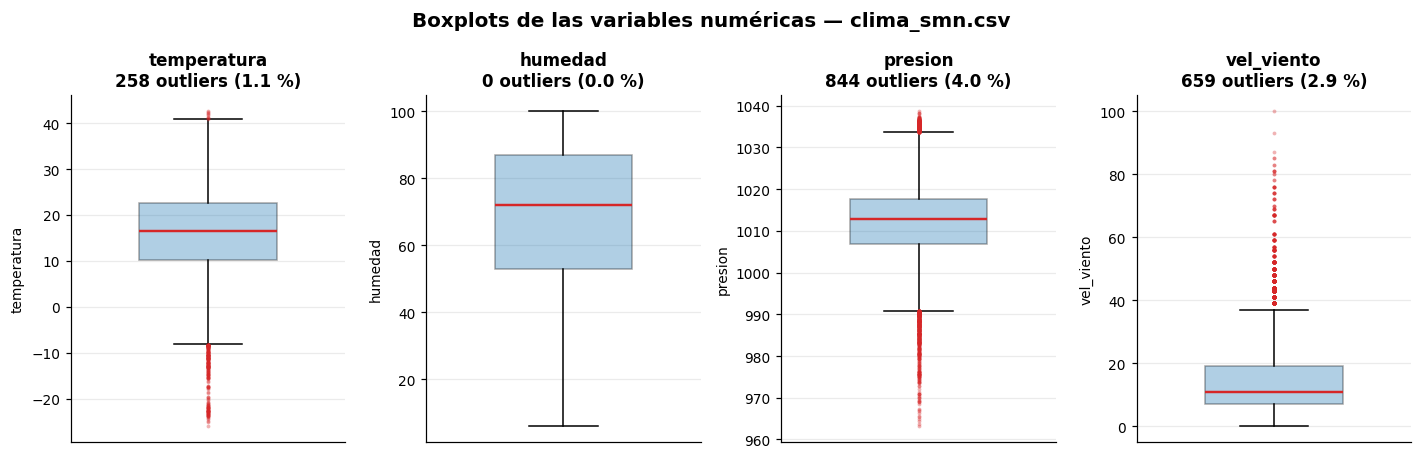

In [23]:
fig, axes = plt.subplots(1, 4, figsize=(13, 4.2))
for ax, v in zip(axes, VARS_OUT):
    s = clima[v].dropna()
    lo, hi = limites_iqr(s)
    bp = ax.boxplot(s, vert=True, widths=.5, patch_artist=True,
                    flierprops=dict(marker="o", ms=2.5, mfc=ROJO, mec="none", alpha=.35),
                    medianprops=dict(color=ROJO, lw=1.6),
                    boxprops=dict(facecolor=AZUL, alpha=.35))
    n_out = int(((s < lo) | (s > hi)).sum())
    ax.set_title(f"{v}\n{n_out:,} outliers ({100*n_out/len(s):.1f} %)")
    ax.set_xticks([]); ax.set_ylabel(v)
fig.suptitle("Boxplots de las variables numéricas — clima_smn.csv", fontsize=13, fontweight="bold")
fig.tight_layout(); plt.show()

region
Resto del país    18415
Patagonia          4031
Antártida           573


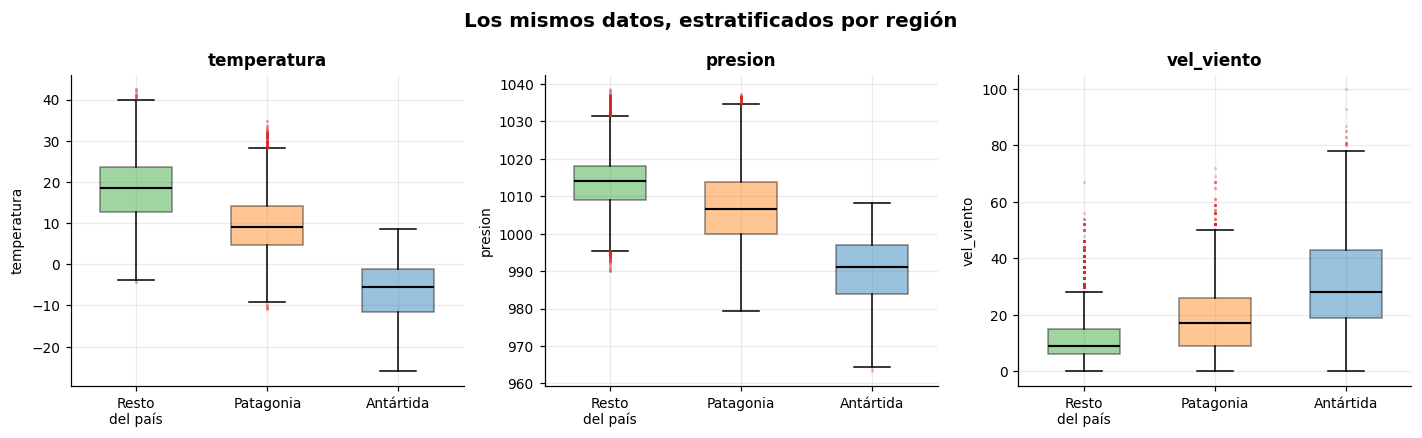

In [24]:
# Los mismos boxplots, ahora estratificados por región, para probar la hipótesis de 2.a
ANTARTIDA = ["BASE MARAMBIO", "BASE ORCADAS", "BASE BELGRANO II", "BASE ESPERANZA", "BASE CARLINI"]
PATAGONIA = ["USHUAIA AERO", "RIO GRANDE B.A.", "RIO GALLEGOS AERO", "EL CALAFATE AERO",
             "COMODORO RIVADAVIA AERO", "BARILOCHE AERO", "TRELEW AERO", "ESQUEL AERO"]

def region(e):
    if e in ANTARTIDA: return "Antártida"
    if e in PATAGONIA: return "Patagonia"
    return "Resto del país"

clima["region"] = clima["estacion_meteorologica"].map(region)
print(clima["region"].value_counts().to_string())

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, v in zip(axes, ["temperatura", "presion", "vel_viento"]):
    datos = [clima.loc[clima["region"] == r, v].dropna() for r in
             ["Resto del país", "Patagonia", "Antártida"]]
    bp = ax.boxplot(datos, patch_artist=True, widths=.55,
                    flierprops=dict(marker="o", ms=2, alpha=.25, mfc=ROJO, mec="none"),
                    medianprops=dict(color="black", lw=1.4))
    for caja, col in zip(bp["boxes"], [VERDE, NARANJA, AZUL]):
        caja.set_facecolor(col); caja.set_alpha(.45)
    ax.set_xticklabels(["Resto\ndel país", "Patagonia", "Antártida"])
    ax.set_title(v); ax.set_ylabel(v)
fig.suptitle("Los mismos datos, estratificados por región", fontsize=13, fontweight="bold")
fig.tight_layout(); plt.show()

### Respuesta 2.b

Los boxplots confirman y precisan el diagnóstico numérico:

- **`temperatura`**: caja centrada y bastante simétrica (10,2 a 22,5 °C, mediana 16,6 °C) con
  bigotes en −8,3 y 41,0 °C. Los 258 outliers están **casi todos por debajo** del bigote
  inferior: es una cola inferior larga, no una dispersión general.
- **`humedad`**: caja muy ancha (53 a 87 %), mediana desplazada hacia arriba (72 %), **sin ningún
  punto fuera de los bigotes**. La distribución está truncada en 100 % y acumula masa ahí.
- **`presion`**: caja estrecha (1.006,9 a 1.017,6 hPa) y simétrica, con outliers en **ambas**
  colas. Al ser tan chico el IQR (10,7 hPa) los bigotes quedan cerca y cualquier desvío
  moderado se etiqueta como atípico.
- **`vel_viento`**: la más asimétrica. Mediana 11 km/h, bigote inferior en 0 (el mínimo físico) y
  superior en 37 km/h, con una cola derecha larga que llega a 100 km/h. Todos los outliers son
  superiores, como corresponde a una variable acotada en cero.

**El gráfico estratificado por región es el que cierra el argumento.** Al separar Antártida,
Patagonia y el resto del país, las tres nubes de outliers prácticamente **desaparecen**: cada
subpoblación tiene su propia caja, coherente con su clima, y los puntos que antes caían fuera
de los bigotes ahora quedan dentro de la caja de su grupo. La Antártida tiene una mediana de
temperatura netamente inferior y una dispersión de presión mucho mayor; la Patagonia concentra
las velocidades de viento altas. Esto demuestra que los "outliers" del análisis global **no eran
anomalías sino evidencia de que el dataset mezcla poblaciones heterogéneas**.

## 2.c — ¿A cuántos desvíos de la media están los outliers? Comparación con los bigotes

Se traduce cada bigote del boxplot a **unidades de desvío estándar** (puntaje z), para poder
comparar directamente el criterio de Tukey (basado en cuantiles, robusto) con el criterio de los
z-scores (basado en media y desvío, no robusto).

In [25]:
filas = []
for v in VARS_OUT:
    s = clima[v].dropna()
    mu, sd = s.mean(), s.std()
    lo, hi = limites_iqr(s)
    out = s[(s < lo) | (s > hi)]
    z_out = ((out - mu) / sd).abs()
    filas.append({
        "variable": v, "media": mu, "desvío": sd,
        "bigote inf": lo, "z del bigote inf": (lo - mu) / sd,
        "bigote sup": hi, "z del bigote sup": (hi - mu) / sd,
        "n outliers Tukey": len(out),
        "|z| medio de los outliers": z_out.mean() if len(out) else np.nan,
        "|z| máximo": z_out.max() if len(out) else np.nan,
        "de ellos con |z|>3": int((z_out > 3).sum()),
        "n con |z|>3 en toda la serie": int((((s - mu) / sd).abs() > 3).sum()),
    })
tabla_z = pd.DataFrame(filas).set_index("variable")
tabla_z.round(2)

,media,desvío,bigote inf,z del bigote inf,bigote sup,z del bigote sup,n outliers Tukey,|z| medio de los outliers,|z| máximo,de ellos con |z|>3,n con |z|>3 en toda la serie
variable,,,,,,,,,,,
temperatura,16.1100,8.9600,-8.2500,-2.7200,40.9500,2.7700,258,3.3700,4.7000,172,172
humedad,68.7000,21.1900,2.0000,-3.1500,138.0000,3.2700,0,NaN,NaN,0,0
presion,"1,012.2900",9.3900,990.8500,-2.2800,"1,033.6500",2.2700,844,2.7600,5.2300,192,192
vel_viento,13.5000,10.0000,-11.0000,-2.4500,37.0000,2.3500,659,3.4100,8.6500,366,366


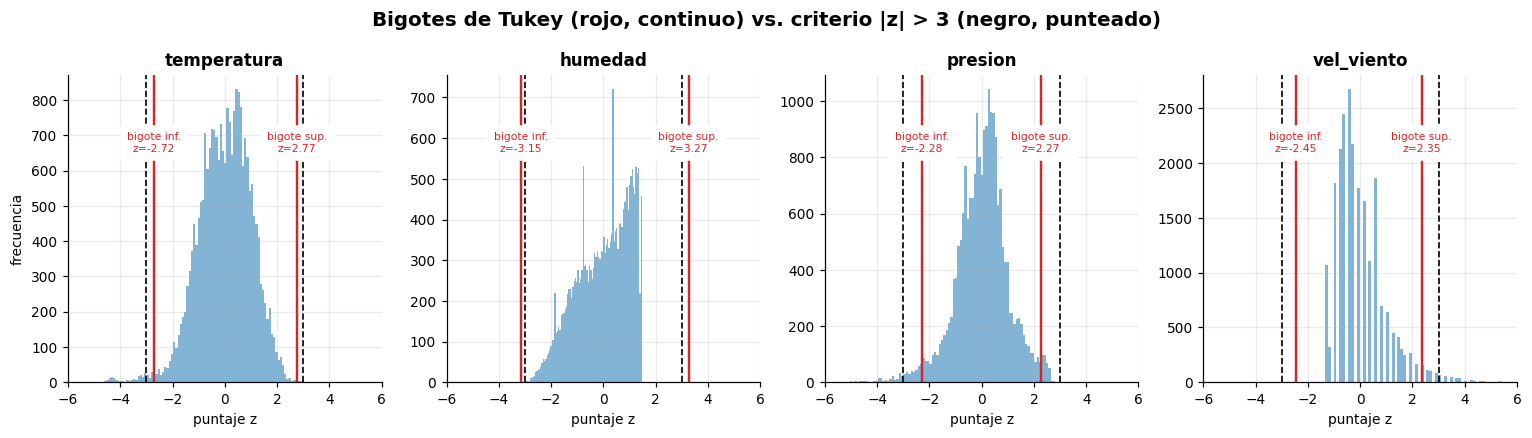

In [26]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, v in zip(axes, VARS_OUT):
    s = clima[v].dropna()
    mu, sd = s.mean(), s.std()
    z = (s - mu) / sd
    lo, hi = limites_iqr(s)

    ax.hist(z, bins=90, color=AZUL, alpha=.55)
    for lim, et, col in [((lo - mu) / sd, "bigote inf.", ROJO), ((hi - mu) / sd, "bigote sup.", ROJO)]:
        ax.axvline(lim, color=col, lw=1.6, ls="-")
        ax.annotate(f"{et}\nz={lim:.2f}", (lim, ax.get_ylim()[1]*.75), fontsize=7,
                    color=col, ha="center", backgroundcolor="white")
    for lim in (-3, 3):
        ax.axvline(lim, color="black", lw=1.1, ls="--")
    ax.set_title(v); ax.set_xlabel("puntaje z"); ax.set_xlim(-6, 6)
axes[0].set_ylabel("frecuencia")
fig.suptitle("Bigotes de Tukey (rojo, continuo) vs. criterio |z| > 3 (negro, punteado)",
             fontsize=13, fontweight="bold")
fig.tight_layout(); plt.show()

### Respuesta 2.c

**A cuántos desvíos están los outliers.** Los valores etiquetados como atípicos por el boxplot
se ubican, en promedio, a **2,8 – 3,4 desvíos** de la media, y los más extremos llegan bastante
más lejos:

| variable | \|z\| medio de los outliers | \|z\| máximo | outliers Tukey | de ellos con \|z\|>3 | total con \|z\|>3 en la serie |
|---|---|---|---|---|---|
| `temperatura` | 3,37 | 4,70 | 258 | 172 | 172 |
| `presion` | 2,76 | 5,23 | 844 | 192 | 192 |
| `vel_viento` | 3,41 | 8,65 | 659 | 366 | 366 |

Las dos últimas columnas coinciden exactamente en las tres variables, y ese es un resultado
importante: **toda observación con \|z\| > 3 fue también marcada por el boxplot**, pero no al
revés. El conjunto que detecta Tukey es un superconjunto estricto del que detecta el criterio de
los tres desvíos.

**Sí, hay una relación directa con los criterios del boxplot, y es cuantificable.** Si una
distribución fuese **exactamente normal**, el primer y tercer cuartil caen en z = ∓0,674 y el
IQR vale 1,349 desvíos; los bigotes de Tukey quedan entonces en

  z = ±(0,674 + 1,5 · 1,349) = **±2,698 desvíos**

es decir, el criterio del boxplot equivale, bajo normalidad, a un umbral de **2,7 σ** (que deja
fuera ~0,7 % de las observaciones), algo **más exigente** que el clásico 3 σ (0,27 %). Y eso es
exactamente lo que se observa en los datos: los bigotes calculados caen en z = −2,72 / +2,77
para `temperatura` y z = −2,28 / +2,27 para `presion`, muy cerca del valor teórico.

**Dónde los dos criterios se separan, y por qué.** La discrepancia aparece en `vel_viento`, cuyo
bigote superior está en z = +2,35 pero el inferior en z = −2,45 — un valor que **está fuera del
dominio** de la variable (el viento no puede ser negativo). Como la distribución es asimétrica,
el criterio de Tukey se adapta (marca 659 outliers, todos superiores) mientras que el criterio
de z lo haría de forma simétrica y por lo tanto incorrecta. En `humedad` la divergencia es total:
los bigotes caen en z = −3,15 y +3,27, fuera del rango posible, y por eso no detecta ningún
outlier.

**La conclusión metodológica es la que importa.** Los dos criterios coinciden en el orden de
magnitud pero **no son equivalentes**, y la diferencia es de robustez: la media y el desvío usados
por el z-score **están ellos mismos contaminados por los outliers** que se quieren detectar (los
230 registros antárticos bajan la media de temperatura y inflan el desvío, encogiendo los
z-scores de todos los demás y enmascarando outliers genuinos — el efecto de *masking*). Los
cuartiles y el IQR, en cambio, tienen un punto de ruptura del 25 % y no se ven afectados. Por eso
el boxplot detecta sistemáticamente **más** outliers que el criterio de 3 σ (258 contra 172 en
temperatura; 844 contra 192 en presión; 659 contra 366 en velocidad del viento) y es el criterio
preferible cuando la distribución es asimétrica o está contaminada, que es justamente el caso.

## 2.d — Filas con outliers en más de una variable: columna `CANT_OUT`

In [27]:
# Marca de outlier por variable, según criterio de Tukey
marcas = pd.DataFrame(index=clima.index)
for v in VARS_OUT:
    lo, hi = limites_iqr(clima[v].dropna())
    marcas[v] = ((clima[v] < lo) | (clima[v] > hi)).fillna(False)

clima["CANT_OUT"] = marcas.sum(axis=1).astype(int)

dist = clima["CANT_OUT"].value_counts().sort_index()
resumen_out = pd.DataFrame({"filas": dist, "% del total": (100 * dist / len(clima)).round(2)})
print(resumen_out.to_string())
print(f"\nFilas con al menos un outlier : {(clima['CANT_OUT'] >= 1).sum():,} "
      f"({100*(clima['CANT_OUT']>=1).mean():.1f} %)")
print(f"Filas con dos o más outliers  : {(clima['CANT_OUT'] >= 2).sum():,} "
      f"({100*(clima['CANT_OUT']>=2).mean():.1f} %)")
print(f"\nOutliers marcados por variable:\n{marcas.sum().to_string()}")

          filas  % del total
CANT_OUT                    
0         21582      93.7600
1          1167       5.0700
2           216       0.9400
3            54       0.2300

Filas con al menos un outlier : 1,437 (6.2 %)
Filas con dos o más outliers  : 270 (1.2 %)

Outliers marcados por variable:
temperatura    258
humedad          0
presion        844
vel_viento     659


In [28]:
# ¿Qué combinaciones de variables se dan juntas?
combos = (marcas[clima["CANT_OUT"] >= 1]
          .apply(lambda f: " + ".join([v for v in VARS_OUT if f[v]]), axis=1)
          .value_counts())
print("Combinaciones de variables atípicas observadas:")
print(combos.to_string())

print("\nCoeficiente de asociación (phi) entre las marcas de outlier:")
print(marcas[VARS_OUT].astype(int).corr().round(2).to_string())

Combinaciones de variables atípicas observadas:
presion                               609
vel_viento                            451
presion + vel_viento                  119
temperatura                           107
temperatura + presion                  62
temperatura + presion + vel_viento     54
temperatura + vel_viento               35

Coeficiente de asociación (phi) entre las marcas de outlier:
             temperatura  humedad  presion  vel_viento
temperatura       1.0000      NaN   0.2300      0.2000
humedad              NaN      NaN      NaN         NaN
presion           0.2300      NaN   1.0000      0.2100
vel_viento        0.2000      NaN   0.2100      1.0000


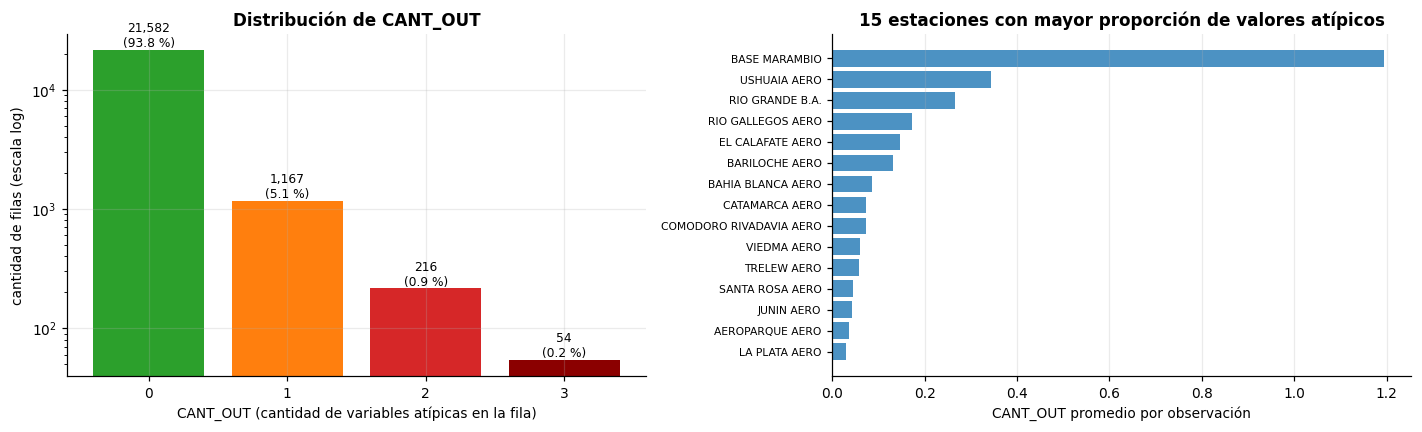

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# --- Gráfico 1: distribución de CANT_OUT
b = axes[0].bar(dist.index.astype(str), dist.values, color=[VERDE, NARANJA, ROJO, "#8B0000"][:len(dist)])
axes[0].set_yscale("log")
axes[0].set_xlabel("CANT_OUT (cantidad de variables atípicas en la fila)")
axes[0].set_ylabel("cantidad de filas (escala log)")
axes[0].set_title("Distribución de CANT_OUT")
for r, val in zip(b, dist.values):
    axes[0].annotate(f"{val:,}\n({100*val/len(clima):.1f} %)",
                     (r.get_x() + r.get_width()/2, val), ha="center", va="bottom", fontsize=8)

# --- Gráfico 2: ¿en qué estaciones se concentran?
top = (clima.groupby("estacion_meteorologica")["CANT_OUT"]
            .agg(["mean", "size"]).sort_values("mean", ascending=False).head(15))
axes[1].barh(top.index[::-1], top["mean"][::-1], color=AZUL, alpha=.8)
axes[1].set_xlabel("CANT_OUT promedio por observación")
axes[1].set_title("15 estaciones con mayor proporción de valores atípicos")
axes[1].tick_params(axis="y", labelsize=7); axes[1].grid(axis="y", alpha=0)
fig.tight_layout(); plt.show()

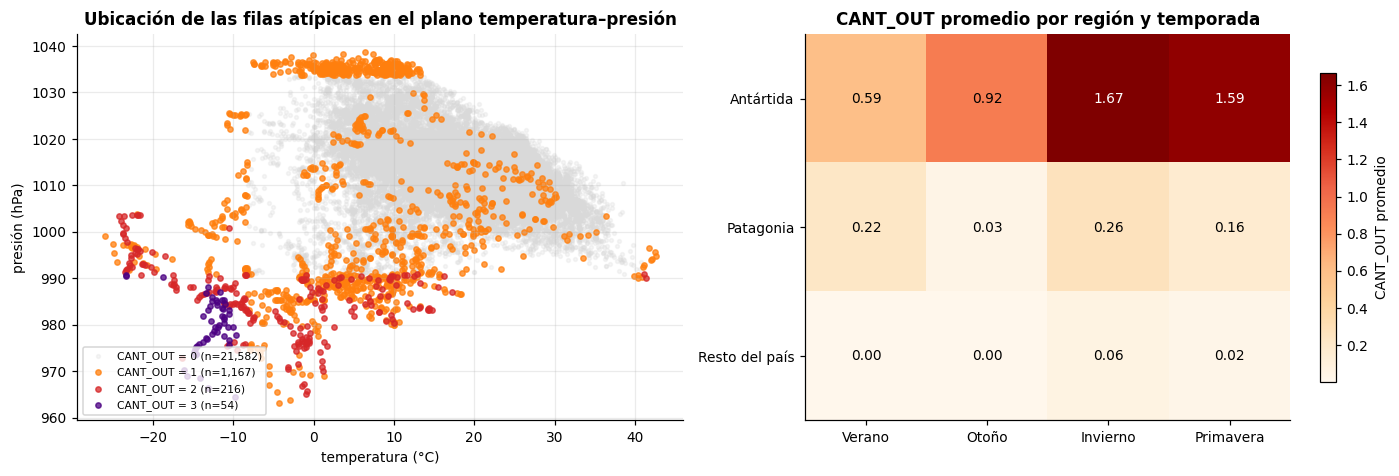

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

# --- Gráfico 3: dónde caen las filas atípicas en el espacio temperatura-presión
colores = {0: "#d9d9d9", 1: NARANJA, 2: ROJO, 3: "#4B0082"}
for c in sorted(clima["CANT_OUT"].unique()):
    sub = clima[clima["CANT_OUT"] == c]
    axes[0].scatter(sub["temperatura"], sub["presion"], s=6 if c == 0 else 12,
                    alpha=.25 if c == 0 else .75, color=colores[c],
                    label=f"CANT_OUT = {c} (n={len(sub):,})", zorder=c)
axes[0].set_xlabel("temperatura (°C)"); axes[0].set_ylabel("presión (hPa)")
axes[0].set_title("Ubicación de las filas atípicas en el plano temperatura–presión")
axes[0].legend(fontsize=7, loc="lower left")

# --- Gráfico 4: CANT_OUT promedio por región y temporada
piv = clima.pivot_table(index="region", columns="temporada", values="CANT_OUT", aggfunc="mean")
piv = piv[["Verano", "Otoño", "Invierno", "Primavera"]]
im = axes[1].imshow(piv.values, cmap="OrRd", aspect="auto")
axes[1].set_xticks(range(len(piv.columns)), piv.columns)
axes[1].set_yticks(range(len(piv.index)), piv.index)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        axes[1].text(j, i, f"{piv.values[i, j]:.2f}", ha="center", va="center", fontsize=9,
                     color="white" if piv.values[i, j] > piv.values.max()*.6 else "black")
axes[1].set_title("CANT_OUT promedio por región y temporada")
axes[1].grid(False)
plt.colorbar(im, ax=axes[1], shrink=.8, label="CANT_OUT promedio")
fig.tight_layout(); plt.show()

### Respuesta 2.d

**Sí, existen filas con outliers en más de una variable, y no es por azar.**

| CANT_OUT | filas | % |
|---|---|---|
| 0 | 21.582 | 93,8 % |
| 1 | 1.167 | 5,1 % |
| 2 | 216 | 0,9 % |
| 3 | 54 | 0,2 % |

Hay **270 observaciones (1,2 %) que son atípicas simultáneamente en dos o más variables**, y 54
que lo son en las tres. Que esto no sea azar se demuestra con un cálculo simple: si las marcas
fueran independientes, la probabilidad conjunta de que una fila sea outlier en temperatura *y*
presión sería 0,0112 × 0,0367, lo que daría unas **9,5 filas esperadas** — y se observan **116**.
La coincidencia es **doce veces mayor que la esperada bajo independencia**, lo que confirma que
las anomalías están **estructuradas**, no dispersas. Los coeficientes φ entre las marcas (0,20 a
0,23) apuntan en la misma dirección.

**Los cuatro gráficos muestran dónde se ubican esos valores y cuentan la misma historia.**

1. La **distribución de `CANT_OUT`** (escala logarítmica) decae fuertemente pero con una cola que
   llega a 3: ninguna fila es atípica en las cuatro variables, porque `humedad` no aporta
   outliers.
2. El **ranking por estación** es contundente: **Base Marambio** encabeza con un `CANT_OUT`
   promedio de 1,19 —más del triple que la siguiente, Ushuaia (0,34), y treinta veces el de una
   estación del litoral como Aeroparque (0,04)—. **Las seis primeras posiciones son todas
   antárticas o patagónicas** (Marambio, Ushuaia, Río Grande, Río Gallegos, El Calafate y
   Bariloche); recién en el séptimo lugar aparece una estación pampeana (Bahía Blanca). Las
   combinaciones observadas también son coherentes: las más frecuentes son presión sola (609
   casos) y viento solo (451), y la terna completa se da 54 veces.
3. El **diagrama de dispersión temperatura–presión** muestra que las filas con `CANT_OUT ≥ 2` no
   están repartidas por los bordes de la nube sino agrupadas en un **cúmulo compacto en el
   cuadrante inferior izquierdo** (baja temperatura y baja presión), claramente separado de la
   masa principal de datos. Visualmente es otra población, no una dispersión de la misma.
4. El **mapa de calor por región y temporada** cierra el argumento: el `CANT_OUT` promedio de la
   Antártida es un orden de magnitud mayor que el del resto del país en todas las temporadas, y
   alcanza su pico en invierno. En el "resto del país" el indicador es prácticamente cero
   durante todo el año.

**Qué se concluye.** Las observaciones multivariadamente atípicas no son errores de carga ni
ruido de instrumentos: son **el registro fiel de un régimen climático distinto**. Eliminarlas —la
reacción refleja frente a un boxplot con muchos puntos rojos— implicaría borrar del dataset casi
toda la información antártica y patagónica y dejar un conjunto de datos sesgado hacia el clima
templado. El tratamiento correcto es el opuesto: **conservar las filas y modelar la
heterogeneidad**, ya sea estratificando por región, incorporando la estación meteorológica como
variable explicativa, o normalizando dentro de cada grupo. La columna `CANT_OUT` es útil
precisamente para eso: no como filtro de descarte sino como **indicador de a qué subpoblación
pertenece cada registro**.

<a id="ej3"></a>

---

# Ejercicio 3 — Discretización del atributo `humedad`

Se transforma la variable continua `humedad` (humedad relativa, en %) en una variable discreta
de **cinco categorías**, mediante tres criterios distintos, y se comparan los resultados.

count   23,014.0000
mean        68.7000
std         21.1900
min          6.0000
25%         53.0000
50%         72.0000
75%         87.0000
max        100.0000

Valores distintos: 95  (la variable se informa con resolución de 1 %)


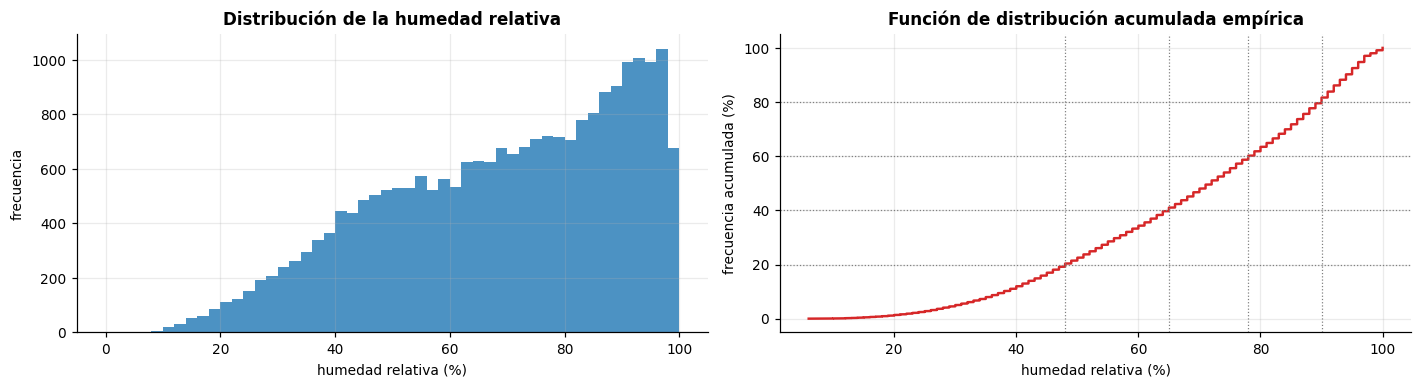

In [31]:
hum = clima["humedad"].dropna()
print(hum.describe().round(2).to_string())
print(f"\nValores distintos: {hum.nunique()}  (la variable se informa con resolución de 1 %)")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
axes[0].hist(hum, bins=np.arange(0, 102, 2), color=AZUL, alpha=.8)
axes[0].set_xlabel("humedad relativa (%)"); axes[0].set_ylabel("frecuencia")
axes[0].set_title("Distribución de la humedad relativa")
axes[1].plot(np.sort(hum), np.linspace(0, 100, len(hum)), color=ROJO, lw=1.6)
for p in [20, 40, 60, 80]:
    axes[1].axhline(p, ls=":", color=GRIS, lw=.8)
    axes[1].axvline(np.percentile(hum, p), ls=":", color=GRIS, lw=.8)
axes[1].set_xlabel("humedad relativa (%)"); axes[1].set_ylabel("frecuencia acumulada (%)")
axes[1].set_title("Función de distribución acumulada empírica")
fig.tight_layout(); plt.show()

## 3.a — Cinco rangos definidos a partir del análisis de frecuencias

In [32]:
# Análisis de frecuencia previo: se observa la variable en tramos finos para elegir los cortes
frec = pd.cut(hum, bins=np.arange(0, 111, 10), right=False).value_counts().sort_index()
tabla_frec = pd.DataFrame({"frecuencia": frec, "%": (100*frec/len(hum)).round(1)})
tabla_frec["% acumulado"] = tabla_frec["%"].cumsum().round(1)
print(tabla_frec.to_string())

            frecuencia       %  % acumulado
humedad                                    
[0, 10)              7  0.0000       0.0000
[10, 20)           248  1.1000       1.1000
[20, 30)           783  3.4000       4.5000
[30, 40)          1498  6.5000      11.0000
[40, 50)          2393 10.4000      21.4000
[50, 60)          2720 11.8000      33.2000
[60, 70)          3091 13.4000      46.6000
[70, 80)          3483 15.1000      61.7000
[80, 90)          4081 17.7000      79.4000
[90, 100)         4505 19.6000      99.0000
[100, 110)         205  0.9000      99.9000


In [33]:
# Cortes elegidos a partir de la lectura anterior, con sentido meteorológico
CORTES_A = [0, 30, 50, 70, 90, 100.001]   # el borde superior incluye el valor 100
ETIQ_A = ["Muy seco (<30)", "Seco (30-50)", "Moderado (50-70)", "Húmedo (70-90)", "Saturado (90-100)"]

clima["hum_frecuencia"] = pd.cut(clima["humedad"], bins=CORTES_A, labels=ETIQ_A,
                                 include_lowest=True, right=False)
f_a = clima["hum_frecuencia"].value_counts().reindex(ETIQ_A)
pd.DataFrame({"frecuencia": f_a, "%": (100*f_a/f_a.sum()).round(1),
              "amplitud del intervalo": [30, 20, 20, 20, 10]})

,frecuencia,%,amplitud del intervalo
hum_frecuencia,,,
Muy seco (<30),1038,4.5000,30
Seco (30-50),3891,16.9000,20
Moderado (50-70),5811,25.2000,20
Húmedo (70-90),7564,32.9000,20
Saturado (90-100),4710,20.5000,10


### Respuesta 3.a

**Cortes elegidos:** [0, 30), [30, 50), [50, 70), [70, 90) y [90, 100]. Surgen de leer la tabla
de frecuencias en tramos de 10 %: por debajo de 30 % la frecuencia es marginal (4,5 % del total),
entre 30 y 90 % la densidad crece de forma sostenida tramo a tramo, y el tramo [90, 100) es el
**modal**, con el 19,6 % de las observaciones. La distribución es monótonamente creciente hacia
la saturación, efecto del **truncamiento en 100 %**: la humedad relativa no puede superar ese
tope, de modo que la masa se acumula contra él (205 observaciones valen exactamente 100 %). Los cortes
además coinciden con umbrales de uso meteorológico habitual, lo que hace que las categorías
tengan nombre propio y sean interpretables.

**¿Qué tipo de variable se obtiene?** Una variable **cualitativa (categórica) ordinal**. Es
categórica porque sus valores son etiquetas y no admiten operaciones aritméticas (no tiene
sentido "promediar" *Seco* con *Húmedo*), y es **ordinal** porque las categorías tienen un orden
natural inequívoco: *Muy seco* < *Seco* < *Moderado* < *Húmedo* < *Saturado*. En Pandas el tipo
resultante es `category` con `ordered=True`, lo que habilita comparaciones (`<`, `>`) y el cálculo
de mediana y cuantiles, pero no de media ni desvío. Al pasar de escala de razón a escala
ordinal se **pierde información sobre la magnitud de las diferencias**: el salto de 29 % a 31 %
cambia de categoría mientras que el de 30 % a 49 % no.

## 3.b — Cinco rangos por intervalos de clase (anchos iguales)

In [34]:
lim_inf, lim_sup = hum.min(), hum.max()
amplitud = (lim_sup - lim_inf) / 5
CORTES_B = [lim_inf + i * amplitud for i in range(6)]
print(f"Mínimo = {lim_inf:.0f} %   Máximo = {lim_sup:.0f} %   Rango = {lim_sup-lim_inf:.0f}")
print(f"Amplitud de cada clase = rango / 5 = {amplitud:.1f} puntos porcentuales")
print("Límites de clase:", [round(c, 1) for c in CORTES_B])

ETIQ_B = [f"C{i+1} [{CORTES_B[i]:.1f}–{CORTES_B[i+1]:.1f})" for i in range(5)]
clima["hum_intervalos"] = pd.cut(clima["humedad"], bins=CORTES_B, labels=ETIQ_B,
                                 include_lowest=True)
f_b = clima["hum_intervalos"].value_counts().reindex(ETIQ_B)
pd.DataFrame({"frecuencia": f_b, "%": (100*f_b/f_b.sum()).round(1),
              "amplitud": [round(amplitud, 1)]*5})

Mínimo = 6 %   Máximo = 100 %   Rango = 94
Amplitud de cada clase = rango / 5 = 18.8 puntos porcentuales
Límites de clase: [np.float64(6.0), np.float64(24.8), np.float64(43.6), np.float64(62.4), np.float64(81.2), np.float64(100.0)]


,frecuencia,%,amplitud
hum_intervalos,,,
C1 [6.0–24.8),560,2.4000,18.8000
C2 [24.8–43.6),2859,12.4000,18.8000
C3 [43.6–62.4),5081,22.1000,18.8000
C4 [62.4–81.2),6430,27.9000,18.8000
C5 [81.2–100.0),8084,35.1000,18.8000


## 3.c — Cinco rangos por percentiles cada 20 %

In [35]:
CORTES_C = [np.percentile(hum, p) for p in [0, 20, 40, 60, 80, 100]]
print("Percentiles de la humedad:")
for p, c in zip([0, 20, 40, 60, 80, 100], CORTES_C):
    print(f"  P{p:>3} = {c:6.1f} %")

ETIQ_C = ["Q1 [0-20%)", "Q2 [20-40%)", "Q3 [40-60%)", "Q4 [60-80%)", "Q5 [80-100%]"]
clima["hum_percentiles"] = pd.qcut(clima["humedad"], q=5, labels=ETIQ_C)
f_c = clima["hum_percentiles"].value_counts().reindex(ETIQ_C)
pd.DataFrame({"frecuencia": f_c, "%": (100*f_c/f_c.sum()).round(1),
              "rango real": [f"{CORTES_C[i]:.0f} – {CORTES_C[i+1]:.0f}" for i in range(5)]})

Percentiles de la humedad:
  P  0 =    6.0 %
  P 20 =   48.0 %
  P 40 =   65.0 %
  P 60 =   78.0 %
  P 80 =   90.0 %
  P100 =  100.0 %


,frecuencia,%,rango real
hum_percentiles,,,
Q1 [0-20%),4684,20.4000,6 – 48
Q2 [20-40%),4755,20.7000,48 – 65
Q3 [40-60%),4413,19.2000,65 – 78
Q4 [60-80%),4938,21.5000,78 – 90
Q5 [80-100%],4224,18.4000,90 – 100


## 3.d — Comparación de los tres abordajes

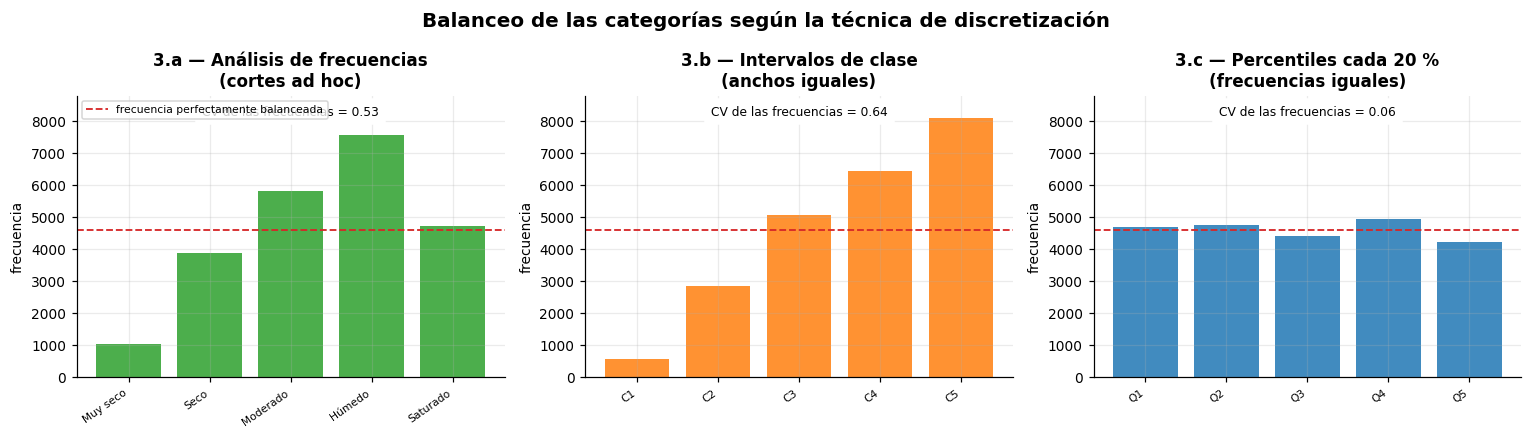

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (f, tit, col) in zip(axes, [
        (f_a, "3.a — Análisis de frecuencias\n(cortes ad hoc)", VERDE),
        (f_b, "3.b — Intervalos de clase\n(anchos iguales)", NARANJA),
        (f_c, "3.c — Percentiles cada 20 %\n(frecuencias iguales)", AZUL)]):
    ax.bar(range(len(f)), f.values, color=col, alpha=.85)
    ax.axhline(len(hum)/5, ls="--", color=ROJO, lw=1.2, label="frecuencia perfectamente balanceada")
    ax.set_xticks(range(len(f)))
    ax.set_xticklabels([e.split(" (")[0].split(" [")[0] for e in f.index], rotation=35,
                       ha="right", fontsize=7)
    ax.set_title(tit); ax.set_ylabel("frecuencia"); ax.set_ylim(0, 8800)
    cv = f.std() / f.mean()
    ax.annotate(f"CV de las frecuencias = {cv:.2f}", (.5, .93), xycoords="axes fraction",
                ha="center", fontsize=8, backgroundcolor="white")
axes[0].legend(fontsize=7, loc="upper left")
fig.suptitle("Balanceo de las categorías según la técnica de discretización",
             fontsize=13, fontweight="bold")
fig.tight_layout(); plt.show()

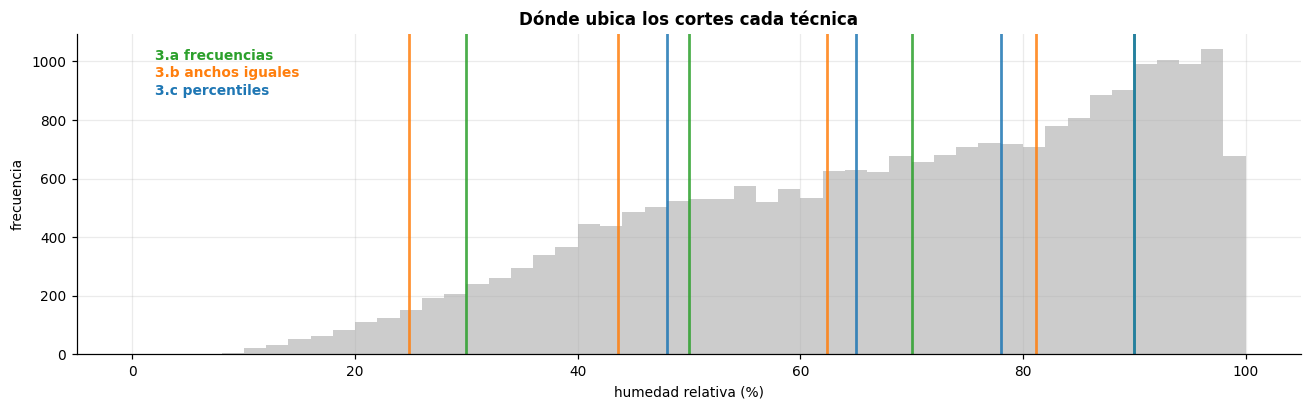

In [37]:
# Superposición de los cortes de cada método sobre el histograma
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.hist(hum, bins=np.arange(0, 102, 2), color="#cccccc")
for cortes, col, et, dy in [(CORTES_A, VERDE, "3.a frecuencias", 0),
                            (CORTES_B, NARANJA, "3.b anchos iguales", 60),
                            (CORTES_C, AZUL, "3.c percentiles", 120)]:
    for c in cortes[1:-1]:
        ax.axvline(c, color=col, lw=1.8, alpha=.85)
    ax.annotate(et, (2, ax.get_ylim()[1]*.92 - dy), color=col, fontsize=9, fontweight="bold")
ax.set_xlabel("humedad relativa (%)"); ax.set_ylabel("frecuencia")
ax.set_title("Dónde ubica los cortes cada técnica")
fig.tight_layout(); plt.show()

In [38]:
# ¿Son consistentes entre sí? Tabla de contingencia y medida de acuerdo
from sklearn.metrics import adjusted_rand_score

ct = pd.crosstab(clima["hum_intervalos"], clima["hum_percentiles"])
print("Tabla de contingencia: intervalos de clase (filas) vs. percentiles (columnas)\n")
print(ct.to_string())

sub = clima.dropna(subset=["hum_frecuencia", "hum_intervalos", "hum_percentiles"])
print("\nÍndice de Rand ajustado entre particiones (1 = idénticas, 0 = azar):")
print(f"  3.a  vs  3.b : {adjusted_rand_score(sub['hum_frecuencia'], sub['hum_intervalos']):.3f}")
print(f"  3.a  vs  3.c : {adjusted_rand_score(sub['hum_frecuencia'], sub['hum_percentiles']):.3f}")
print(f"  3.b  vs  3.c : {adjusted_rand_score(sub['hum_intervalos'], sub['hum_percentiles']):.3f}")

Tabla de contingencia: intervalos de clase (filas) vs. percentiles (columnas)

hum_percentiles  Q1 [0-20%)  Q2 [20-40%)  Q3 [40-60%)  Q4 [60-80%)  Q5 [80-100%]
hum_intervalos                                                                  
C1 [6.0–24.8)           560            0            0            0             0
C2 [24.8–43.6)         2859            0            0            0             0
C3 [43.6–62.4)         1265         3816            0            0             0
C4 [62.4–81.2)            0          939         4413         1078             0
C5 [81.2–100.0)           0            0            0         3860          4224

Índice de Rand ajustado entre particiones (1 = idénticas, 0 = azar):
  3.a  vs  3.b : 0.426
  3.a  vs  3.c : 0.632
  3.b  vs  3.c : 0.531


### Respuesta 3.d

**Balanceo de las categorías.** Las tres técnicas producen particiones de la misma variable en la
misma cantidad de clases, y sin embargo los resultados difieren de manera drástica:

| técnica | frecuencia mínima | frecuencia máxima | razón máx/mín | CV de las frecuencias |
|---|---|---|---|---|
| 3.a frecuencias (ad hoc) | 1.038 | 7.564 | 7,3 | 0,53 |
| 3.b intervalos de clase | 560 | 8.084 | 14,4 | 0,64 |
| 3.c percentiles | 4.224 | 4.938 | 1,2 | 0,06 |

- La **discretización por percentiles es, por construcción, perfectamente balanceada**: cada clase
  contiene el 20 % de los casos. El CV de las frecuencias es 0,06 y la pequeña desviación del
  ideal se debe únicamente a que la humedad se informa con resolución entera y hay empates en
  los puntos de corte (muchas observaciones valen exactamente 87 % o 100 %, y no pueden
  repartirse entre dos clases).
- La **discretización por intervalos de clase es la más desbalanceada**: la clase más poblada
  tiene 14 veces más observaciones que la menos poblada. El motivo es directo: impone
  intervalos de igual amplitud sobre una distribución **fuertemente asimétrica a izquierda**, de
  modo que las clases bajas quedan casi vacías y las altas saturadas.
- La **definición ad hoc a partir del análisis de frecuencias** queda en un punto intermedio,
  algo mejor balanceada que la de anchos iguales porque el corte superior (90 %) fue elegido
  justamente para aislar la acumulación contra el techo de saturación.

**¿Son consistentes todos los abordajes?** **Parcialmente, y la inconsistencia es informativa.**
El índice de Rand ajustado entre las particiones da 0,426 (3.a vs 3.b), 0,632 (3.a vs 3.c) y
0,531 (3.b vs 3.c): hay acuerdo moderado, lejos de la identidad. Es interesante que el mayor
acuerdo se dé entre los **cortes ad hoc y los percentiles** —al elegir los cortes mirando la
tabla de frecuencias se terminó, sin proponérselo, aproximando una partición por cuantiles—,
y el menor entre los cortes ad hoc y los intervalos de clase.

La tabla de contingencia muestra que **ninguna clase de un método coincide exactamente con una
del otro**, y que las diferencias se concentran en el centro de la distribución: el intervalo de
clase C4 [62,4–81,2) se reparte entre **tres quintiles distintos** (Q2, Q3 y Q4), porque en esa
zona la densidad es alta y unos pocos puntos de humedad mueven miles de casos de categoría. En
los extremos, en cambio, hay coincidencia: las 560 observaciones de C1 caen todas en Q1, y las
4.224 del quintil superior caen todas en C5.

**Qué técnica usar.** Depende del objetivo, y el criterio es el siguiente:

- **Percentiles** cuando la variable discretizada va a alimentar un modelo de clasificación, un
  árbol de decisión o un análisis comparativo entre grupos: el balanceo evita que las clases
  raras sean ignoradas por el algoritmo y maximiza la entropía de la partición.
- **Intervalos de clase** cuando importa la **interpretabilidad física** de los cortes y la
  comparabilidad con otros estudios: los límites son fijos y no dependen de la muestra, de modo
  que la misma regla aplicada a otro año produce categorías comparables. Los percentiles, en
  cambio, **se mueven con los datos** — el P20 de este dataset es 48 %, pero en un año más húmedo
  sería otro, y las categorías dejarían de ser comparables entre períodos.
- **Cortes ad hoc con sentido de dominio** cuando el destinatario del análisis es un experto del
  área, porque las categorías resultantes tienen significado propio.

La conclusión general es que **la discretización no es una operación neutra**: introduce una
decisión del analista que condiciona todo el análisis posterior, y esa decisión debe declararse
y justificarse explícitamente.

<a id="ej4"></a>

---

# Ejercicio 4 — Normalización

## Entrada en calor (papel y lápiz)

**Dominio:** E = {1, 5, 9, 17, 18, 34, 45, 89, 99}. Se pide normalizar el valor **65**.

---

### Escalado decimal

El escalado decimal divide por la potencia de 10 más chica que lleve **todos** los valores del
dominio al intervalo (−1, 1):

$$v' = \frac{v}{10^{\,j}} \qquad \text{donde } j \text{ es el menor entero tal que } \max(|v|) / 10^{\,j} < 1$$

El máximo valor absoluto del dominio es **99**. Se prueba:

- j = 1 → 99 / 10 = 9,9 ≥ 1 ✗
- **j = 2 → 99 / 100 = 0,99 < 1 ✓**

Con j = 2:

$$v' = \frac{65}{10^{2}} = \frac{65}{100} = \boxed{0{,}65}$$

---

### Mínimo-máximo

Con el rango de destino estándar [0, 1], mínimo = 1 y máximo = 99:

$$v' = \frac{v - \min}{\max - \min}\,(nuevo\_max - nuevo\_min) + nuevo\_min
     = \frac{65 - 1}{99 - 1} = \frac{64}{98} = \boxed{0{,}6531}$$

---

### Comparación

Los dos resultados son numéricamente parecidos (0,650 contra 0,653) **por casualidad**: ocurre
porque el mínimo del dominio (1) está muy cerca de cero y el máximo (99) muy cerca de 100. Son
métodos conceptualmente distintos:

- El **escalado decimal** solo mira el **orden de magnitud** del máximo; ignora por completo el
  mínimo y no garantiza que el resultado cubra todo el rango [0, 1] (con E = {1, …, 12} daría
  valores entre 0,01 y 0,12, desaprovechando el 88 % del rango disponible). A cambio, es
  trivial de invertir y de comunicar, y **preserva el cero** de la variable original.
- El **mínimo-máximo** usa ambos extremos y garantiza que el mínimo del dominio vaya a 0 y el
  máximo a 1, aprovechando todo el rango. Su debilidad es la **fragilidad ante outliers**: si al
  dominio se le agregara un solo valor de 10.000, todos los demás se comprimirían cerca de 0.

Un detalle no menor: **65 no pertenece a E**, pero sí está dentro de su rango, de modo que ambas
fórmulas se aplican sin problema. Si en cambio el valor a normalizar fuera 150 (fuera del rango
de entrenamiento), mínimo-máximo devolvería 1,52 —fuera del intervalo [0, 1]— mientras que el
escalado decimal devolvería 1,50; ambos romperían su garantía de rango, cuestión relevante
cuando se normaliza un conjunto de prueba con los parámetros del conjunto de entrenamiento.

## Normalización de `temperatura` y `vel_viento` (dataset `clima_smn.csv`)

In [39]:
def norm_min_max(s, nuevo_min=0.0, nuevo_max=1.0):
    '''Normalización mínimo-máximo al intervalo [nuevo_min, nuevo_max].'''
    return (s - s.min()) / (s.max() - s.min()) * (nuevo_max - nuevo_min) + nuevo_min

def norm_zscore(s):
    '''Normalización z-score: media 0, desvío 1.'''
    return (s - s.mean()) / s.std()

def norm_decimal(s):
    '''Escalado decimal: divide por 10^j, con j el menor entero que lleva todo a (-1, 1).'''
    j = int(np.ceil(np.log10(s.abs().max() + 1e-12)))
    j = max(j, 0)
    while s.abs().max() / 10**j >= 1:
        j += 1
    return s / 10**j, j

VARS_NORM = ["temperatura", "vel_viento"]
norm_df = clima[VARS_NORM].copy()

for v in VARS_NORM:
    s = clima[v]
    norm_df[f"{v}_minmax"] = norm_min_max(s)                 # 4.a
    norm_df[f"{v}_zscore"] = norm_zscore(s)                  # 4.b
    dec, j = norm_decimal(s)                                 # 4.c
    norm_df[f"{v}_decimal"] = dec
    print(f"{v:<12} min={s.min():>7.1f}  max={s.max():>6.1f}  "
          f"max|v|={s.abs().max():>6.1f}  ->  j = {j}  (divide por 10^{j})")

norm_df.head(8).round(4)

temperatura  min=  -26.0  max=  42.6  max|v|=  42.6  ->  j = 2  (divide por 10^2)
vel_viento   min=    0.0  max= 100.0  max|v|= 100.0  ->  j = 3  (divide por 10^3)


,temperatura,vel_viento,temperatura_minmax,temperatura_zscore,temperatura_decimal,vel_viento_minmax,vel_viento_zscore,vel_viento_decimal
0,15.6000,9.0000,0.6064,-0.0571,0.1560,0.0900,-0.4504,0.0090
1,15.3000,9.0000,0.6020,-0.0906,0.1530,0.0900,-0.4504,0.0090
2,15.1000,9.0000,0.5991,-0.1129,0.1510,0.0900,-0.4504,0.0090
3,14.8000,9.0000,0.5948,-0.1464,0.1480,0.0900,-0.4504,0.0090
4,15.0000,17.0000,0.5977,-0.1240,0.1500,0.1700,0.3494,0.0170
5,14.2000,15.0000,0.5860,-0.2133,0.1420,0.1500,0.1495,0.0150
6,14.5000,15.0000,0.5904,-0.1798,0.1450,0.1500,0.1495,0.0150
7,13.4000,15.0000,0.5743,-0.3026,0.1340,0.1500,0.1495,0.0150


In [40]:
# 4.d — Estadísticos comparados
filas = []
for v in VARS_NORM:
    for suf, nombre in [("", "original"), ("_minmax", "mín-máx"),
                        ("_zscore", "z-score"), ("_decimal", "decimal")]:
        s = norm_df[f"{v}{suf}"].dropna()
        filas.append({"variable": v, "técnica": nombre, "n": len(s),
                      "mín": s.min(), "máx": s.max(), "rango": s.max()-s.min(),
                      "media": s.mean(), "desvío": s.std(),
                      "asimetría": stats.skew(s), "curtosis": stats.kurtosis(s)})
tabla_norm = pd.DataFrame(filas).set_index(["variable", "técnica"])
tabla_norm.round(4)

n      mín      máx    rango   media  desvío  asimetría  curtosis
variable    técnica                                                                        
temperatura original  23019 -26.0000  42.6000  68.6000 16.1115  8.9605    -0.4488    0.7017
            mín-máx   23019   0.0000   1.0000   1.0000  0.6139  0.1306    -0.4488    0.7017
            z-score   23019  -4.6997   2.9561   7.6558 -0.0000  1.0000    -0.4488    0.7017
            decimal   23019  -0.2600   0.4260   0.6860  0.1611  0.0896    -0.4488    0.7017
vel_viento  original  23017   0.0000 100.0000 100.0000 13.5048 10.0028     1.7054    4.8862
            mín-máx   23017   0.0000   1.0000   1.0000  0.1350  0.1000     1.7054    4.8862
            z-score   23017  -1.3501   8.6471   9.9972  0.0000  1.0000     1.7054    4.8862
            decimal   23017   0.0000   0.1000   0.1000  0.0135  0.0100     1.7054    4.8862

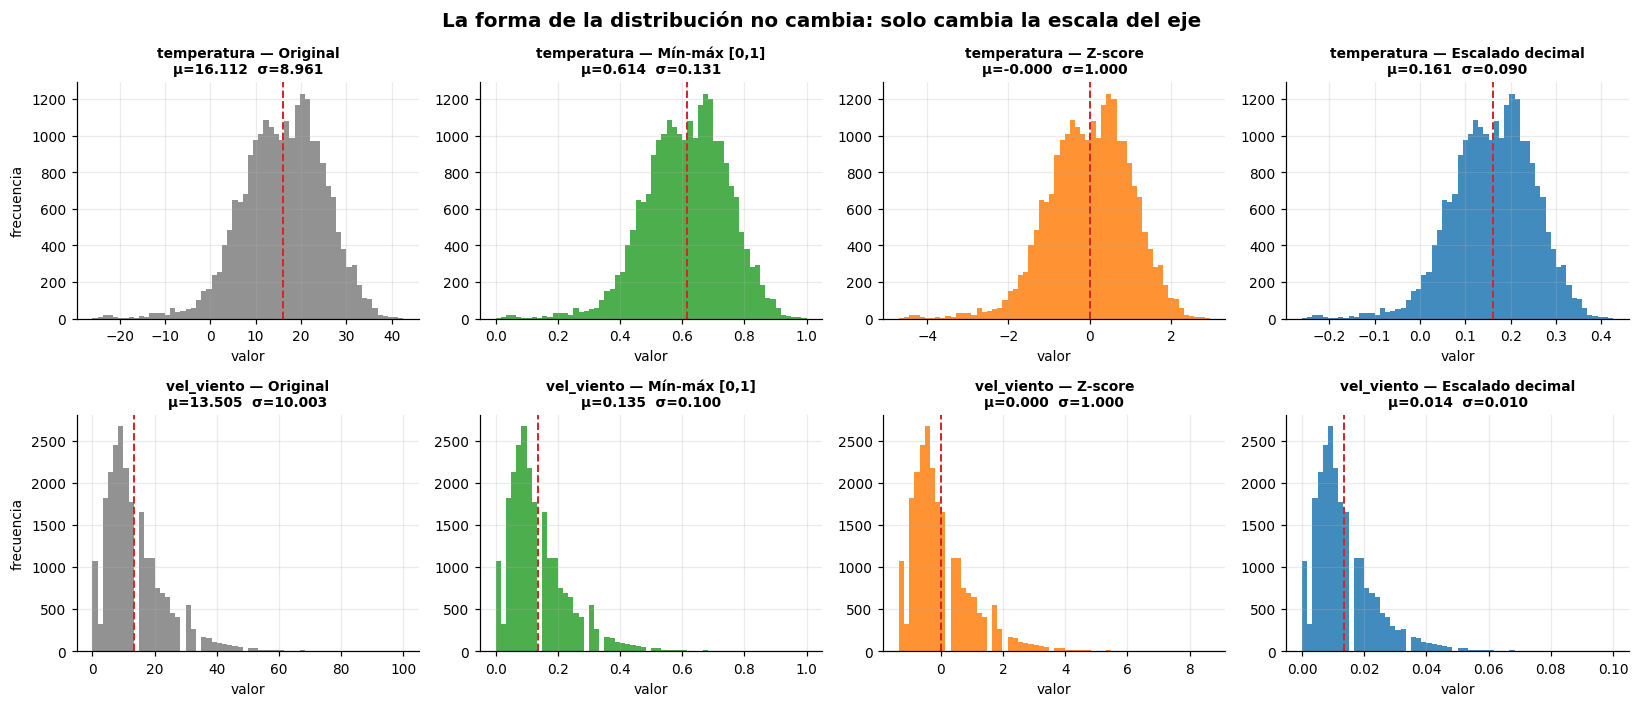

In [41]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for i, v in enumerate(VARS_NORM):
    for jx, (suf, nombre, col) in enumerate([("", "Original", GRIS), ("_minmax", "Mín-máx [0,1]", VERDE),
                                             ("_zscore", "Z-score", NARANJA), ("_decimal", "Escalado decimal", AZUL)]):
        ax = axes[i, jx]
        s = norm_df[f"{v}{suf}"].dropna()
        ax.hist(s, bins=60, color=col, alpha=.85)
        ax.axvline(s.mean(), color=ROJO, lw=1.3, ls="--")
        ax.set_title(f"{v} — {nombre}\nμ={s.mean():.3f}  σ={s.std():.3f}", fontsize=9)
        ax.set_xlabel("valor")
    axes[i, 0].set_ylabel("frecuencia")
fig.suptitle("La forma de la distribución no cambia: solo cambia la escala del eje",
             fontsize=13, fontweight="bold")
fig.tight_layout(); plt.show()

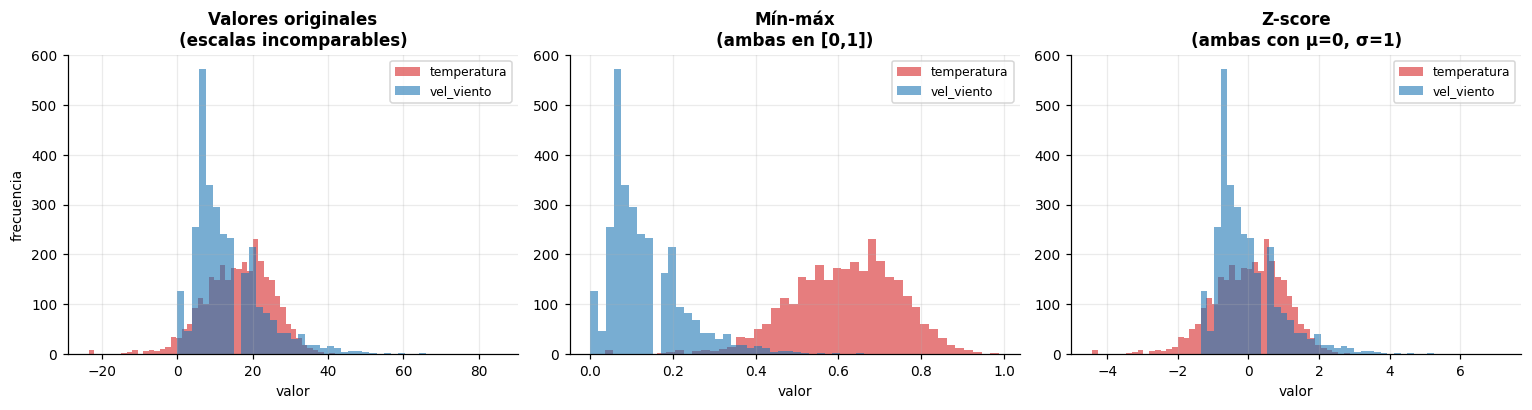

In [42]:
# Las dos variables en un mismo eje: antes y después de normalizar
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
muestra = norm_df.dropna().sample(3000, random_state=3)
for ax, (sufijo, tit) in zip(axes, [("", "Valores originales\n(escalas incomparables)"),
                                     ("_minmax", "Mín-máx\n(ambas en [0,1])"),
                                     ("_zscore", "Z-score\n(ambas con μ=0, σ=1)")]):
    ax.hist(muestra[f"temperatura{sufijo}"], bins=45, alpha=.6, color=ROJO, label="temperatura")
    ax.hist(muestra[f"vel_viento{sufijo}"], bins=45, alpha=.6, color=AZUL, label="vel_viento")
    ax.set_title(tit); ax.legend(fontsize=8); ax.set_xlabel("valor")
axes[0].set_ylabel("frecuencia")
fig.tight_layout(); plt.show()

### Respuesta 4.d

**Lo que cambia y lo que no.** Los tres métodos son **transformaciones lineales** de la forma
v' = (v − a)/b, y por lo tanto **no alteran la forma de la distribución**: los histogramas de las
cuatro versiones de cada variable son idénticos salvo por la escala del eje horizontal. La
asimetría y la curtosis se mantienen exactamente iguales en las cuatro versiones de cada
variable (temperatura: −0,449 y 0,702; vel_viento: 1,705 y 4,886). **Normalizar no "arregla" una distribución
asimétrica ni elimina outliers** — para eso hacen falta transformaciones no lineales como el
logaritmo o la raíz. Lo único que cambia es la **unidad de medida**.

**Qué hace cada método con los parámetros:**

| | rango resultante | media | desvío | preserva el 0 | sensible a outliers |
|---|---|---|---|---|---|
| **Mín-máx** | exactamente [0, 1] | arbitraria (0,61 / 0,14) | arbitrario | no | **mucho** |
| **Z-score** | no acotado (−4,70 a +2,96 la temperatura; −1,35 a +8,65 el viento) | exactamente 0 | exactamente 1 | no | moderadamente |
| **Decimal** | (−1, 1), sin usar todo el rango | escalada (0,161 / 0,0135) | escalado | **sí** | poco |

Hay un detalle importante en el escalado decimal. Para `temperatura`, max\|v\| = 42,6 → j = 2, y
la variable queda en [−0,26; 0,426]: ocupa apenas un tercio del rango disponible. Para
`vel_viento`, max\|v\| = 100 → j = 3, y queda en [0; 0,1]: usa **el 10 % del rango**. Es decir,
el escalado decimal **deja las dos variables en escalas todavía distintas entre sí** (una llega
a 0,43 y la otra a 0,10), de modo que no resuelve el problema de comparabilidad que motiva la
normalización. Su ventaja real es otra: es la única de las tres que **preserva el cero y el
signo** —un viento de 0 km/h sigue siendo 0— y es trivialmente invertible e interpretable.

**El tercer gráfico muestra el problema que la normalización viene a resolver.** Con los valores
originales, temperatura (−26 a 42,6 °C) y velocidad del viento (0 a 100 km/h) superpuestas en un
mismo eje son ilegibles: la temperatura queda comprimida en el tercio izquierdo. Tras
normalizar, ambas ocupan el mismo espacio y sus formas se pueden comparar directamente: se ve
de inmediato que la temperatura es aproximadamente simétrica y el viento marcadamente asimétrico
a derecha. Este es el motivo por el cual la normalización es obligatoria antes de cualquier
técnica basada en distancias (k-NN, k-medias) o en varianzas (PCA, que se usa en el Ejercicio 6):
sin ella, `vel_viento` dominaría cualquier cálculo por el solo hecho de tener números más
grandes.

## 4.e — Boxplots y agrupamiento por `temporada`

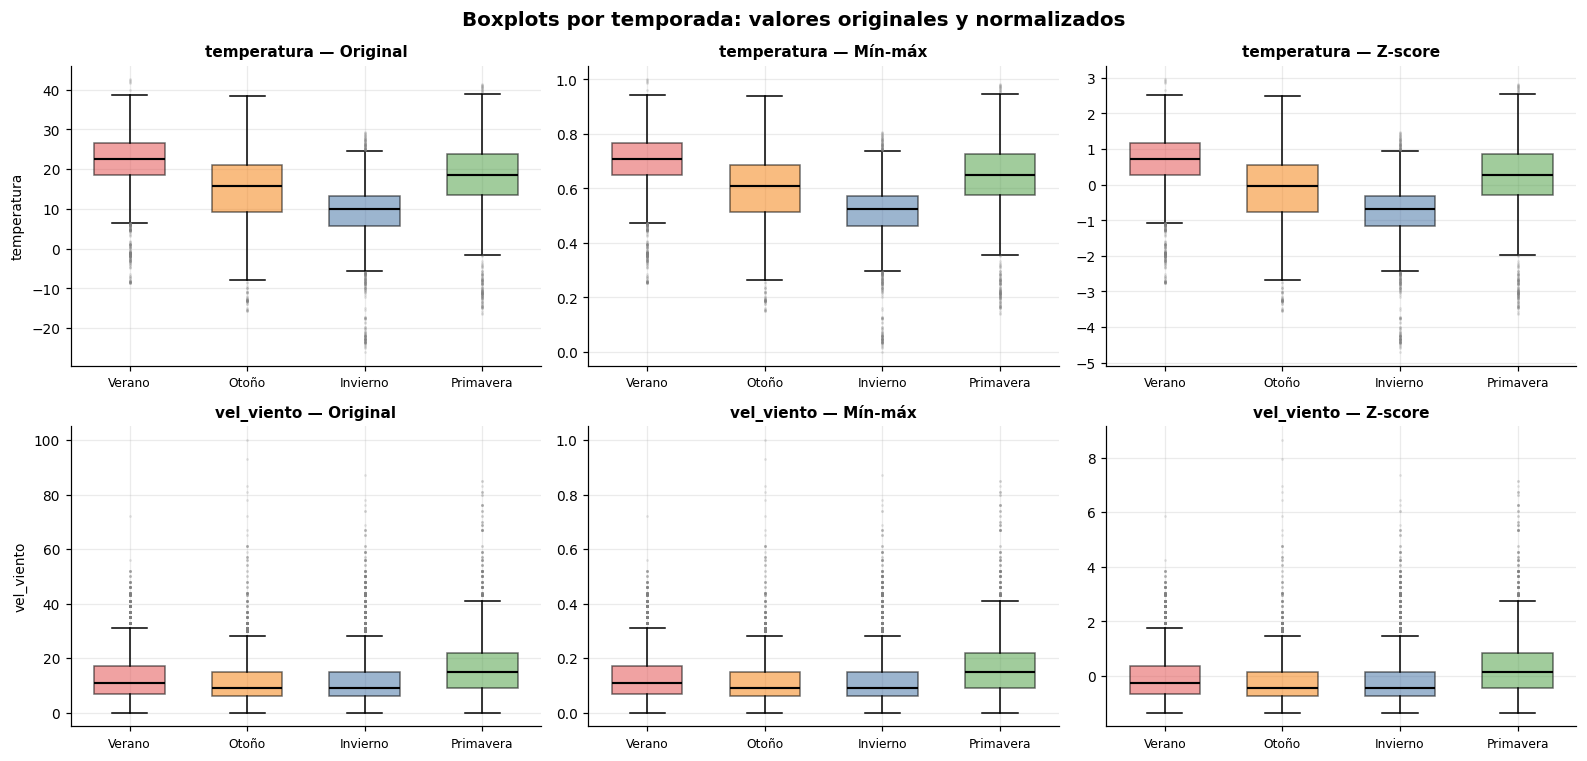

In [43]:
ORDEN_T = ["Verano", "Otoño", "Invierno", "Primavera"]
COL_T = {"Verano": "#e45756", "Otoño": "#f58518", "Invierno": "#4c78a8", "Primavera": "#54a24b"}
norm_df["temporada"] = clima["temporada"]

fig, axes = plt.subplots(2, 3, figsize=(14.5, 7))
for i, v in enumerate(VARS_NORM):
    for jx, (suf, tit) in enumerate([("", "Original"), ("_minmax", "Mín-máx"), ("_zscore", "Z-score")]):
        ax = axes[i, jx]
        datos = [norm_df.loc[norm_df["temporada"] == t, f"{v}{suf}"].dropna() for t in ORDEN_T]
        bp = ax.boxplot(datos, patch_artist=True, widths=.6,
                        flierprops=dict(marker="o", ms=1.8, alpha=.2, mfc=GRIS, mec="none"),
                        medianprops=dict(color="black", lw=1.4))
        for caja, t in zip(bp["boxes"], ORDEN_T):
            caja.set_facecolor(COL_T[t]); caja.set_alpha(.55)
        ax.set_xticklabels(ORDEN_T, fontsize=8)
        ax.set_title(f"{v} — {tit}", fontsize=10)
axes[0, 0].set_ylabel("temperatura"); axes[1, 0].set_ylabel("vel_viento")
fig.suptitle("Boxplots por temporada: valores originales y normalizados",
             fontsize=13, fontweight="bold")
fig.tight_layout(); plt.show()

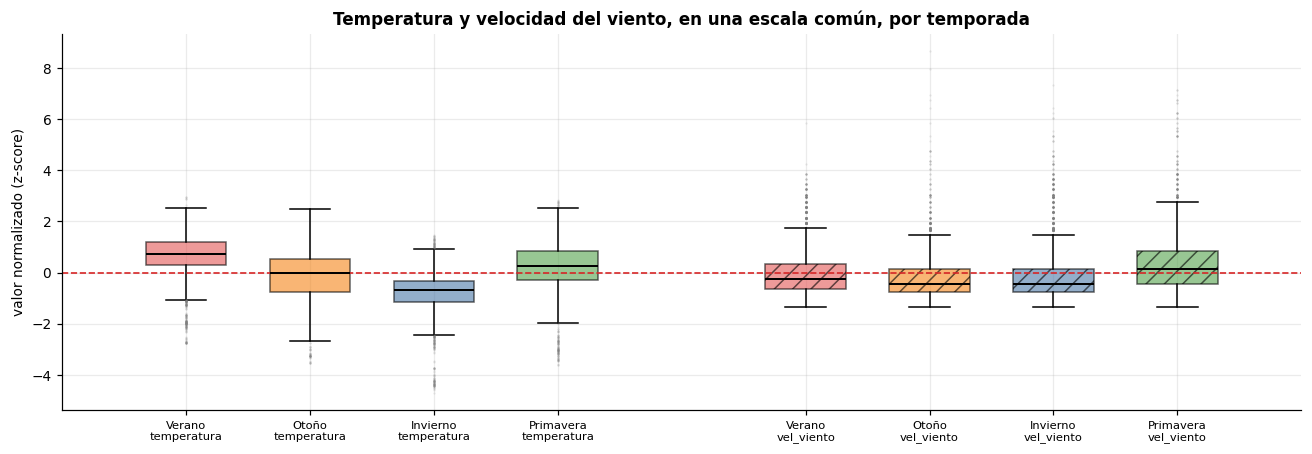

,temperatura (z),vel_viento (z)
temporada,,
Verano,0.6570,-0.0300
Otoño,-0.1230,-0.1940
Invierno,-0.7730,-0.0850
Primavera,0.2380,0.3080


In [44]:
# La comparación que SOLO es posible con variables normalizadas:
# las dos variables, las cuatro temporadas, todo en un mismo eje
fig, ax = plt.subplots(figsize=(12, 4.2))
posiciones, etiquetas = [], []
p = 0
for v, hatch in [("temperatura", ""), ("vel_viento", "//")]:
    for t in ORDEN_T:
        p += 1
        d = norm_df.loc[norm_df["temporada"] == t, f"{v}_zscore"].dropna()
        bp = ax.boxplot(d, positions=[p], widths=.65, patch_artist=True,
                        flierprops=dict(marker="o", ms=1.5, alpha=.15, mfc=GRIS, mec="none"),
                        medianprops=dict(color="black", lw=1.3))
        bp["boxes"][0].set_facecolor(COL_T[t]); bp["boxes"][0].set_alpha(.6)
        bp["boxes"][0].set_hatch(hatch)
        posiciones.append(p); etiquetas.append(f"{t}\n{v}")
    p += 1                      # separacion entre los dos bloques de variables
ax.set_xticks(posiciones); ax.set_xticklabels(etiquetas, fontsize=7.5)
ax.set_xlim(0, p)
ax.axhline(0, color=ROJO, ls="--", lw=1.1)
ax.set_ylabel("valor normalizado (z-score)")
ax.set_title("Temperatura y velocidad del viento, en una escala común, por temporada")
fig.tight_layout(); plt.show()

# Tabla de apoyo: medias por temporada en unidades de desvío
comp_t = norm_df.groupby("temporada")[[f"{v}_zscore" for v in VARS_NORM]].mean().reindex(ORDEN_T)
comp_t.columns = ["temperatura (z)", "vel_viento (z)"]
comp_t.round(3)

### Respuesta 4.e

**Los boxplots por temporada muestran, antes que nada, algo que ya se sabía: la normalización no
cambia nada de la estructura del dato.** Las tres filas de boxplots de cada variable son
gráficamente idénticas —mismas medianas relativas, mismas cajas, mismos outliers en las mismas
posiciones relativas—; lo único que cambia es la numeración del eje vertical. La estacionalidad
de la temperatura (media de 22,0 °C en verano contra 9,2 °C en invierno) y la variación mucho
más discreta del viento a lo largo del año se leen igual en cualquiera de las tres versiones.

**La ventaja de la comparación con variables normalizadas aparece en el último gráfico, y es
doble:**

1. **Permite poner en un mismo eje variables medidas en unidades distintas.** Con los datos
   originales es imposible graficar temperatura (°C) y velocidad de viento (km/h) juntas de
   manera legible: la escala del viento, que llega a 100, aplasta a la de la temperatura. Una
   vez estandarizadas, ambas viven en el mismo espacio de "desvíos respecto de su propia media"
   y el gráfico se vuelve interpretable de un vistazo.

2. **Permite comparar *magnitudes de efecto*, no magnitudes absolutas.** Esta es la ventaja de
   fondo. En unidades originales, decir que "la temperatura varía 12,8 °C entre verano e
   invierno mientras que el viento varía 5,0 km/h entre primavera y otoño" no dice cuál de las
   dos variables está más afectada por la estación, porque un grado Celsius y un kilómetro por
   hora no son comparables. En unidades z la pregunta tiene respuesta: la temperatura media pasa
   de **+0,66 σ** en verano a **−0,77 σ** en invierno —una amplitud de **1,43 desvíos**— mientras
   que la del viento va de +0,31 σ en primavera a −0,19 σ en otoño, **0,50 desvíos**. La
   estacionalidad afecta a la temperatura **casi tres veces más** que al viento en términos de la
   variabilidad propia de cada una. Esa conclusión es directamente ilegible en los datos crudos.

**Nota sobre el método a elegir para este uso.** Para comparar entre variables conviene el
**z-score**, porque su unidad (el desvío) tiene la misma interpretación en todas ellas y el cero
es un punto de referencia con significado (la media). El **mín-máx** también permite superponer
las variables, pero la posición dentro de [0, 1] depende del mínimo y el máximo observados —es
decir, de dos observaciones individuales, posiblemente outliers— y por eso no es comparable
entre variables con distinta forma de distribución. Se ve en la tabla de 4.d: en escala mín-máx la
media de la temperatura queda en 0,61 y la del viento en 0,14, una diferencia que refleja la
asimetría de cada variable y la posición de sus extremos, no alguna propiedad interesante del
clima.

<a id="ej5"></a>

---

# Parte 2 — Manejo de datos faltantes y reducción de dimensionalidad

# Ejercicio 5 — Datos faltantes

**Dataset:** `alquileres.csv` — 29.438 avisos de alquiler temporario de la Ciudad de Buenos
Aires (Inside Airbnb, relevamiento del 24 de julio de 2026), con 16 atributos.

## Identificación de las variables con datos faltantes

In [45]:
alquileres.info()
print()
falt = pd.DataFrame({
    "faltantes": alquileres.isna().sum(),
    "% faltantes": (100 * alquileres.isna().mean()).round(2),
    "tipo": alquileres.dtypes.astype(str),
})
falt[falt["faltantes"] > 0].sort_values("faltantes", ascending=False)

<class 'pandas.DataFrame'>
RangeIndex: 29438 entries, 0 to 29437
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    29438 non-null  int64  
 1   barrio                29438 non-null  str    
 2   tipo_propiedad        29438 non-null  str    
 3   tipo_habitacion       29438 non-null  str    
 4   capacidad             29438 non-null  int64  
 5   banios                25839 non-null  float64
 6   dormitorios           23624 non-null  float64
 7   camas                 26872 non-null  float64
 8   precio_ars            27520 non-null  float64
 9   minimo_noches         29432 non-null  float64
 10  cantidad_resenias     29438 non-null  int64  
 11  puntaje_resenias      25901 non-null  float64
 12  superanfitrion        29438 non-null  str    
 13  latitud               29438 non-null  float64
 14  longitud              29438 non-null  float64
 15  noches_ocupadas_anio  29438 no

,faltantes,% faltantes,tipo
dormitorios,5814,19.7500,float64
banios,3599,12.2300,float64
puntaje_resenias,3537,12.0200,float64
camas,2566,8.7200,float64
precio_ars,1918,6.5200,float64
minimo_noches,6,0.0200,float64


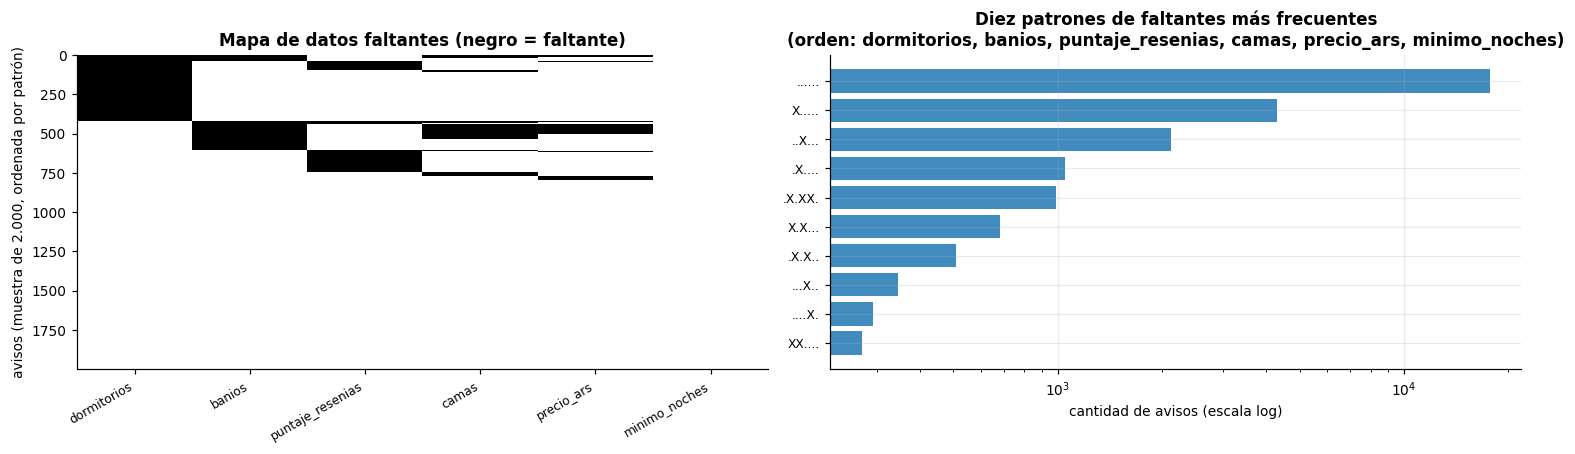

Cantidad de variables faltantes por fila:
0    17693
1     8114
2     1963
3     1299
4      342
5       27


In [46]:
CON_NA = ["dormitorios", "banios", "puntaje_resenias", "camas", "precio_ars", "minimo_noches"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))

# Mapa de faltantes (muestra ordenada, para ver el patrón)
m = alquileres[CON_NA].isna()
muestra = m.sample(2000, random_state=11).sort_values(CON_NA, ascending=False)
axes[0].imshow(muestra.values, aspect="auto", cmap="Greys", interpolation="nearest")
axes[0].set_xticks(range(len(CON_NA)), CON_NA, rotation=30, ha="right", fontsize=8)
axes[0].set_ylabel("avisos (muestra de 2.000, ordenada por patrón)")
axes[0].set_title("Mapa de datos faltantes (negro = faltante)")
axes[0].grid(False)

# Patrones conjuntos
patrones = m.apply(lambda f: "".join("X" if x else "." for x in f), axis=1).value_counts().head(10)
axes[1].barh([p for p in patrones.index][::-1], patrones.values[::-1], color=AZUL, alpha=.85)
axes[1].set_xscale("log"); axes[1].set_xlabel("cantidad de avisos (escala log)")
axes[1].set_title("Diez patrones de faltantes más frecuentes\n(orden: " + ", ".join(CON_NA) + ")")
axes[1].tick_params(axis="y", labelsize=8)
fig.tight_layout(); plt.show()

print("Cantidad de variables faltantes por fila:")
print(m.sum(axis=1).value_counts().sort_index().to_string())

## 5.a — Análisis del tipo de faltante

Se contrastan las tres categorías de Rubin: **MCAR** (*Missing Completely At Random*: la
probabilidad de faltar no depende de nada), **MAR** (*Missing At Random*: depende de variables
**observadas**) y **MNAR** (*Missing Not At Random*: depende del **propio valor no observado**).
La distinción es empíricamente verificable solo entre las dos primeras; la tercera se argumenta
por el mecanismo generador de los datos.

In [47]:
# Prueba 1: ¿la probabilidad de faltar depende de variables observadas?
print("% de faltantes según el tipo de habitación\n")
tab = (alquileres.groupby("tipo_habitacion")[CON_NA]
       .apply(lambda g: 100 * g.isna().mean()).round(1))
tab["n"] = alquileres["tipo_habitacion"].value_counts()
print(tab.to_string())

% de faltantes según el tipo de habitación

                 dormitorios  banios  puntaje_resenias   camas  precio_ars  minimo_noches      n
tipo_habitacion                                                                                 
Entire home/apt      14.4000 12.4000           10.4000  8.9000      6.6000         0.0000  26574
Hotel room            3.1000 11.6000           76.7000 11.6000      1.6000         0.0000    129
Private room         74.9000 11.0000           24.0000  6.4000      5.5000         0.0000   2590
Shared room          28.3000 11.7000           29.7000  5.5000      6.2000         0.0000    145


In [48]:
# Prueba 2: test formal (chi-cuadrado) de independencia entre "faltar" y variables observadas
print("Test chi-cuadrado: H0 = la ausencia es independiente de la variable observada\n")
filas = []
for v in CON_NA:
    for obs in ["tipo_habitacion", "barrio", "superanfitrion"]:
        ct = pd.crosstab(alquileres[v].isna(), alquileres[obs])
        chi2, p, gl, _ = stats.chi2_contingency(ct)
        filas.append({"faltante en": v, "depende de": obs, "chi2": chi2, "gl": gl, "p-valor": p,
                      "¿rechaza MCAR?": "SÍ" if p < .01 else "no"})
pd.DataFrame(filas).set_index(["faltante en", "depende de"]).round(3)

Test chi-cuadrado: H0 = la ausencia es independiente de la variable observada



chi2  gl  p-valor ¿rechaza MCAR?
faltante en      depende de                                            
dormitorios      tipo_habitacion 5,486.0530   3   0.0000             SÍ
                 barrio            257.8220  47   0.0000             SÍ
                 superanfitrion      3.6320   1   0.0570             no
banios           tipo_habitacion     4.3200   3   0.2290             no
                 barrio            151.0830  47   0.0000             SÍ
                 superanfitrion     56.9010   1   0.0000             SÍ
puntaje_resenias tipo_habitacion   966.9690   3   0.0000             SÍ
                 barrio            322.3100  47   0.0000             SÍ
                 superanfitrion  1,602.5610   1   0.0000             SÍ
camas            tipo_habitacion    21.6760   3   0.0000             SÍ
                 barrio            141.4750  47   0.0000             SÍ
                 superanfitrion    102.0450   1   0.0000             SÍ
precio_ars       tipo_habitacion    10.1030   3   0.0180             no
                 barrio            173.9100  47   0.0000             SÍ
                 superanfitrion    112.7590   1   0.0000             SÍ
minimo_noches    tipo_habitacion     0.6470   3   0.8860             no
                 barrio             18.8010  47   1.0000             no
                 superanfitrion      6.1570   1   0.0130             no

In [49]:
# Prueba 3: ¿difieren las variables numéricas entre el grupo que falta y el que no?
print("Comparación de medias entre avisos con y sin dato (test t de Welch)\n")
filas = []
for v in ["banios", "camas", "precio_ars", "dormitorios"]:
    m = alquileres[v].isna()
    for obs in ["cantidad_resenias", "noches_ocupadas_anio", "capacidad"]:
        a_, b_ = alquileres.loc[m, obs].dropna(), alquileres.loc[~m, obs].dropna()
        t, p = stats.ttest_ind(a_, b_, equal_var=False)
        filas.append({"faltante en": v, "variable observada": obs,
                      "media (falta)": a_.mean(), "media (no falta)": b_.mean(),
                      "t": t, "p-valor": p})
pd.DataFrame(filas).set_index(["faltante en", "variable observada"]).round(3)

Comparación de medias entre avisos con y sin dato (test t de Welch)



media (falta)  media (no falta)        t  p-valor
faltante en variable observada                                                     
banios      cantidad_resenias           32.6520           41.6280  -9.7230   0.0000
            noches_ocupadas_anio        59.7570           77.2830 -12.5280   0.0000
            capacidad                    2.8880            2.9340  -1.7210   0.0850
camas       cantidad_resenias           28.5930           41.6710 -14.0400   0.0000
            noches_ocupadas_anio        55.5060           77.0150 -13.2620   0.0000
            capacidad                    2.8290            2.9380  -3.6490   0.0000
precio_ars  cantidad_resenias           29.1230           41.3260 -11.1740   0.0000
            noches_ocupadas_anio        50.7890           76.8380 -14.7330   0.0000
            capacidad                    2.7870            2.9390  -5.0910   0.0000
dormitorios cantidad_resenias           42.8400           39.9620   2.9180   0.0040
            noches_ocupadas_anio        74.0670           75.4050  -1.0930   0.2740
            capacidad                    2.1580            3.1190 -59.9310   0.0000

In [50]:
# Prueba 4: el caso de puntaje_resenias es determinístico
sin_res = alquileres["cantidad_resenias"] == 0
print(f"Avisos sin reseñas                              : {sin_res.sum():,}")
print(f"Avisos sin puntaje                              : {alquileres['puntaje_resenias'].isna().sum():,}")
print(f"Avisos sin reseñas Y sin puntaje                : {(sin_res & alquileres['puntaje_resenias'].isna()).sum():,}")
print(f"Avisos CON reseñas y SIN puntaje                : {(~sin_res & alquileres['puntaje_resenias'].isna()).sum():,}")
print("\n=> La ausencia de puntaje queda COMPLETAMENTE explicada por cantidad_resenias = 0.")

# Correlación entre los indicadores de ausencia (patrón de bloque)
print("\nCorrelación entre los indicadores de ausencia (phi):")
print(alquileres[CON_NA].isna().astype(int).corr().round(2).to_string())

falt_barrio = (100 * alquileres.groupby("barrio")["precio_ars"].apply(lambda s: s.isna().mean()))
print("\n% de precios faltantes — cinco barrios con más y con menos ausencias:")
print(pd.concat([falt_barrio.nlargest(5), falt_barrio.nsmallest(5)]).round(1).to_string())
print("\nBarrios de alta demanda turística:")
print(falt_barrio[["Palermo", "Recoleta", "San Nicolas", "Retiro"]].round(1).to_string())

Avisos sin reseñas                              : 3,537
Avisos sin puntaje                              : 3,537
Avisos sin reseñas Y sin puntaje                : 3,537
Avisos CON reseñas y SIN puntaje                : 0

=> La ausencia de puntaje queda COMPLETAMENTE explicada por cantidad_resenias = 0.

Correlación entre los indicadores de ausencia (phi):
                  dormitorios  banios  puntaje_resenias   camas  precio_ars  minimo_noches
dormitorios            1.0000 -0.0200            0.0300 -0.0400     -0.0200        -0.0000
banios                -0.0200  1.0000            0.0200  0.6400      0.4800         0.0000
puntaje_resenias       0.0300  0.0200            1.0000  0.0300      0.0600        -0.0100
camas                 -0.0400  0.6400            0.0300  1.0000      0.5800        -0.0000
precio_ars            -0.0200  0.4800            0.0600  0.5800      1.0000        -0.0000
minimo_noches         -0.0000  0.0000           -0.0100 -0.0000     -0.0000         1.0000



% de precios faltantes — cinco barrios con más y con menos ausencias:
barrio
Velez Sarsfield     36.8000
Liniers             22.2000
Villa Santa Rita    20.8000
Villa Gral. Mitre   19.4000
Coghlan             16.3000
Monte Castro         0.0000
Nueva Pompeya        0.0000
Versalles            0.0000
Villa Lugano         0.0000
Villa Real           0.0000

Barrios de alta demanda turística:
barrio
Palermo       6.2000
Recoleta      7.1000
San Nicolas   4.6000
Retiro        7.6000


### Respuesta 5.a

**Variables con datos faltantes:** `dormitorios` (5.814 casos, 19,7 %), `puntaje_resenias`
(3.537 · 12,0 %), `banios` (3.599 · 12,2 %), `camas` (2.566 · 8,7 %), `precio_ars` (1.918 ·
6,5 %) y `minimo_noches` (6 casos, 0,02 %). Las diez variables restantes están completas. Solo
el 60,1 % de los avisos (17.693) no tiene ningún faltante, y 27 no informan ninguna de las seis.

**El mecanismo no es el mismo para todas, y conviene analizarlas por separado.**

**1. `puntaje_resenias` → MAR determinístico (faltante estructural).** El resultado es
categórico: los 3.537 avisos sin puntaje son **exactamente** los 3.537 avisos con
`cantidad_resenias = 0`, y no hay ni un solo caso con reseñas y sin puntaje. La ausencia no es
un dato perdido sino una **imposibilidad lógica**: no existe puntaje promedio si no hubo
calificaciones. Formalmente es MAR —depende por completo de una variable observada— pero la
implicancia práctica es distinta a la de un MAR ordinario: **imputar aquí sería un error
conceptual**. Rellenar con la media (4,78) inventaría una reputación para propiedades que nunca
fueron calificadas, y sesgaría cualquier análisis que use el puntaje. Lo correcto es crear una
categoría explícita ("sin reseñas") o una variable indicadora, y tratar a ese grupo aparte.

**2. `dormitorios` → MAR fuerte.** El 74,9 % de las habitaciones privadas (*Private room*) no
informa cantidad de dormitorios, contra el 14,4 % de las propiedades enteras y el 3,1 % de las
habitaciones de hotel. El chi-cuadrado contra `tipo_habitacion` es enorme (χ² = 5.486 con 3 grados de libertad)
y la explicación es funcional: cuando se alquila una sola habitación dentro de una vivienda, el
campo "dormitorios" del formulario carece de sentido y el anfitrión lo deja vacío. La ausencia
depende de una variable **observada**, de modo que el mecanismo es MAR y la imputación
condicionada al tipo de habitación es válida y necesaria.

**3. `banios`, `camas` y `precio_ars` → MAR con sospecha de MNAR.** Estas tres comparten un
patrón de bloque: sus indicadores de ausencia están fuertemente correlacionados entre sí (φ =
0,64 entre `banios` y `camas`; φ = 0,58 entre `camas` y `precio_ars`), lo que indica que faltan
**juntas**, en avisos incompletos. El test t confirma que ese grupo es distinto del resto:
tienen menos reseñas (29 contra 41 en promedio, p < 10⁻¹⁵) y bastante menos ocupación anual (51
contra 77 noches). Es decir, **los datos faltan sistemáticamente en los avisos menos activos** —
publicaciones abandonadas, en pausa o recién creadas—, y la dependencia es de variables
observadas: MAR.

Ahora bien, para `precio_ars` hay un argumento adicional que empuja hacia **MNAR**. El precio
desaparece del listado público cuando el anfitrión desactiva el calendario o retira la
propiedad, y eso se relaciona con la **capacidad de la propiedad de colocarse en el mercado a su
precio pretendido**. Si los avisos sobrevaluados son los que más frecuentemente quedan inactivos,
entonces la probabilidad de que falte el precio depende del propio precio no observado, que es
la definición de MNAR. El dato disponible es consistente con esa hipótesis aunque no la prueba:
la ausencia está muy concentrada geográficamente (36,8 % en Vélez Sarsfield y 22,2 % en Liniers,
barrios de baja demanda turística, contra 6,2 % en Palermo y 7,1 % en Recoleta). Como el
mecanismo MNAR **no es verificable con los datos a mano**, corresponde señalar el riesgo:
cualquier imputación de `precio_ars` supone MAR, y si el mecanismo real fuera MNAR los precios
imputados estarían sesgados sistemáticamente.

**Conclusión operativa.** El supuesto MCAR **se rechaza para las cinco variables con faltantes
relevantes**: en cada una hay al menos un test con p < 0,001. Conviene notar que ningún test
aislado alcanza para rechazarlo —la ausencia de `banios`, por ejemplo, **no** depende del tipo de
habitación (χ² = 4,3; p = 0,23) pero sí del barrio y de la condición de superanfitrión (ambos con
p < 0,001)—, de modo que el diagnóstico exige contrastar contra varias variables observadas. La
única excepción es `minimo_noches`: con 6 casos faltantes ningún test resulta significativo y no
hay evidencia para rechazar MCAR, lo que en la práctica vuelve irrelevante el método que se
elija para imputarla. Por lo tanto **el descarte de casos
incompletos —*listwise deletion*— no es admisible aquí**: eliminaría el 40 % del dataset y, peor
aún, lo haría de forma selectiva, borrando desproporcionadamente las habitaciones privadas y los
barrios periféricos, y produciendo una muestra sesgada hacia los departamentos enteros de los
barrios turísticos. Los métodos de imputación de los puntos siguientes, que aprovechan la
información observada, son la alternativa correcta.

## 5.b — Sustitución por una medida de tendencia central

Se aplica el criterio que corresponde al tipo de cada variable: **mediana** para las numéricas
asimétricas (`precio_ars`), **moda** para las numéricas discretas de pocos valores (`banios`,
`dormitorios`, `camas`, `minimo_noches`) y se deja `puntaje_resenias` fuera, por lo argumentado
en 5.a.

In [51]:
NUM_IMP = ["banios", "dormitorios", "camas", "precio_ars", "minimo_noches"]
base = alquileres.copy()

imp_central = base.copy()
criterios = {}
for v in NUM_IMP:
    s = base[v]
    if v == "precio_ars":
        val, crit = s.median(), "mediana"
    else:
        val, crit = s.mode().iloc[0], "moda"
    imp_central[v] = s.fillna(val)
    criterios[v] = (crit, val)
    print(f"{v:<16} {crit:<8} = {val:>12,.2f}   ({s.isna().sum():,} valores imputados)")

# puntaje_resenias: se trata como categoría, no se imputa con la media
imp_central["sin_resenias"] = base["puntaje_resenias"].isna().astype(int)
print(f"\npuntaje_resenias: NO se imputa; se crea la variable indicadora 'sin_resenias'.")

banios           moda     =         1.00   (3,599 valores imputados)
dormitorios      moda     =         1.00   (5,814 valores imputados)
camas            moda     =         1.00   (2,566 valores imputados)
precio_ars       mediana  =   103,206.00   (1,918 valores imputados)
minimo_noches    moda     =         1.00   (6 valores imputados)

puntaje_resenias: NO se imputa; se crea la variable indicadora 'sin_resenias'.


In [52]:
cmp_b = pd.DataFrame({
    "original": base[NUM_IMP].describe().T["std"],
    "tras imputar": imp_central[NUM_IMP].describe().T["std"],
})
cmp_b["% cambio en el desvío"] = (100 * (cmp_b["tras imputar"] / cmp_b["original"] - 1)).round(1)
cmp_b["media original"] = base[NUM_IMP].mean()
cmp_b["media imputada"] = imp_central[NUM_IMP].mean()
cmp_b.round(3)

,original,tras imputar,% cambio en el desvío,media original,media imputada
banios,0.6750,0.6370,-5.6000,1.2370,1.2080
dormitorios,0.9050,0.8230,-9.1000,1.3560,1.2860
camas,1.5390,1.4940,-2.9000,1.9350,1.8540
precio_ars,"115,303.0220","111,699.9160",-3.1000,"131,371.6220","129,536.5230"
minimo_noches,18.9630,18.9610,-0.0000,5.0310,5.0300


## 5.c — Imputación por *hot deck*

El *hot deck* reemplaza cada valor faltante por el de un **donante real** del mismo conjunto de
datos, elegido dentro de una **clase de imputación** (un grupo de registros similares). A
diferencia de la media, el valor imputado es siempre un valor **que existe** en la población.

Se implementa la variante **secuencial** clásica: los registros se ordenan dentro de cada clase
y cada faltante toma el último valor observado del "mazo" (*deck*).

In [53]:
def hot_deck_secuencial(df, objetivo, clases, orden=None, random_state=0):
    '''
    Hot deck secuencial: dentro de cada clase de imputación, cada faltante recibe el
    último valor observado del mazo (y, si es el primero, el siguiente observado).
    '''
    d = df.copy()
    if orden:
        d = d.sort_values(orden, kind="mergesort")
    else:
        d = d.sample(frac=1, random_state=random_state)     # baraja el mazo
    g = d.groupby(clases, observed=True)[objetivo]
    imputado = g.ffill()
    imputado = imputado.fillna(d.groupby(clases, observed=True)[objetivo].bfill())
    imputado = imputado.fillna(df[objetivo].median())        # red de seguridad
    return imputado.reindex(df.index)

CLASES = ["barrio", "tipo_habitacion", "capacidad"]
# El mazo se ordena por una variable AUXILIAR (la actividad del aviso), nunca por la variable
# que se está imputando: ordenar por el objetivo dejaría todos los faltantes al final del mazo
# y el ffill los llenaría sistemáticamente con los valores más altos de la clase.
imp_hotdeck = base.copy()
for v in NUM_IMP:
    imp_hotdeck[v] = hot_deck_secuencial(base, v, CLASES, orden=CLASES + ["noches_ocupadas_anio"])
    print(f"{v:<16} imputados: {base[v].isna().sum():>5,}   "
          f"faltantes restantes: {imp_hotdeck[v].isna().sum()}")

print(f"\nClases de imputación utilizadas: {CLASES}")
print(f"Cantidad de clases distintas: "
      f"{base.groupby(CLASES, observed=True).ngroups:,}")

banios           imputados: 3,599   faltantes restantes: 0
dormitorios      imputados: 5,814   faltantes restantes: 0
camas            imputados: 2,566   faltantes restantes: 0
precio_ars       imputados: 1,918   faltantes restantes: 0
minimo_noches    imputados:     6   faltantes restantes: 0

Clases de imputación utilizadas: ['barrio', 'tipo_habitacion', 'capacidad']


Cantidad de clases distintas: 578


## 5.d — Función `hot_deck` propia vs. `KNNImputer` de scikit-learn

### Criterio de similitud elegido

Para `alquileres.csv` dos avisos son similares si ofrecen **el mismo producto en el mismo
mercado**. Eso se traduce en:

- **Bloqueo exacto** (clases de imputación) por `tipo_habitacion` y `barrio`: un donante para
  una habitación privada en Palermo tiene que ser otra habitación privada en Palermo. Son las
  dos variables que en 5.a mostraron la mayor asociación con la ausencia, y bloquear por ellas
  es lo que vuelve plausible el supuesto MAR.
- **Distancia euclídea sobre variables estandarizadas** dentro de cada bloque, usando
  `capacidad` (el determinante principal del tamaño de la propiedad) y `latitud`/`longitud` (la
  micro-ubicación dentro del barrio, que en esta ciudad cambia mucho el tipo de edificación).
  Las tres están **completas**, condición indispensable para que sirvan como métrica.
- **Selección aleatoria entre los k = 5 vecinos más cercanos**, en lugar del vecino único. El
  sorteo es deliberado: introduce la variabilidad natural del dato y evita el achatamiento de la
  varianza que produce cualquier imputación determinística.

In [54]:
from scipy.spatial import cKDTree

def hot_deck(df, objetivo, vars_numericas, vars_bloqueo, k=5, random_state=42, verbose=True):
    '''
    Hot deck por vecinos más cercanos dentro de clases de imputación.

    df              : DataFrame con los datos
    objetivo        : nombre de la columna a imputar
    vars_numericas  : variables (completas) que definen la distancia entre registros
    vars_bloqueo    : variables categóricas que definen las clases de imputación
    k               : cantidad de donantes candidatos; se sortea uno entre ellos
    random_state    : semilla para reproducibilidad

    Devuelve la serie imputada. Si una clase no tiene donantes suficientes, cae en cascada
    a la mediana de la clase y, en última instancia, a la mediana global.
    '''
    rng = np.random.default_rng(random_state)
    resultado = df[objetivo].copy()

    # Estandarización de las variables de distancia (para que pesen lo mismo)
    Z = df[vars_numericas].astype(float)
    Z = (Z - Z.mean()) / Z.std()

    clases = df[vars_bloqueo].astype(str).agg("|".join, axis=1)
    n_donados = n_fallback = 0

    hay_dato = df[objetivo].notna()
    for _, idx in df.groupby(clases, observed=True).groups.items():
        idx = pd.Index(idx)
        sub_obs = idx[hay_dato.loc[idx].values]     # donantes potenciales de la clase
        sub_fal = idx[~hay_dato.loc[idx].values]    # receptores
        if len(sub_fal) == 0:
            continue
        if len(sub_obs) == 0:                       # clase sin ningún donante
            resultado.loc[sub_fal] = df[objetivo].median()
            n_fallback += len(sub_fal)
            continue

        arbol = cKDTree(Z.loc[sub_obs].values)
        kk = min(k, len(sub_obs))
        _, pos = arbol.query(Z.loc[sub_fal].values, k=kk)
        pos = np.asarray(pos).reshape(len(sub_fal), kk)
        elegidos = pos[np.arange(len(sub_fal)), rng.integers(0, kk, len(sub_fal))]
        resultado.loc[sub_fal] = df.loc[sub_obs[elegidos], objetivo].values
        n_donados += len(sub_fal)

    if verbose:
        print(f"{objetivo:<16} donantes reales: {n_donados:>6,}   "
              f"sin clase válida (mediana global): {n_fallback:>5,}")
    return resultado


VARS_DIST   = ["capacidad", "latitud", "longitud"]
VARS_BLOQUE = ["tipo_habitacion", "barrio"]

imp_hd_propio = base.copy()
for v in NUM_IMP:
    imp_hd_propio[v] = hot_deck(base, v, VARS_DIST, VARS_BLOQUE, k=5, random_state=42)

banios           donantes reales:  3,598   sin clase válida (mediana global):     1


dormitorios      donantes reales:  5,778   sin clase válida (mediana global):    36


camas            donantes reales:  2,565   sin clase válida (mediana global):     1


precio_ars       donantes reales:  1,916   sin clase válida (mediana global):     2


minimo_noches    donantes reales:      6   sin clase válida (mediana global):     0


In [55]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
import time

COLS_KNN = ["capacidad", "banios", "dormitorios", "camas", "precio_ars", "minimo_noches",
            "cantidad_resenias", "latitud", "longitud", "noches_ocupadas_anio"]

X = base[COLS_KNN].copy()
# se agrega el tipo de habitación codificado, para que la distancia lo tenga en cuenta
X = pd.concat([X, pd.get_dummies(base["tipo_habitacion"], prefix="th").astype(float)], axis=1)

escalador = StandardScaler()
Xs = escalador.fit_transform(X)

t0 = time.time()
Xi = KNNImputer(n_neighbors=5, weights="distance").fit_transform(Xs)
print(f"KNNImputer sobre {X.shape[0]:,} x {X.shape[1]} — {time.time()-t0:.1f} s")

X_knn = pd.DataFrame(escalador.inverse_transform(Xi), columns=X.columns, index=X.index)
imp_knn = base.copy()
for v in NUM_IMP:
    imp_knn[v] = X_knn[v]
print("\nFaltantes restantes:", imp_knn[NUM_IMP].isna().sum().sum())

KNNImputer sobre 29,438 x 14 — 26.2 s

Faltantes restantes: 0


In [56]:
# Comparación de los dos métodos sobre los valores efectivamente imputados
def resumen_metodo(df_imp, nombre):
    filas = {}
    for v in NUM_IMP:
        m = base[v].isna()
        if m.sum() == 0: continue
        imp = df_imp.loc[m, v]
        filas[v] = {"media imputada": imp.mean(), "desvío imputado": imp.std(),
                    "valores distintos": imp.nunique(),
                    "% enteros": 100 * (imp == imp.round()).mean()}
    return pd.concat({nombre: pd.DataFrame(filas).T}, names=["método"])

cmp_d = pd.concat([
    resumen_metodo(imp_central,   "media/moda"),
    resumen_metodo(imp_hotdeck,   "hot deck secuencial"),
    resumen_metodo(imp_hd_propio, "hot_deck propio (k=5)"),
    resumen_metodo(imp_knn,       "KNNImputer sklearn"),
]).swaplevel().sort_index()
cmp_d.round(3)

media imputada  desvío imputado  valores distintos  % enteros
              método                                                                              
banios        KNNImputer sklearn             1.2180           0.4950         1,882.0000    47.2350
              hot deck secuencial            1.2400           0.6330            14.0000    87.4690
              hot_deck propio (k=5)          1.2270           0.6740            15.0000    87.9130
              media/moda                     1.0000           0.0000             1.0000   100.0000
camas         KNNImputer sklearn             1.8490           1.2320         1,924.0000    15.4330
              hot deck secuencial            1.8470           1.3180            13.0000   100.0000
              hot_deck propio (k=5)          1.8240           1.3390            13.0000   100.0000
              media/moda                     1.0000           0.0000             1.0000   100.0000
dormitorios   KNNImputer sklearn             1.2980           0.8150         2,055.0000    62.6420
              hot deck secuencial            1.4980           1.8860            19.0000   100.0000
              hot_deck propio (k=5)          1.4860           2.0470            19.0000   100.0000
              media/moda                     1.0000           0.0000             1.0000   100.0000
minimo_noches KNNImputer sklearn             1.9560           0.6170             6.0000     0.0000
              hot deck secuencial            2.3330           1.5060             4.0000   100.0000
              hot_deck propio (k=5)          6.1670           9.3040             4.0000   100.0000
              media/moda                     1.0000           0.0000             1.0000   100.0000
precio_ars    KNNImputer sklearn       122,966.5350      70,410.7820         1,917.0000     0.2610
              hot deck secuencial      130,018.3260     107,604.1680         1,463.0000   100.0000
              hot_deck propio (k=5)    127,138.5500     110,442.2060         1,506.0000   100.0000
              media/moda               103,206.0000           0.0000             1.0000   100.0000

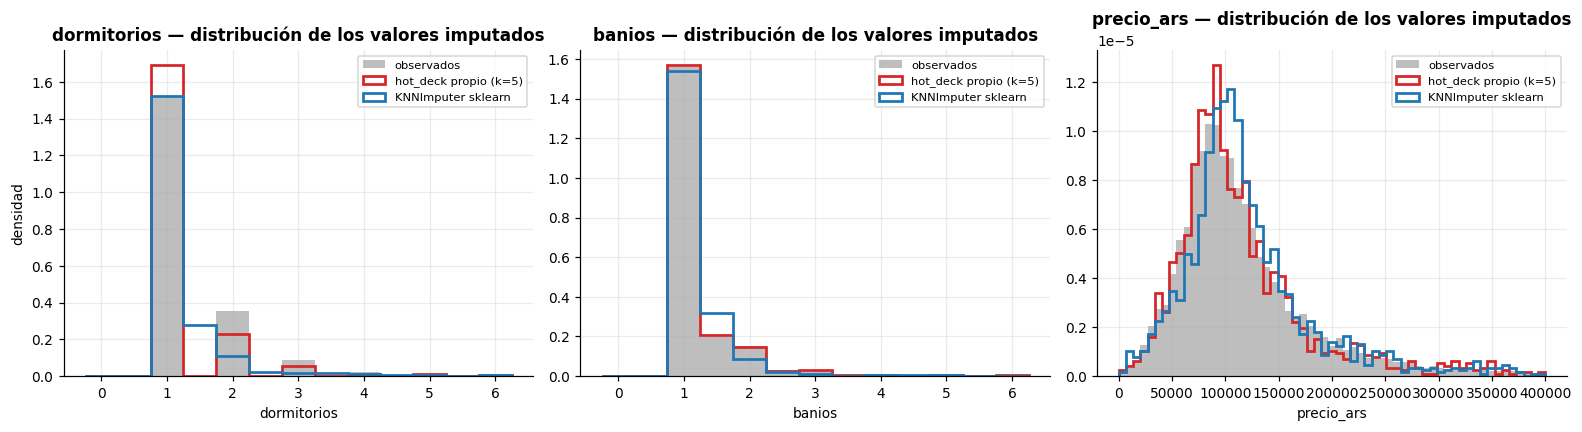

In [57]:
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4))
METODOS = [("hot_deck propio (k=5)", imp_hd_propio, ROJO), ("KNNImputer sklearn", imp_knn, AZUL)]

for ax, v in zip(axes, ["dormitorios", "banios", "precio_ars"]):
    m = base[v].isna()
    obs = base.loc[~m, v]
    if v == "precio_ars":
        bins = np.linspace(0, 400_000, 60)
        ax.hist(obs, bins=bins, density=True, color=GRIS, alpha=.5, label="observados")
        for nombre, dfi, col in METODOS:
            ax.hist(dfi.loc[m, v], bins=bins, density=True, histtype="step", lw=1.8,
                    color=col, label=nombre)
    else:
        bins = np.arange(-.25, 6.5, .5)
        ax.hist(obs, bins=bins, density=True, color=GRIS, alpha=.5, label="observados")
        for nombre, dfi, col in METODOS:
            ax.hist(dfi.loc[m, v], bins=bins, density=True, histtype="step", lw=1.8,
                    color=col, label=nombre)
    ax.set_title(f"{v} — distribución de los valores imputados")
    ax.set_xlabel(v); ax.legend(fontsize=7.5)
axes[0].set_ylabel("densidad")
fig.tight_layout(); plt.show()

### Respuesta 5.d — Comparación

**La diferencia de fondo entre los dos métodos es que uno *dona* y el otro *promedia*.**

| | `hot_deck` propio | `KNNImputer` |
|---|---|---|
| valor imputado | un valor **real** de un donante | **promedio ponderado** de los 5 vecinos |
| respeta el dominio | **sí**: 100 % de enteros en `dormitorios` | **no**: solo el 62,6 % son enteros |
| valores distintos generados en `dormitorios` | 19 | **2.055** |
| similitud | bloqueo exacto + distancia euclídea | distancia euclídea sobre todas las variables |
| variables categóricas | bloqueo exacto por barrio y tipo | solo *dummies* de tipo (el barrio no entra) |
| componente aleatoria | sí (sorteo entre k donantes) | no (determinística) |
| desvío de los `precio_ars` imputados | 110.442 | 70.411 (observados: 115.303) |

**1. Preservación del dominio.** El resultado más visible es que `KNNImputer` devuelve valores
**no enteros** para variables que son conteos: solo el 62,6 % de sus imputaciones de
`dormitorios` son números enteros, y genera **2.055 valores distintos** para una variable que en
los datos observados toma apenas una veintena de niveles. Eso obliga a redondear después con un
criterio ad hoc. El hot deck, por construcción, solo puede devolver valores que ya estaban en
los datos: el 100 % de sus imputaciones de `dormitorios` son enteros y produce 19 niveles. (En
`banios` el hot deck da 87,9 % de enteros, y está bien: el dataset contiene medios baños —1,5;
2,5— que son valores legítimos.) Para variables discretas esta es una ventaja decisiva.

**2. Preservación de la varianza.** Los histogramas muestran el efecto con claridad. La
distribución de los valores imputados por hot deck **replica la forma** de la distribución
observada —incluida su asimetría y su cola—, porque cada valor proviene de un caso real. La de
`KNNImputer` está **visiblemente más concentrada**: al promediar cinco vecinos, la varianza del
promedio es menor que la de los datos individuales, y el resultado se apiña alrededor del centro.
En `precio_ars` el contraste es nítido: el desvío de los valores imputados por hot deck es
110.442 —muy cerca de los 115.303 de los datos observados— mientras que el de KNN cae a 70.411,
un 39 % menos. Este achatamiento es el problema conocido de toda imputación determinística: infla
artificialmente la precisión de cualquier estimación posterior y subestima los errores estándar.

**3. Uso de la información categórica.** El hot deck propio bloquea por `barrio`, una variable
de 48 categorías que es el principal determinante del precio en esta ciudad. `KNNImputer` solo
acepta entradas numéricas: incorporarla exigiría 48 columnas *dummy* que además distorsionan la
distancia euclídea (dos avisos de barrios distintos quedan a distancia √2 sin importar cuán
lejos estén realmente). Por eso el hot deck usó `latitud`/`longitud` para la proximidad y el
barrio para el bloqueo, que es la representación correcta del problema.

**4. Dónde gana `KNNImputer`.** Es **multivariado**: imputa todas las columnas simultáneamente y
aprovecha las correlaciones entre ellas (un aviso con 3 baños probablemente tenga varios
dormitorios), mientras que el hot deck propio imputa una variable por vez usando solo las
variables completas. Además está probado, optimizado y no requiere definir clases de imputación
—resuelve el problema de las clases vacías automáticamente, mientras que el hot deck necesitó
una cascada de respaldo para 40 casos sin donantes en su clase (36 de ellos en `dormitorios`).

Y hay un costo del bloqueo estricto que conviene reportar con honestidad: en `dormitorios`, el
hot deck **infla** la dispersión (desvío de 2,05 en los valores imputados contra 0,91 en los
observados) y **atenúa** la correlación con `capacidad` (de 0,590 a 0,342), mientras que KNN la
mantiene en 0,502. La causa es el mecanismo MAR de 5.a: como el 74,9 % de las habitaciones
privadas no informa dormitorios, dentro de esa clase quedan muy pocos donantes y no son
representativos. Cuando la tasa de faltantes dentro de una clase es muy alta, el hot deck pierde
buena parte de su ventaja.

**Cuál elegir.** Para este dataset, el **hot deck con sorteo entre los k vecinos** es preferible
para las variables discretas (`dormitorios`, `banios`, `camas`), porque respeta el dominio y la
varianza. Para `precio_ars` la elección es más pareja y depende del uso: si el objetivo es
estimar medias por barrio, KNN es aceptable; si es alimentar un modelo o estimar dispersión, el
hot deck o —mejor aún— una imputación múltiple son la opción correcta.

## 5.e — Imputación por regresión

Se modela la variable incompleta en función de las variables observadas, y se usa la predicción
del modelo como valor imputado. Se ilustra con `precio_ars`, que es la variable con mayor
contenido económico del dataset.

Se estiman **dos variantes**: la regresión determinística clásica y la **regresión estocástica**,
que agrega a cada predicción un residuo aleatorio extraído del error del modelo — precisamente
para corregir el achatamiento de la varianza que se observó en 5.d.

In [58]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

def imputar_por_regresion(df, objetivo, predictores_num, predictores_cat,
                          log=False, estocastica=False, random_state=7):
    '''
    Imputación por regresión lineal múltiple.
    log         : ajusta el modelo sobre log(objetivo) (para variables asimétricas positivas)
    estocastica : suma a cada predicción un residuo sorteado de los residuos del ajuste
    '''
    rng = np.random.default_rng(random_state)
    X = pd.get_dummies(df[predictores_num + predictores_cat],
                       columns=predictores_cat, drop_first=True).astype(float)
    X = X.fillna(X.median())                         # predictores completados con su mediana
    y = df[objetivo]
    obs, fal = y.notna(), y.isna()

    y_aj = np.log(y[obs]) if log else y[obs]
    modelo = LinearRegression().fit(X[obs], y_aj)

    # calidad del ajuste, validada fuera de muestra
    Xtr, Xte, ytr, yte = train_test_split(X[obs], y_aj, test_size=.25, random_state=random_state)
    r2 = r2_score(yte, LinearRegression().fit(Xtr, ytr).predict(Xte))

    pred = modelo.predict(X[fal])
    if estocastica:
        residuos = y_aj - modelo.predict(X[obs])
        pred = pred + rng.choice(residuos.values, size=len(pred), replace=True)
    if log:
        pred = np.exp(pred)

    salida = y.copy()
    salida[fal] = np.clip(pred, y[obs].min(), y[obs].max())
    return salida, r2, modelo, X.columns


PRED_NUM = ["capacidad", "banios", "dormitorios", "camas", "minimo_noches",
            "cantidad_resenias", "noches_ocupadas_anio", "latitud", "longitud"]
PRED_CAT = ["tipo_habitacion", "barrio", "superanfitrion"]

precio_reg,  r2_reg,  mod, cols = imputar_por_regresion(base, "precio_ars", PRED_NUM, PRED_CAT, log=True)
precio_regE, r2_regE, _,  _     = imputar_por_regresion(base, "precio_ars", PRED_NUM, PRED_CAT,
                                                        log=True, estocastica=True)
print(f"Modelo log(precio) ~ {len(cols)} predictores")
print(f"R² fuera de muestra: {r2_reg:.3f}")
# Los coeficientes crudos no son comparables entre sí (cada predictor tiene su propia escala),
# por eso se los expresa como efecto de un desvío estándar del predictor sobre el log-precio.
Xc = pd.get_dummies(base[PRED_NUM + PRED_CAT], columns=PRED_CAT, drop_first=True).astype(float)
Xc = Xc.fillna(Xc.median())
efecto = pd.Series(mod.coef_ * Xc.std().values, index=cols)
print(f"\nPredictores más influyentes (cambio en log-precio por 1 desvío del predictor):")
print(efecto.sort_values(key=abs, ascending=False).head(10).round(3).to_string())

Modelo log(precio) ~ 60 predictores
R² fuera de muestra: 0.465

Predictores más influyentes (cambio en log-precio por 1 desvío del predictor):
capacidad                       0.2530
minimo_noches                  -0.2180
tipo_habitacion_Private room   -0.1340
latitud                         0.1070
noches_ocupadas_anio           -0.0780
tipo_habitacion_Shared room    -0.0750
longitud                        0.0740
barrio_Puerto Madero            0.0690
superanfitrion_si               0.0510
tipo_habitacion_Hotel room      0.0430


In [59]:
imp_regresion = base.copy()
imp_regresion["precio_ars"] = precio_reg
imp_regresion_E = base.copy()
imp_regresion_E["precio_ars"] = precio_regE

# El resto de las variables, por regresión, para completar el dataset
for v in ["banios", "dormitorios", "camas"]:
    pred_v = [p for p in PRED_NUM if p != v]
    s, r2v, _, _ = imputar_por_regresion(base, v, pred_v, PRED_CAT)
    imp_regresion[v] = s.round()                      # se redondea: son conteos
    imp_regresion_E[v] = s.round()
    print(f"{v:<14} R² fuera de muestra = {r2v:.3f}")
imp_regresion["minimo_noches"] = base["minimo_noches"].fillna(base["minimo_noches"].median())
imp_regresion_E["minimo_noches"] = imp_regresion["minimo_noches"]

banios         R² fuera de muestra = 0.339


dormitorios    R² fuera de muestra = 0.520


camas          R² fuera de muestra = 0.666


## 5.f — Comparación general de los métodos de imputación

In [60]:
METODOS_TODOS = [
    ("Sin imputar (solo observados)", base,            GRIS),
    ("Mediana / moda",                imp_central,     VERDE),
    ("Hot deck secuencial",           imp_hotdeck,     "#9467bd"),
    ("Hot deck propio (k=5)",         imp_hd_propio,   ROJO),
    ("KNNImputer (sklearn)",          imp_knn,         AZUL),
    ("Regresión determinística",      imp_regresion,   NARANJA),
    ("Regresión estocástica",         imp_regresion_E, "#17becf"),
]

filas = []
for nombre, dfi, _ in METODOS_TODOS:
    for v in ["precio_ars", "dormitorios"]:
        s = dfi[v].dropna()
        filas.append({"método": nombre, "variable": v, "n": len(s),
                      "media": s.mean(), "desvío": s.std(),
                      "mediana": s.median(), "asimetría": stats.skew(s),
                      "corr. con capacidad": s.corr(dfi["capacidad"])})
tabla_f = pd.DataFrame(filas).set_index(["variable", "método"])
tabla_f.round(3)

,,n,media,desvío,mediana,asimetría,corr. con capacidad
variable,método,,,,,,
precio_ars,Sin imputar (solo observados),27520,"131,371.6220","115,303.0220","103,206.0000",4.8550,0.5050
dormitorios,Sin imputar (solo observados),23624,1.3560,0.9050,1.0000,8.0330,0.5900
precio_ars,Mediana / moda,29438,"129,536.5230","111,699.9160","103,206.0000",5.0400,0.4950
dormitorios,Mediana / moda,29438,1.2860,0.8230,1.0000,8.8120,0.5840
precio_ars,Hot deck secuencial,29438,"131,283.4500","114,815.8910","103,206.0000",4.8150,0.4990
dormitorios,Hot deck secuencial,29438,1.3840,1.1670,1.0000,9.5650,0.3530
precio_ars,Hot deck propio (k=5),29438,"131,095.8210","114,995.5120","103,168.5000",4.8750,0.4990
dormitorios,Hot deck propio (k=5),29438,1.3820,1.2190,1.0000,11.1290,0.3420
precio_ars,KNNImputer (sklearn),29438,"130,823.9980","112,941.1710","103,642.0000",4.8770,0.5070


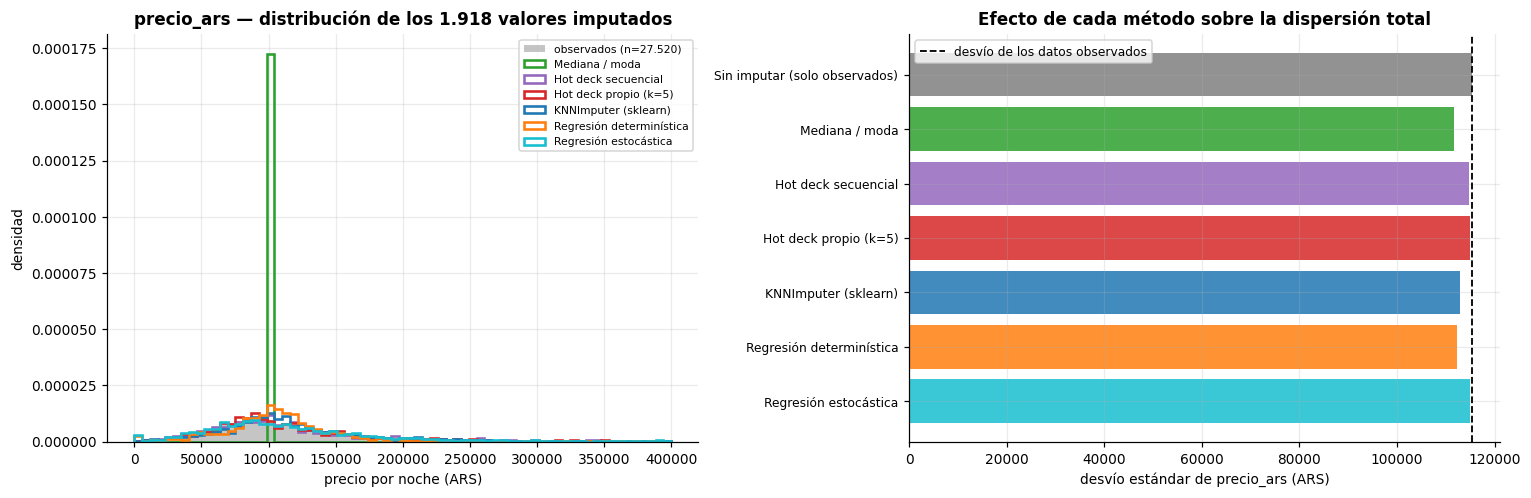

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

# --- precio: densidad de los valores imputados vs observados
m = base["precio_ars"].isna()
bins = np.linspace(0, 400_000, 70)
axes[0].hist(base.loc[~m, "precio_ars"], bins=bins, density=True, color=GRIS, alpha=.45,
             label="observados (n=27.520)")
for nombre, dfi, col in METODOS_TODOS[1:]:
    axes[0].hist(dfi.loc[m, "precio_ars"], bins=bins, density=True, histtype="step",
                 lw=1.7, color=col, label=nombre)
axes[0].set_title("precio_ars — distribución de los 1.918 valores imputados")
axes[0].set_xlabel("precio por noche (ARS)"); axes[0].set_ylabel("densidad")
axes[0].legend(fontsize=7)

# --- desvío estándar del conjunto completo según el método
anchos = [dfi["precio_ars"].std() for _, dfi, _ in METODOS_TODOS]
nombres = [n for n, _, _ in METODOS_TODOS]
cols_ = [c for _, _, c in METODOS_TODOS]
axes[1].barh(nombres[::-1], anchos[::-1], color=cols_[::-1], alpha=.85)
axes[1].axvline(base["precio_ars"].std(), ls="--", color="black", lw=1.2,
                label="desvío de los datos observados")
axes[1].set_xlabel("desvío estándar de precio_ars (ARS)")
axes[1].set_title("Efecto de cada método sobre la dispersión total")
axes[1].tick_params(axis="y", labelsize=8); axes[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

In [62]:
# Prueba objetiva: se ocultan artificialmente valores conocidos y se mide el error de cada método
np.random.seed(123)
completos = base[base["precio_ars"].notna()].copy()
idx_test = completos.sample(1500, random_state=99).index
verdad = completos.loc[idx_test, "precio_ars"].copy()

ensayo = base.copy()
ensayo.loc[idx_test, "precio_ars"] = np.nan

resultados = {}
resultados["Mediana"] = ensayo["precio_ars"].fillna(ensayo["precio_ars"].median())
resultados["Hot deck propio"] = hot_deck(ensayo, "precio_ars", VARS_DIST, VARS_BLOQUE,
                                         k=5, random_state=1, verbose=False)
Xe = pd.concat([ensayo[COLS_KNN], pd.get_dummies(ensayo["tipo_habitacion"], prefix="th").astype(float)], axis=1)
esc2 = StandardScaler(); Xes = esc2.fit_transform(Xe)
Xei = pd.DataFrame(esc2.inverse_transform(KNNImputer(n_neighbors=5, weights="distance").fit_transform(Xes)),
                   columns=Xe.columns, index=Xe.index)
resultados["KNNImputer"] = Xei["precio_ars"]
resultados["Regresión"], _, _, _ = imputar_por_regresion(ensayo, "precio_ars", PRED_NUM, PRED_CAT, log=True)
resultados["Regresión estocástica"], _, _, _ = imputar_por_regresion(ensayo, "precio_ars", PRED_NUM,
                                                                     PRED_CAT, log=True, estocastica=True)

ev = []
for nombre, serie in resultados.items():
    pred = serie.loc[idx_test]
    ev.append({"método": nombre,
               "RMSE": np.sqrt(((pred - verdad) ** 2).mean()),
               "MAE": (pred - verdad).abs().mean(),
               "error relativo medio %": 100 * ((pred - verdad).abs() / verdad).mean(),
               "desvío de lo imputado": pred.std(),
               "desvío real de lo oculto": verdad.std(),
               "correlación con el valor real": pred.corr(verdad)})
pd.DataFrame(ev).set_index("método").round(2)

,RMSE,MAE,error relativo medio %,desvío de lo imputado,desvío real de lo oculto,correlación con el valor real
método,,,,,,
Mediana,"121,391.7300","59,410.9300",46.1000,0.0000,"117,537.5200",NaN
Hot deck propio,"142,451.2200","66,229.8000",53.1000,"113,418.8500","117,537.5200",0.2400
KNNImputer,"100,742.3500","50,512.0200",39.6000,"75,056.3400","117,537.5200",0.5300
Regresión,"102,162.4200","45,919.7900",31.6300,"48,590.8400","117,537.5200",0.5300
Regresión estocástica,"128,473.6900","67,085.6700",56.5400,"102,069.5300","117,537.5200",0.3200


### Respuesta 5.f — Análisis comparado de los métodos

Para no quedarse en la comparación visual, se hizo un **experimento controlado**: se ocultaron
artificialmente 1.500 precios **conocidos**, se aplicaron los cinco métodos y se midió el error
contra el valor verdadero (cuyo desvío real es de $117.538).

| método | RMSE | MAE | error relativo | desvío de lo imputado | correlación con el valor real |
|---|---|---|---|---|---|
| Mediana | 121.392 | 59.411 | 46,1 % | **0** | — |
| Hot deck propio | 142.451 | 66.230 | 53,1 % | **113.419** | 0,24 |
| KNNImputer | **100.742** | 50.512 | 39,6 % | 75.056 | **0,53** |
| Regresión | 102.162 | **45.920** | **31,6 %** | 48.591 | **0,53** |
| Regresión estocástica | 128.474 | 67.086 | 56,5 % | 102.070 | 0,32 |

**El resultado central es que ningún método gana en todo, y los rankings se invierten según el
criterio.** Hay dos objetivos en tensión —acertarle a cada valor y reproducir la distribución del
conjunto— y cada método se ubica en un punto distinto de ese compromiso.

**1. La imputación por medida de tendencia central es la peor opción estructural.** Aunque su
RMSE no es el más alto, **anula por completo la dispersión** (desvío 0 en los valores imputados)
y concentra 1.918 avisos en un único valor, visible como un pico vertical en el histograma. Su
error relativo medio es del 46 %. Su única virtud es la simplicidad, y solo se justifica cuando
el porcentaje de faltantes es marginal — exactamente el caso de `minimo_noches`, con 6 datos.

**2. El hot deck es el que mejor preserva la distribución y el peor en precisión puntual.** El
desvío de sus valores imputados (113.419) es el más cercano al real (117.538), y sobre el
conjunto completo deja el desvío de `precio_ars` en 114.996 contra los 115.303 de los datos
observados: prácticamente intacto. A cambio, su RMSE es el más alto y su correlación con el
valor verdadero es de apenas 0,24, porque el sorteo entre donantes **introduce ruido a
propósito**. No es un defecto del método sino su lógica: el hot deck no intenta predecir cada
valor, intenta que el conjunto imputado se parezca al real.

**3. La regresión es la más precisa punto a punto y la que más distorsiona la dispersión.** El
modelo log-lineal con 60 predictores alcanza un R² fuera de muestra de 0,465, el menor error
absoluto medio de todos los métodos (45.920) y el menor error relativo (31,6 %), con un RMSE
prácticamente empatado con el de KNN. Pero el histograma muestra el problema con nitidez: el
desvío de los valores imputados es de 48.591, **apenas el 41 % del real**. Es la consecuencia
matemática de imputar con la esperanza condicional: al reemplazar cada valor por su predicción
se elimina por construcción toda la varianza residual. Un análisis posterior sobre esos datos
**sobreestimaría la fuerza de las relaciones** y subestimaría los intervalos de confianza.

**4. La regresión estocástica recupera la dispersión perdida.** Al sumar a cada predicción un
residuo sorteado del propio ajuste, el desvío imputado sube de 48.591 a 102.070 —mucho más cerca
del real— y conserva parte de la información del modelo (correlación de 0,32 con el valor
verdadero, contra 0,24 del hot deck). El costo es un RMSE más alto, lógicamente, porque agregó
ruido deliberadamente.

**5. `KNNImputer` resulta el mejor equilibrio general en este dataset**, con el RMSE más bajo y
la correlación más alta junto con la regresión, aunque con un achatamiento de la dispersión
intermedio y la desventaja ya señalada de no respetar el dominio de las variables discretas.

**Una aclaración de escala.** Sobre el conjunto completo las diferencias entre métodos se
diluyen (todos dejan el desvío de `precio_ars` entre 111.700 y 115.000), simplemente porque solo
el 6,5 % de los valores fue imputado. El impacto de la elección **crece proporcionalmente a la
tasa de faltantes**: con `dormitorios`, donde falta el 19,7 %, la correlación con `capacidad`
varía entre 0,342 y 0,584 según el método, una diferencia que sí cambiaría las conclusiones de
cualquier análisis.

**Recomendación final para este dataset.** No hay un método único: corresponde uno por variable,
según su naturaleza y su mecanismo de faltante.

| variable | método recomendado | razón |
|---|---|---|
| `puntaje_resenias` | **no imputar**; variable indicadora | faltante estructural (MAR determinístico) |
| `dormitorios`, `banios`, `camas` | **hot deck** con bloqueo por tipo y barrio | discretas; hay que respetar el dominio |
| `precio_ars` | **regresión estocástica** o imputación múltiple | continua, con buenos predictores disponibles |
| `minimo_noches` | mediana | solo 6 casos, el método es irrelevante |

Y una advertencia que atraviesa todo el ejercicio: **cualquiera de estos métodos supone que el
mecanismo es MAR**. Como en 5.a se planteó que `precio_ars` podría ser MNAR, el resultado debe
reportarse como una estimación condicionada a ese supuesto, idealmente acompañada de un análisis
de sensibilidad. Y en cualquier caso conviene conservar siempre las **columnas indicadoras de
ausencia**: el hecho de que un dato falte es, en este dataset, información en sí misma.

<a id="ej6"></a>

---

# Ejercicio 6 — Análisis de Componentes Principales

**Dataset:** `vehiculos.csv` — 2.809 modelos 2024-2026 comercializados en Estados Unidos, con la
ficha oficial de consumo y emisiones de la EPA (rendimiento urbano/ruta/combinado en MPG, CO₂ por
milla, barriles de petróleo por año, costo anual de combustible, puntaje de gases de efecto
invernadero y ahorro a cinco años).

In [63]:
print(vehiculos.dtypes.to_string())
print(f"\nMarcas: {vehiculos['marca'].nunique()} | Clases: {vehiculos['clase'].nunique()} | "
      f"Combustibles: {vehiculos['combustible'].nunique()}")
print(f"Faltantes: {vehiculos.isna().sum().sum()} "
      f"(en cilindros y cilindrada, {vehiculos['cilindros'].isna().sum()} vehículos)")
vehiculos.head()

marca                         str
modelo                        str
anio                        int64
clase                         str
traccion                      str
combustible                   str
transmision                   str
cilindros                 float64
cilindrada                float64
mpg_ciudad                  int64
mpg_ruta                    int64
mpg_combinado               int64
co2_g_milla               float64
barriles_anio             float64
costo_combustible_anio      int64
puntaje_gei                 int64
ahorro_5anios               int64

Marcas: 42 | Clases: 20 | Combustibles: 9
Faltantes: 24 (en cilindros y cilindrada, 12 vehículos)


,marca,modelo,anio,clase,traccion,combustible,transmision,cilindros,cilindrada,mpg_ciudad,mpg_ruta,mpg_combinado,co2_g_milla,barriles_anio,costo_combustible_anio,puntaje_gei,ahorro_5anios
0,Jaguar,F-Type R AWD Coupe,2024,Two Seaters,All-Wheel Drive,Premium,Automatic (S8),8.0000,5.0000,16,24,18,481.0000,16.5280,4200,4,-10000
1,Jaguar,F-Type R AWD Convertible,2024,Two Seaters,All-Wheel Drive,Premium,Automatic (S8),8.0000,5.0000,16,24,18,481.0000,16.5280,4200,4,-10000
2,Jaguar,F-Type P450 RWD Coupe,2024,Two Seaters,Rear-Wheel Drive,Premium,Automatic (S8),8.0000,5.0000,17,24,19,460.0000,15.6580,4000,4,-9000
3,Jaguar,F-Type P450 RWD Convertible,2024,Two Seaters,Rear-Wheel Drive,Premium,Automatic (S8),8.0000,5.0000,17,24,19,460.0000,15.6580,4000,4,-9000
4,Jaguar,F-Type P450 AWD R-Dynamic Coupe,2024,Two Seaters,All-Wheel Drive,Premium,Automatic (S8),8.0000,5.0000,16,24,18,481.0000,16.5280,4200,4,-10000


In [64]:
# Se trabaja con los atributos cuantitativos; 'anio' se excluye por ser un identificador temporal
VARS_PCA = ["cilindros", "cilindrada", "mpg_ciudad", "mpg_ruta", "mpg_combinado",
            "co2_g_milla", "barriles_anio", "costo_combustible_anio", "puntaje_gei",
            "ahorro_5anios"]

V = vehiculos[VARS_PCA].dropna()
print(f"Matriz de trabajo: {V.shape[0]:,} vehículos x {V.shape[1]} variables "
      f"({vehiculos.shape[0] - V.shape[0]} filas descartadas por faltantes)")
V.describe().T.round(2)

Matriz de trabajo: 2,797 vehículos x 10 variables (12 filas descartadas por faltantes)


,count,mean,std,min,25%,50%,75%,max
cilindros,"2,797.0000",5.3900,1.7500,3.0000,4.0000,4.0000,6.0000,16.0000
cilindrada,"2,797.0000",2.9900,1.1900,1.2000,2.0000,2.7000,3.5000,8.0000
mpg_ciudad,"2,797.0000",21.6500,7.5100,8.0000,17.0000,20.0000,24.0000,57.0000
mpg_ruta,"2,797.0000",27.1800,6.7400,11.0000,22.0000,26.0000,31.0000,58.0000
mpg_combinado,"2,797.0000",23.7200,7.0500,9.0000,19.0000,22.0000,27.0000,57.0000
co2_g_milla,"2,797.0000",395.0200,113.0000,50.0000,321.0000,398.0000,468.0000,979.0000
barriles_anio,"2,797.0000",13.2500,3.8100,1.7200,10.6200,13.5200,15.6600,33.0600
costo_combustible_anio,"2,797.0000","3,169.4700",962.6200,"1,100.0000","2,550.0000","3,100.0000","3,800.0000","8,450.0000"
puntaje_gei,"2,797.0000",4.7200,1.4900,1.0000,4.0000,5.0000,5.0000,10.0000
ahorro_5anios,"2,797.0000","-4,629.9600","4,869.0900","-31,250.0000","-7,250.0000","-4,500.0000","-1,250.0000","7,250.0000"


## 6.a — Matriz de covarianzas

In [65]:
cov = V.cov()
print("MATRIZ DE COVARIANZAS (variables en sus unidades originales)\n")
print(cov.round(1).to_string())
print(f"\nTraza (varianza total) = {np.trace(cov):,.0f}")
print("\nAporte de cada variable a la varianza total:")
aporte = pd.DataFrame({"varianza": np.diag(cov),
                       "% de la traza": 100 * np.diag(cov) / np.trace(cov)},
                      index=VARS_PCA).sort_values("varianza", ascending=False)
print(aporte.round(4).to_string())

MATRIZ DE COVARIANZAS (variables en sus unidades originales)

                         cilindros  cilindrada  mpg_ciudad    mpg_ruta  mpg_combinado   co2_g_milla  barriles_anio  costo_combustible_anio  puntaje_gei   ahorro_5anios
cilindros                   3.1000      1.9000     -7.9000     -7.5000        -7.8000      137.8000         4.7000              1,320.5000      -1.6000     -6,456.6000
cilindrada                  1.9000      1.4000     -5.4000     -5.2000        -5.4000       97.3000         3.3000                856.1000      -1.2000     -4,258.7000
mpg_ciudad                 -7.9000     -5.4000     56.4000     45.7000        52.2000     -703.5000       -23.6000             -6,061.8000       9.2000     30,329.7000
mpg_ruta                   -7.5000     -5.2000     45.7000     45.4000        45.5000     -642.1000       -21.5000             -5,528.4000       8.1000     27,121.4000
mpg_combinado              -7.8000     -5.4000     52.2000     45.5000        49.7000     -681.800

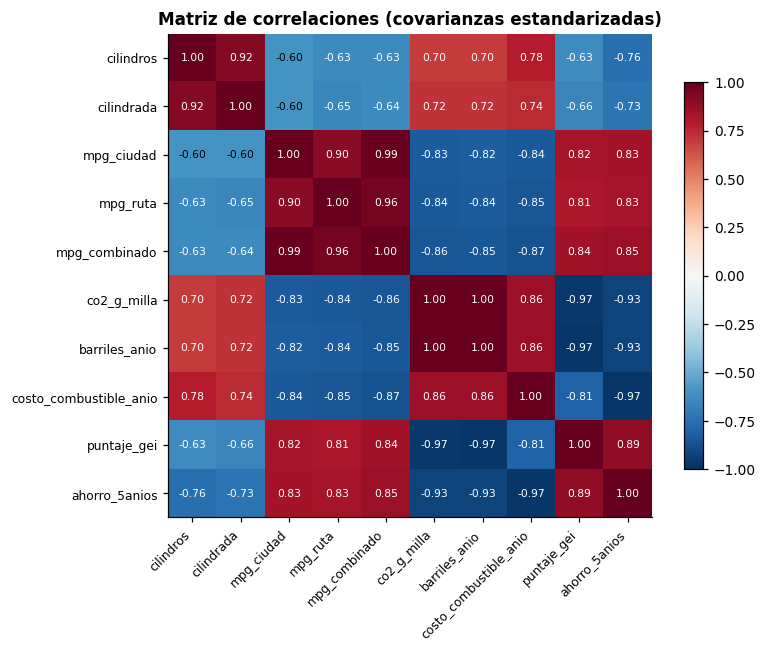

Correlación absoluta media (fuera de la diagonal): 0.809


In [66]:
corr = V.corr()
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(VARS_PCA)), VARS_PCA, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(VARS_PCA)), VARS_PCA, fontsize=8)
for i in range(len(VARS_PCA)):
    for j in range(len(VARS_PCA)):
        ax.text(j, i, f"{corr.values[i,j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.values[i,j]) > .6 else "black")
ax.set_title("Matriz de correlaciones (covarianzas estandarizadas)", fontweight="bold")
ax.grid(False); plt.colorbar(im, shrink=.8)
fig.tight_layout(); plt.show()

print(f"Correlación absoluta media (fuera de la diagonal): "
      f"{np.abs(corr.values[np.triu_indices_from(corr, 1)]).mean():.3f}")

### Respuesta 6.a

**Qué indica la matriz de covarianzas.** Dos cosas, y la primera es un problema metodológico
antes que un hallazgo.

**1. Las escalas son radicalmente incomparables, y eso invalida el uso directo de la matriz de
covarianzas.** La traza (varianza total, 24,6 millones) está dominada por dos
variables: `ahorro_5anios` aporta una varianza de 23,7 millones (**96,19 %** de la traza) y
`costo_combustible_anio` 927 mil (**3,76 %**), que juntas explican el **99,95 %** de la varianza
total del conjunto. En el otro extremo, `cilindrada` aporta 1,4 y `puntaje_gei` 2,2. La diferencia no refleja ninguna propiedad
interesante de los autos: es un simple artefacto de que una variable se mide en dólares y otra
en litros. Si se aplicara PCA sobre esta matriz, la primera componente sería esencialmente
`ahorro_5anios` renombrada, y el análisis no aportaría nada. **Por eso el PCA de los puntos
siguientes se hace sobre variables estandarizadas**, es decir, sobre la matriz de
**correlaciones** —que es la matriz de covarianzas de los datos normalizados por z-score, el
método del Ejercicio 4.b—.

**2. Los atributos están fuertísimamente correlacionados entre sí, y esa es la justificación del
PCA.** La correlación absoluta media entre pares de variables es **0,81**, un valor altísimo: no
hay prácticamente ninguna variable independiente de las demás. El mapa de calor revela una
estructura muy nítida, con dos bloques de signo opuesto:

- **Bloque "eficiencia"**: `mpg_ciudad`, `mpg_ruta`, `mpg_combinado`, `puntaje_gei` y
  `ahorro_5anios`, todos correlacionados positivamente entre sí (hasta r = 0,99 entre
  `mpg_ciudad` y `mpg_combinado`).
- **Bloque "consumo y potencia"**: `cilindros`, `cilindrada`, `co2_g_milla`, `barriles_anio` y
  `costo_combustible_anio`, también correlacionados positivamente entre sí (r = 0,99 entre
  `co2_g_milla` y `barriles_anio`; r = 0,92 entre `cilindros` y `cilindrada`).
- Y los dos bloques están **correlacionados negativamente entre sí** (r = −0,96 entre
  `puntaje_gei` y `co2_g_milla`).

Varias de esas correlaciones extremas son **redundancias casi deterministas**, no hallazgos
empíricos: `mpg_combinado` es por definición un promedio ponderado de `mpg_ciudad` y `mpg_ruta`;
`barriles_anio` y `co2_g_milla` se calculan ambas a partir del consumo, y por eso su correlación
es 0,99. El dataset tiene diez columnas pero **mucha menos información que diez dimensiones**:
está midiendo una y otra vez el mismo fenómeno subyacente. Eso es exactamente lo que el análisis
de componentes principales está diseñado para detectar y resumir.

## 6.b — Análisis de componentes principales

In [67]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

Z = StandardScaler().fit_transform(V)              # estandarización previa (z-score)
pca = PCA().fit(Z)

autovalores = pca.explained_variance_
prop = pca.explained_variance_ratio_

tabla_pca = pd.DataFrame({
    "auto-valor": autovalores,
    "% de varianza explicada": 100 * prop,
    "% acumulado": 100 * np.cumsum(prop),
}, index=[f"PC{i}" for i in range(1, len(prop) + 1)])
tabla_pca.round(3)

,auto-valor,% de varianza explicada,% acumulado
PC1,8.3130,83.1020,83.1020
PC2,0.8270,8.2680,91.3700
PC3,0.4260,4.2580,95.6280
PC4,0.2210,2.2130,97.8410
PC5,0.1040,1.0410,98.8810
PC6,0.0680,0.6800,99.5620
PC7,0.0320,0.3220,99.8840
PC8,0.0060,0.0590,99.9430
PC9,0.0040,0.0430,99.9850
PC10,0.0010,0.0150,100.0000


In [68]:
print(f"Suma de los auto-valores = {autovalores.sum():.2f}  "
      f"(igual a la cantidad de variables, porque se estandarizó)\n")
print(f"Primer auto-valor (PC1)          : {autovalores[0]:.4f}")
print(f"Varianza explicada por PC1       : {100*prop[0]:.2f} %")
print(f"Varianza explicada por PC1 + PC2 : {100*prop[:2].sum():.2f} %")
print(f"Varianza explicada por PC1+PC2+PC3: {100*prop[:3].sum():.2f} %")
print(f"\nComponentes con auto-valor > 1 (criterio de Kaiser): {(autovalores > 1).sum()}")
print(f"Componentes necesarias para llegar al 90 % : "
      f"{np.argmax(np.cumsum(prop) >= .90) + 1}")
print(f"Componentes necesarias para llegar al 95 % : "
      f"{np.argmax(np.cumsum(prop) >= .95) + 1}")

Suma de los auto-valores = 10.00  (igual a la cantidad de variables, porque se estandarizó)

Primer auto-valor (PC1)          : 8.3132
Varianza explicada por PC1       : 83.10 %
Varianza explicada por PC1 + PC2 : 91.37 %
Varianza explicada por PC1+PC2+PC3: 95.63 %

Componentes con auto-valor > 1 (criterio de Kaiser): 1
Componentes necesarias para llegar al 90 % : 2
Componentes necesarias para llegar al 95 % : 3


### Respuesta 6.b

- **La primera componente explica el 83,10 % de la variación total del dataset.** Un valor
  excepcionalmente alto, coherente con la correlación media de 0,83 observada en 6.a: cuando
  todas las variables se mueven juntas, un solo eje alcanza para representarlas.
- **Incorporando la segunda se llega al 91,37 %** (PC2 aporta 8,27 puntos adicionales). Con dos
  de las diez dimensiones originales se retiene más del 90 % de la información: una **reducción
  de dimensionalidad del 80 % con una pérdida menor al 9 %**.
- **El primer auto-valor vale 8,3132.** Su interpretación es directa y depende de haber
  estandarizado: como cada variable normalizada aporta exactamente 1 unidad de varianza, la suma
  de los diez auto-valores es 10, y un auto-valor de 8,31 significa que **la primera componente
  concentra tanta varianza como 8,31 de las variables originales juntas**. Dicho de otro modo,
  de las diez variables medidas, solo 1,69 unidades de varianza son ajenas a ese eje común. Es
  también por esto que 8,3132 / 10 = 83,10 %, el porcentaje del primer punto.

Vale la pena notar que la caída entre el primer y el segundo auto-valor es de un orden de
magnitud (8,31 → 0,83), y que a partir de PC4 los auto-valores son ya inferiores a 0,25: el
dataset es, en los hechos, **casi unidimensional**.

## 6.c — Perfil de variación de las componentes

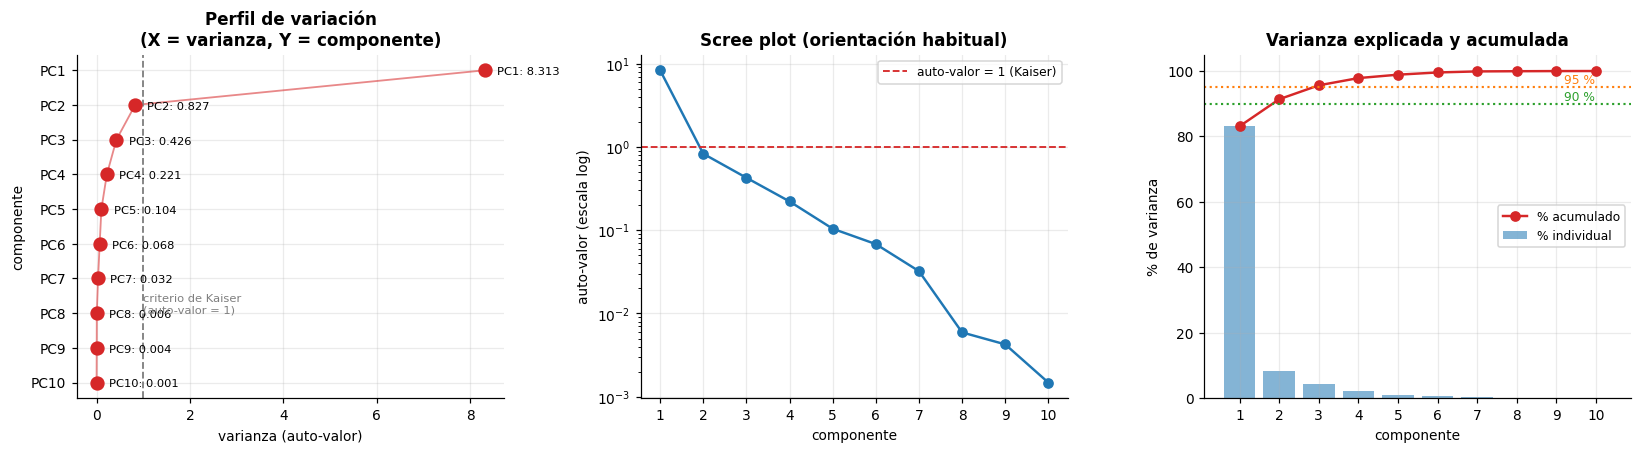

In [69]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

# Gráfico pedido: X = varianza, Y = componente
axes[0].scatter(autovalores, range(1, len(autovalores) + 1), s=70, color=ROJO, zorder=3)
axes[0].plot(autovalores, range(1, len(autovalores) + 1), lw=1.2, color=ROJO, alpha=.55)
for i, a in enumerate(autovalores, 1):
    axes[0].annotate(f"PC{i}: {a:.3f}", (a, i), textcoords="offset points",
                     xytext=(8, -3), fontsize=7.5)
axes[0].axvline(1, ls="--", color=GRIS, lw=1.2)
axes[0].annotate("criterio de Kaiser\n(auto-valor = 1)", (1, 8), fontsize=7.5, color=GRIS)
axes[0].invert_yaxis()
axes[0].set_xlabel("varianza (auto-valor)"); axes[0].set_ylabel("componente")
axes[0].set_yticks(range(1, 11), [f"PC{i}" for i in range(1, 11)])
axes[0].set_title("Perfil de variación\n(X = varianza, Y = componente)")

# Scree plot en la orientación habitual, con escala logarítmica
axes[1].plot(range(1, 11), autovalores, "o-", color=AZUL, lw=1.6)
axes[1].axhline(1, ls="--", color=ROJO, lw=1.2, label="auto-valor = 1 (Kaiser)")
axes[1].set_yscale("log"); axes[1].set_xticks(range(1, 11))
axes[1].set_xlabel("componente"); axes[1].set_ylabel("auto-valor (escala log)")
axes[1].set_title("Scree plot (orientación habitual)"); axes[1].legend(fontsize=8)

# Varianza acumulada
axes[2].bar(range(1, 11), 100 * prop, color=AZUL, alpha=.55, label="% individual")
axes[2].plot(range(1, 11), 100 * np.cumsum(prop), "o-", color=ROJO, lw=1.6, label="% acumulado")
axes[2].axhline(90, ls=":", color=VERDE, lw=1.4); axes[2].axhline(95, ls=":", color=NARANJA, lw=1.4)
axes[2].annotate("90 %", (9.2, 91), fontsize=8, color=VERDE)
axes[2].annotate("95 %", (9.2, 96), fontsize=8, color=NARANJA)
axes[2].set_xticks(range(1, 11)); axes[2].set_xlabel("componente")
axes[2].set_ylabel("% de varianza"); axes[2].set_title("Varianza explicada y acumulada")
axes[2].legend(fontsize=8, loc="center right")
fig.tight_layout(); plt.show()

### Respuesta 6.c

El perfil muestra un **codo extremadamente pronunciado en la primera componente**. La caída de
PC1 (8,31) a PC2 (0,83) es de un factor de diez, y de PC2 a PC3 (0,43) de un factor de dos; a
partir de ahí la curva es prácticamente plana y se arrastra hacia cero. En escala logarítmica se
ve además un segundo quiebre entre PC7 y PC8: los últimos tres auto-valores son del orden de
10⁻³, es decir, **direcciones de varianza esencialmente nula**. Esas componentes finales
corresponden a las relaciones casi deterministas detectadas en 6.a (por ejemplo, el hecho de que
`mpg_combinado` sea función de `mpg_ciudad` y `mpg_ruta` genera una combinación lineal de
varianza casi cero), y confirman que el dataset tiene **redundancia algebraica**, no solo
estadística.

La línea de referencia en auto-valor = 1 (criterio de Kaiser) es atravesada por una sola
componente.

## 6.d — Matriz de *loadings*

In [70]:
# Loadings = correlación entre cada variable original y cada componente
cargas = pd.DataFrame(
    pca.components_[:4].T * np.sqrt(autovalores[:4]),
    index=VARS_PCA, columns=[f"PC{i}" for i in range(1, 5)]
)
cargas["comunalidad (PC1-PC2)"] = (cargas["PC1"]**2 + cargas["PC2"]**2)
cargas.style.background_gradient(cmap="RdBu_r", vmin=-1, vmax=1,
                                 subset=["PC1", "PC2", "PC3", "PC4"]).format("{:.3f}")

,PC1,PC2,PC3,PC4,comunalidad (PC1-PC2)
cilindros,-0.798,0.562,0.101,0.002,0.953
cilindrada,-0.802,0.543,0.054,-0.175,0.938
mpg_ciudad,0.907,0.279,-0.239,0.060,0.901
mpg_ruta,0.916,0.201,-0.234,0.093,0.879
mpg_combinado,0.935,0.248,-0.238,0.066,0.936
co2_g_milla,-0.958,-0.076,-0.254,-0.058,0.923
barriles_anio,-0.956,-0.070,-0.266,-0.048,0.919
costo_combustible_anio,-0.943,0.054,0.097,0.306,0.891
puntaje_gei,0.926,0.149,0.299,0.099,0.879
ahorro_5anios,0.960,-0.013,0.100,-0.255,0.921


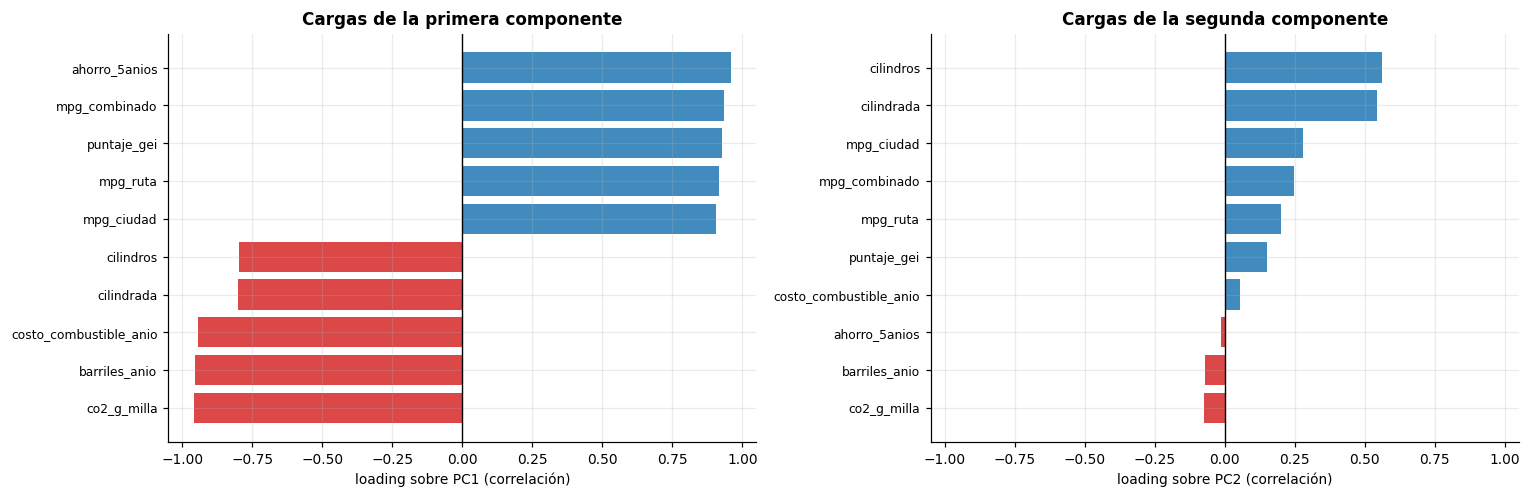

Variables con |loading| > 0.9 sobre PC1:
ahorro_5anios             0.9600
co2_g_milla              -0.9580
barriles_anio            -0.9560
costo_combustible_anio   -0.9430
mpg_combinado             0.9350
puntaje_gei               0.9260
mpg_ruta                  0.9160
mpg_ciudad                0.9070


In [71]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

orden = cargas["PC1"].sort_values().index
axes[0].barh(orden, cargas.loc[orden, "PC1"],
             color=[ROJO if v < 0 else AZUL for v in cargas.loc[orden, "PC1"]], alpha=.85)
axes[0].axvline(0, color="black", lw=.9)
axes[0].set_xlim(-1.05, 1.05); axes[0].set_xlabel("loading sobre PC1 (correlación)")
axes[0].set_title("Cargas de la primera componente")
axes[0].tick_params(axis="y", labelsize=8)

orden2 = cargas["PC2"].sort_values().index
axes[1].barh(orden2, cargas.loc[orden2, "PC2"],
             color=[ROJO if v < 0 else AZUL for v in cargas.loc[orden2, "PC2"]], alpha=.85)
axes[1].axvline(0, color="black", lw=.9)
axes[1].set_xlim(-1.05, 1.05); axes[1].set_xlabel("loading sobre PC2 (correlación)")
axes[1].set_title("Cargas de la segunda componente")
axes[1].tick_params(axis="y", labelsize=8)
fig.tight_layout(); plt.show()

print("Variables con |loading| > 0.9 sobre PC1:")
print(cargas.loc[cargas["PC1"].abs() > .9, "PC1"].sort_values(key=abs, ascending=False).round(3).to_string())

### Respuesta 6.d

**Qué información provee la matriz de *loadings*.** Los *loadings* son la **correlación entre
cada variable original y cada componente**; se obtienen multiplicando el auto-vector por la raíz
del auto-valor correspondiente. Cumplen tres funciones:

1. **Interpretan las componentes**, que de otro modo son ejes abstractos sin nombre. El signo
   indica el sentido de la relación y la magnitud (entre −1 y 1) su intensidad.
2. **Cuantifican cuánta información de cada variable retiene el modelo reducido.** La suma de los
   cuadrados de los *loadings* de una variable sobre las componentes conservadas es su
   **comunalidad**: aquí, con solo PC1 y PC2, todas las variables tienen comunalidad superior a
   0,90 salvo `costo_combustible_anio` (0,89), lo que significa que ninguna queda mal
   representada.
3. **Permiten detectar redundancia**: variables con *loadings* casi idénticos sobre todas las
   componentes son intercambiables.

**Qué variables están más correlacionadas con la primera componente.** Prácticamente **todas**
—los diez *loadings* superan 0,79 en valor absoluto—, pero las más fuertes son:

| variable | *loading* sobre PC1 |
|---|---|
| `ahorro_5anios` | **+0,960** |
| `co2_g_milla` | **−0,958** |
| `barriles_anio` | **−0,956** |
| `costo_combustible_anio` | **−0,943** |
| `mpg_combinado` | **+0,935** |
| `puntaje_gei` | +0,926 |
| `mpg_ruta` | +0,916 |
| `mpg_ciudad` | +0,907 |
| `cilindrada` | −0,802 |
| `cilindros` | −0,798 |

**PC1 es un eje de eficiencia energética.** Carga **positivamente** sobre todo lo bueno para el
bolsillo y el ambiente (ahorro a cinco años, millas por galón, puntaje de gases de efecto
invernadero) y **negativamente** sobre todo lo que implica consumir más (emisiones de CO₂,
barriles de petróleo por año, costo anual de combustible, cilindrada y cantidad de cilindros).
Un vehículo con puntaje alto en PC1 es un auto chico y económico; uno con puntaje muy negativo
es una camioneta o un deportivo de motor grande. Es notable que un solo número resuma tan bien
la ficha técnica completa: **el 83 % de lo que diferencia a un modelo de otro, en esta tabla de
la EPA, es simplemente cuánto combustible quema**.

**PC2 separa la cilindrada del rendimiento.** Sus cargas dominantes son `cilindros` (+0,562) y
`cilindrada` (+0,543), con el resto de las variables cerca de cero. Como PC2 es ortogonal a PC1,
lo que mide es la porción de la mecánica del motor **que no queda explicada por el consumo**: es
decir, distingue a los vehículos cuyo tamaño de motor es alto o bajo *para el nivel de eficiencia
que tienen*. Puntaje alto en PC2 identifica motores grandes que consumen menos de lo que su
cilindrada haría esperar (motores modernos turboalimentados, híbridos de gran porte); puntaje
bajo, motores chicos con consumo desproporcionado. Es un eje de **eficiencia tecnológica
relativa**, y explica solo el 8,3 % de la variación.

## 6.e — *Biplot*

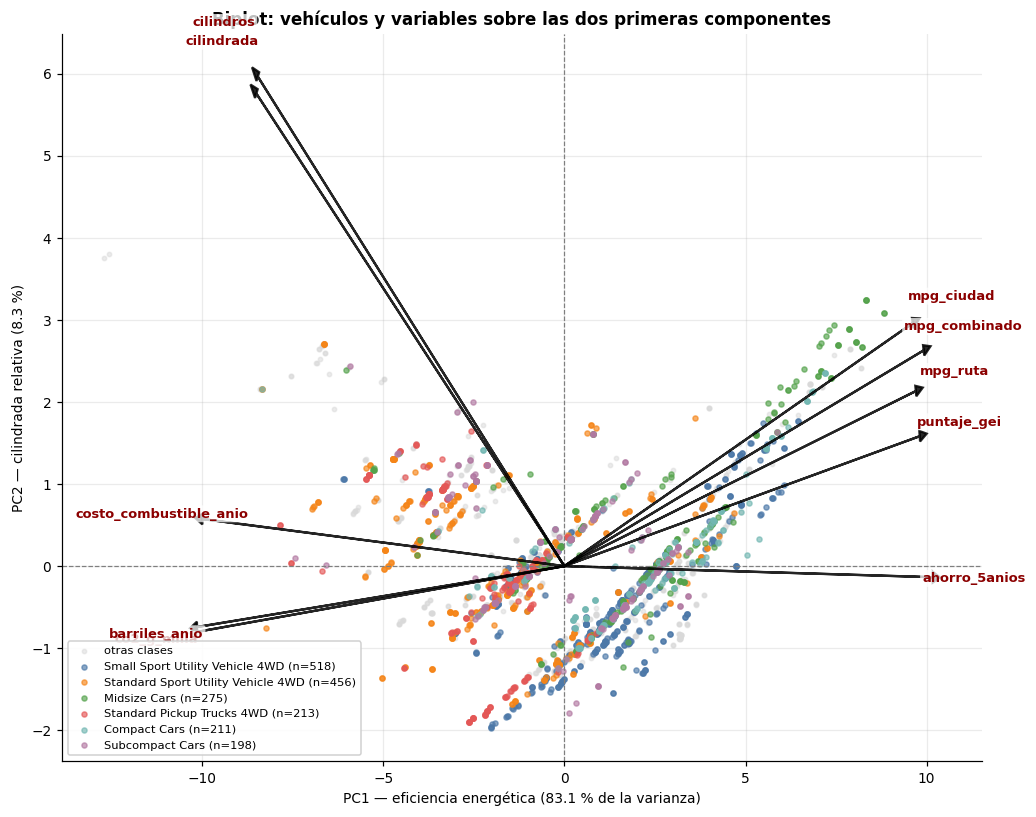

In [72]:
puntajes = pca.transform(Z)
clase_veh = vehiculos.loc[V.index, "clase"]
top_clases = clase_veh.value_counts().head(6).index
paleta = dict(zip(top_clases, ["#4c78a8", "#f58518", "#54a24b", "#e45756", "#72b7b2", "#b279a2"]))

fig, ax = plt.subplots(figsize=(9.5, 7.5))

# --- Puntajes de los vehículos (proyección sobre PC1-PC2)
otros = ~clase_veh.isin(top_clases)
ax.scatter(puntajes[otros.values, 0], puntajes[otros.values, 1], s=8, color="#d9d9d9",
           alpha=.5, label="otras clases", zorder=1)
for cl in top_clases:
    m = (clase_veh == cl).values
    ax.scatter(puntajes[m, 0], puntajes[m, 1], s=11, alpha=.65, color=paleta[cl],
               label=f"{cl} (n={m.sum()})", zorder=2)

# --- Vectores de las variables, escalados al espacio de los puntajes
escala = np.abs(puntajes[:, :2]).max() * .85
for i, v in enumerate(VARS_PCA):
    x, y = cargas.iloc[i, 0] * escala, cargas.iloc[i, 1] * escala
    ax.arrow(0, 0, x, y, color="black", lw=1.5, head_width=.13, alpha=.85, zorder=4,
             length_includes_head=True)
    ax.text(x * 1.09, y * 1.09, v, fontsize=8.5, fontweight="bold", color="#8B0000",
            ha="center", va="center", zorder=5,
            bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=.75))

ax.axhline(0, color=GRIS, lw=.8, ls="--"); ax.axvline(0, color=GRIS, lw=.8, ls="--")
ax.set_xlabel(f"PC1 — eficiencia energética ({100*prop[0]:.1f} % de la varianza)")
ax.set_ylabel(f"PC2 — cilindrada relativa ({100*prop[1]:.1f} %)")
ax.set_title("Biplot: vehículos y variables sobre las dos primeras componentes", fontweight="bold")
ax.legend(fontsize=7.5, loc="lower left", framealpha=.9)
fig.tight_layout(); plt.show()

In [73]:
# Lectura del biplot: los extremos de PC1
pc1 = pd.Series(puntajes[:, 0], index=V.index)
extremos = pd.concat([
    vehiculos.loc[pc1.nsmallest(5).index, ["marca", "modelo", "cilindrada", "mpg_combinado", "co2_g_milla"]]
        .assign(PC1=pc1.nsmallest(5).round(2), extremo="menos eficientes"),
    vehiculos.loc[pc1.nlargest(5).index, ["marca", "modelo", "cilindrada", "mpg_combinado", "co2_g_milla"]]
        .assign(PC1=pc1.nlargest(5).round(2), extremo="más eficientes"),
])
extremos.set_index(["extremo", "marca"])

modelo  cilindrada  mpg_combinado  co2_g_milla      PC1
extremo          marca                                                                           
menos eficientes Bugatti      Chiron Super Sport      8.0000              9     979.0000 -12.7100
                 Bugatti                 Mistral      8.0000              9     943.0000 -12.5600
                 Lamborghini            Revuelto      6.5000             12     753.0000  -8.4100
                 Lamborghini            Revuelto      6.5000             12     753.0000  -8.4100
                 Ferrari              Purosangue      6.5000             12     711.0000  -8.3400
más eficientes   Toyota           Prius Prime SE      2.0000             52      50.0000   8.8300
                 Toyota            Prius PHEV SE      2.0000             52      50.0000   8.8300
                 Toyota                    Prius      2.0000             57     155.0000   8.3300
                 Toyota                    Prius      2.0000             57     155.0000   8.3300
                 Toyota                    Prius      2.0000             57     155.0000   8.3300

### Respuesta 6.e

**Qué información provee el biplot.** Superpone en un mismo plano dos cosas que normalmente se
miran por separado: los **2.797 vehículos** proyectados sobre PC1-PC2 (los puntos) y las **diez
variables originales** representadas como vectores (las flechas). Eso permite leer
simultáneamente tres relaciones distintas:

**1. Entre variables (ángulos entre flechas).** El coseno del ángulo entre dos vectores aproxima
su correlación. El gráfico muestra dos haces de flechas casi superpuestas y apuntando en
sentidos opuestos: hacia la derecha, el paquete de la eficiencia (`mpg_ciudad`, `mpg_ruta`,
`mpg_combinado`, `puntaje_gei`, `ahorro_5anios`), con ángulos casi nulos entre sí —correlaciones
cercanas a 1—; hacia la izquierda, el paquete del consumo (`co2_g_milla`, `barriles_anio`,
`costo_combustible_anio`) más arriba-izquierda los de motor (`cilindros`, `cilindrada`). Los
ángulos de casi 180° entre ambos haces corresponden a las correlaciones de −0,96. La longitud de
cada flecha indica qué tan bien representada está la variable en este plano: todas son largas,
lo que confirma las comunalidades altas del punto 6.d.

**2. Entre observaciones (posición de los puntos).** Los vehículos cercanos entre sí tienen
perfiles de consumo similares. La nube se ordena de izquierda a derecha por eficiencia, y al
colorear por clase de vehículo aparece una **separación limpia que el PCA descubrió sin
conocerla**. Los promedios de PC1 por clase lo resumen: *Two Seaters* (−2,46), *Standard Pickup
Trucks 4WD* (−2,44) y *Standard Sport Utility Vehicle 4WD* (−1,74) quedan a la izquierda, del
lado del alto consumo; *Small Sport Utility Vehicle 2WD* (+2,35), *Midsize Cars* (+2,06) y
*Compact Cars* (+1,85) a la derecha, del lado de la eficiencia. Vale notar que la separación
**no es por carrocería sino por consumo**: los SUV chicos caen del lado eficiente y los grandes
del lado opuesto, pese a compartir categoría. Los *Two Seaters*, además, tienen PC2 positivo
(+0,26): son deportivos cuya cilindrada es aún más alta de lo que su consumo por sí solo haría
esperar.

**3. Entre observaciones y variables (proyección de un punto sobre una flecha).** Proyectando un
vehículo sobre el eje de una flecha se estima su valor en esa variable. La tabla de extremos lo
verifica: los cinco puntajes más bajos de PC1 son superdeportivos de 6,5 a 8,0 litros con 9 a 12
MPG y entre 711 y 979 g de CO₂ por milla (dos Bugatti, dos Lamborghini y un Ferrari); los cinco
más altos son híbridos Toyota Prius de 2,0 litros con 52 a 57 MPG y apenas 50 a 155 g de CO₂. **Un único número —la coordenada sobre PC1— ordena correctamente todo el catálogo
automotor de Estados Unidos por eficiencia**, sin que se le haya dado ninguna definición previa
de qué significa "eficiente".

## 6.f — ¿Cuántas componentes principales elegir?

In [74]:
from sklearn.metrics import mean_squared_error

# Criterios formales
kaiser = int((autovalores > 1).sum())
c90 = int(np.argmax(np.cumsum(prop) >= .90) + 1)
c95 = int(np.argmax(np.cumsum(prop) >= .95) + 1)

# Error de reconstrucción: cuánto se pierde al volver del espacio reducido al original
errores = []
for k in range(1, 11):
    p = PCA(n_components=k).fit(Z)
    rec = p.inverse_transform(p.transform(Z))
    errores.append({"componentes": k,
                    "% varianza retenida": 100 * p.explained_variance_ratio_.sum(),
                    "RMSE de reconstrucción": np.sqrt(mean_squared_error(Z, rec)),
                    "auto-valor": autovalores[k-1]})
err = pd.DataFrame(errores).set_index("componentes")

print(f"Criterio de Kaiser (auto-valor > 1) : {kaiser} componente(s)")
print(f"Umbral del 90 % de varianza         : {c90} componentes")
print(f"Umbral del 95 % de varianza         : {c95} componentes")
print(f"Codo del scree plot                 : 2 componentes\n")
err.round(3)

Criterio de Kaiser (auto-valor > 1) : 1 componente(s)
Umbral del 90 % de varianza         : 2 componentes
Umbral del 95 % de varianza         : 3 componentes
Codo del scree plot                 : 2 componentes



,% varianza retenida,RMSE de reconstrucción,auto-valor
componentes,,,
1,83.1020,0.4110,8.3130
2,91.3700,0.2940,0.8270
3,95.6280,0.2090,0.4260
4,97.8410,0.1470,0.2210
5,98.8810,0.1060,0.1040
6,99.5620,0.0660,0.0680
7,99.8840,0.0340,0.0320
8,99.9430,0.0240,0.0060
9,99.9850,0.0120,0.0040


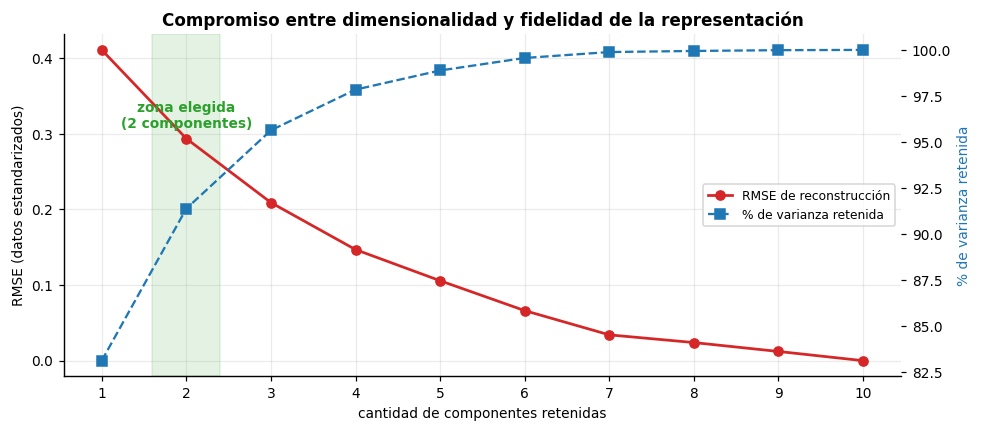

In [75]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(err.index, err["RMSE de reconstrucción"], "o-", color=ROJO, lw=1.8,
        label="RMSE de reconstrucción")
ax.set_xlabel("cantidad de componentes retenidas"); ax.set_ylabel("RMSE (datos estandarizados)")
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(err.index, err["% varianza retenida"], "s--", color=AZUL, lw=1.5,
         label="% de varianza retenida")
ax2.set_ylabel("% de varianza retenida", color=AZUL)
ax.axvspan(1.6, 2.4, color=VERDE, alpha=.13)
ax.annotate("zona elegida\n(2 componentes)", (2, err["RMSE de reconstrucción"].max()*.75),
            ha="center", fontsize=9, color=VERDE, fontweight="bold")
ax.set_xticks(range(1, 11))
ax.set_title("Compromiso entre dimensionalidad y fidelidad de la representación", fontweight="bold")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="center right")
fig.tight_layout(); plt.show()

### Respuesta 6.f

**Se eligen dos componentes principales.** La justificación combina los cuatro criterios
habituales, que en este caso no coinciden entre sí y por eso hay que argumentar la decisión.

**Qué dice cada criterio:**

| criterio | resultado | lectura |
|---|---|---|
| Kaiser (auto-valor > 1) | **1** componente | solo PC1 supera el umbral (8,31); PC2 vale 0,83 |
| Codo del *scree plot* | **2** componentes | el quiebre está entre PC2 y PC3 |
| 90 % de varianza | **2** componentes | PC1+PC2 = 91,37 % |
| 95 % de varianza | **3** componentes | PC1+PC2+PC3 = 95,63 % |

**Por qué dos y no una.** El criterio de Kaiser es el más restrictivo y, tomado literalmente,
indicaría quedarse solo con PC1. Hay tres razones para no seguirlo aquí:

1. PC2 tiene un auto-valor de 0,827, **apenas por debajo del umbral**, y el criterio de Kaiser es
   una regla práctica, no un test estadístico; descartar por un margen del 17 % es arbitrario.
2. PC2 es **interpretable y aporta información sustantiva**: como se vio en 6.d, aísla la
   cilindrada del motor del nivel de consumo, que es una dimensión mecánicamente distinta de la
   eficiencia pura. Una componente que tiene sentido físico y carga fuerte sobre dos variables
   específicas merece conservarse aunque su auto-valor sea marginal.
3. Con una sola componente, `cilindros` y `cilindrada` quedarían representadas con comunalidad
   0,64 —el peor caso del conjunto—, mientras que al incorporar PC2 sube a **0,95**. PC2 es,
   precisamente, la componente que rescata a esas dos variables.

**Por qué dos y no tres.** PC3 aporta 4,26 puntos adicionales de varianza para llegar al 95,6 %,
pero su auto-valor (0,426) es **menos de la mitad** del umbral de Kaiser, sus *loadings* están
repartidos débilmente entre muchas variables sin un patrón interpretable, y todas las variables
ya alcanzan comunalidades superiores a 0,89 con dos componentes. Retenerla agregaría una
dimensión difícil de nombrar a cambio de una mejora marginal: el RMSE de reconstrucción baja de
0,29 a 0,21, una diferencia que no cambia ninguna conclusión práctica.

**Conclusión.** Dos componentes retienen el **91,4 % de la variación** con una **reducción de
dimensionalidad del 80 %** (de 10 variables a 2), ambas son interpretables —PC1 como eficiencia
energética global y PC2 como cilindrada relativa al consumo—, y juntas permiten representar todo
el conjunto de datos en un único gráfico bidimensional, como se vio en el biplot. Es el mejor
punto del compromiso entre parsimonia y fidelidad para este dataset.

<a id="conclusiones"></a>

---

# Conclusiones generales

El trabajo recorrió las principales técnicas de preprocesamiento sobre cuatro conjuntos de datos
reales, y hay tres ideas que atraviesan los seis ejercicios.

**1. Ningún procedimiento de preprocesamiento es automático ni neutro.** Cada técnica esconde un
parámetro cuya elección cambia el resultado y que no se deduce de los datos: el número de bins
(Ej. 1), el criterio para etiquetar un outlier (Ej. 2), los puntos de corte de la discretización
(Ej. 3), el método de normalización (Ej. 4), el supuesto sobre el mecanismo de los faltantes
(Ej. 5) y la cantidad de componentes a retener (Ej. 6). En todos los casos la respuesta correcta
dependió del **objetivo del análisis posterior**, no de una regla universal — y por eso toda
decisión de preprocesamiento debe explicitarse y justificarse junto con los resultados.

**2. El contexto del dominio decide más que el estadístico.** Es la lección que se repitió con
más fuerza. Un pico de 23 ppm de CO fue ruido instrumental (Ej. 1) mientras que 844 presiones
atípicas fueron registros perfectamente válidos de la Antártida (Ej. 2); un valor de 990 en la
dirección del viento no era un outlier sino un código; la ausencia del puntaje de reseñas no era
un dato perdido sino una imposibilidad lógica (Ej. 5). En los cuatro casos, el criterio numérico
—el IQR, el z-score, el porcentaje de faltantes— señaló correctamente **dónde mirar**, pero fue
el conocimiento del dominio el que determinó **qué hacer**. Aplicar las reglas mecánicamente
(eliminar todo lo que caiga fuera de los bigotes, imputar todo faltante con la media) habría
destruido información en todos los casos.

**3. Hay un compromiso recurrente entre precisión y fidelidad estructural.** Apareció con la
misma forma en tres ejercicios distintos: en el binning, entre reducir ruido y conservar señal;
en la imputación, entre minimizar el error puntual (regresión) y preservar la distribución (hot
deck); en el PCA, entre parsimonia y varianza retenida. Las soluciones que mejor funcionaron
fueron siempre las intermedias —la regresión estocástica, el hot deck con sorteo entre k
donantes, las dos componentes principales—, porque reconocen que **reducir la variabilidad de
los datos no es lo mismo que reducir su ruido**.

Sobre los resultados concretos: el dataset de calidad del aire mostró distribuciones asimétricas
con un caso claro de error de medición; el del SMN resultó ser una mezcla de poblaciones
climáticas cuya heterogeneidad explica todos sus outliers; el de alquileres presentó un
mecanismo de faltantes claramente MAR, con sospecha de MNAR en el precio, que hace inadmisible
el descarte de casos; y el de vehículos resultó ser casi unidimensional, con el 83 % de su
variación resumida en un único eje de eficiencia energética.

---

## Referencias

- Abdi, H. y Williams, L. J. (2010). *Principal component analysis*. Wiley Interdisciplinary
  Reviews: Computational Statistics, 2(4), 433-459.
- Brown, M. L. y Kros, J. F. (2003). *Data mining and the impact of missing data*. Industrial
  Management & Data Systems, 103(8), 611-621.
- Han, J., Kamber, M. y Pei, J. (2006). *Data Mining: Concepts and Techniques* (2ª ed.). Morgan
  Kaufmann. Capítulo 2: Data Preprocessing.
- Little, R. J. A. y Rubin, D. B. (2019). *Statistical Analysis with Missing Data* (3ª ed.). Wiley.
- Tukey, J. W. (1977). *Exploratory Data Analysis*. Addison-Wesley.

**Fuentes de los datos**

- Agencia de Protección Ambiental, GCBA — <https://data.buenosaires.gob.ar/dataset/calidad-aire>
- Servicio Meteorológico Nacional — <https://www.smn.gob.ar/descarga-de-datos>
- Inside Airbnb — <https://insideairbnb.com/get-the-data/>
- U.S. EPA / Department of Energy — <https://www.fueleconomy.gov/feg/download.shtml>